## Executive Summary: Profit-Driven Lead Optimization

---

### Project Objective
Maximize the Total Expected Profit for Period 5 by selecting the most valuable **1,200 leads**.

---

### Strategy - Willingness × Wealth
Instead of maximizing prediction accuracy, we deployed a **Hurdle Model** approach:

| Stage | Model | Task |
|---|---|---|
| Stage 1 - Willingness | Calibrated Random Forest | Identifies clients likely to invest |
| Stage 2 - Wealth | Lasso Regressor | Estimates potential investment volume |

---

### Financial Constraints
| Parameter | Value |
|---|---|
| Margin | 4.5% commission on investment |
| Cost per Contact | €5.00 fixed cost |
| Max Outreach Capacity | 1,200 clients |

---

### Business Result
Our engine identified **885 leads** with a positive Expected Value (EV > 0), yielding a projected:

> ### Total Profit: €5,990.10

In [1]:
# =============================================================================
# 0. BUSINESS CONFIGURATION
# =============================================================================

# These constants govern the Expected Value (EV) engine throughout the notebook
MARGIN = 0.045         # 4.5% Commission
CONTACT_COST = 5.00    # €5.00 per contact
MAX_CAPACITY = 1200    # Maximum number of clients we can contact

#  1. Load Library and Combine the Data

In [2]:
# --- 1. General Data Handling & Visualization ---
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
import IPython.display
from sklearn.exceptions import ConvergenceWarning
from sklearn.calibration import calibration_curve

# Ignore ConvergenceWarnings for cleaner output during GridSearch
warnings.filterwarnings("ignore", category=ConvergenceWarning)

# --- 2. Sklearn: Core Utilities & Pipelines ---
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, make_column_selector, TransformedTargetRegressor
from sklearn.preprocessing import FunctionTransformer

# --- 3. Sklearn: Preprocessing & Feature Engineering ---
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PolynomialFeatures
from sklearn.feature_selection import VarianceThreshold, SelectKBest, f_classif
from sklearn.decomposition import PCA

# --- 4. Sklearn: Model Selection & Validation ---
from sklearn.model_selection import (
    train_test_split, GridSearchCV, RandomizedSearchCV, 
    cross_val_score, cross_validate, KFold, StratifiedKFold
)

# --- 5. Models: Classification ---
import xgboost as xgb
from sklearn.ensemble import (
    RandomForestClassifier, 
    HistGradientBoostingClassifier, 
    StackingClassifier
)
from sklearn.linear_model import LogisticRegression, RidgeClassifier
from sklearn.neighbors import KNeighborsClassifier

# --- 6. Models: Regression ---
from sklearn.linear_model import LinearRegression, ElasticNet, Ridge, Lasso
from sklearn.ensemble import (
    RandomForestRegressor, 
    HistGradientBoostingRegressor, 
    StackingRegressor
)

# --- 7. Metrics: Classification ---
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    log_loss, roc_auc_score, f1_score, roc_curve, auc,
    precision_recall_curve, average_precision_score, recall_score, precision_score
)

# --- 8. Metrics: Regression ---
from sklearn.metrics import (
    r2_score, 
    root_mean_squared_error, 
    mean_squared_error, 
    mean_absolute_error, 
    median_absolute_error
)

## 1.1 Load datasets

In [4]:
projdir = '..\\Project\\dataset\\'
file0 = 'period_0.csv'
df_0 = pd.read_csv(f"{projdir}{file0}")

file1 = 'period_1_prediction.csv'
df_1 = pd.read_csv(f"{projdir}{file1}")

# file1_results = 'results-2026-02-24.csv'
# df_1_results = pd.read_csv(f"{projdir}{file1_results}") # We do not need this, bc all results are stored in the same file

file2 = 'period_2_prediction.csv'
df_2 = pd.read_csv(f"{projdir}{file2}")

file3= 'period_3_prediction.csv'
df_3 = pd.read_csv(f"{projdir}{file3}")

file4 = 'period_4_prediction.csv'
df_4 = pd.read_csv(f"{projdir}{file4}")

fileresults = 'results-2026-03-16.csv'
df_results = pd.read_csv(f"{projdir}{fileresults}")
df_results.head()

,id,investment,week_id,timestamp
0,7730,0.0,1,20260213174410
1,7733,0.0,1,20260213174410
2,7737,0.0,1,20260213174410
3,7745,0.0,1,20260213174410
4,7748,0.0,1,20260213174410


## 1.2 Create Datasets

In [5]:
# Print column names to identify the common column for merging
print(df_1.columns)
print(df_2.columns)
print(df_3.columns)
print(df_4.columns)

Index(['id', 'age', 'job', 'marital', 'education', 'preferred_contact',
       'balance', 'loan_house', 'loan_personal', 'n_marketing_contacts',
       'marketing_potential', 'period'],
      dtype='object')
Index(['id', 'age', 'job', 'marital', 'education', 'preferred_contact',
       'balance', 'loan_house', 'loan_personal', 'n_marketing_contacts',
       'marketing_potential', 'period'],
      dtype='object')
Index(['id', 'age', 'job', 'marital', 'education', 'preferred_contact',
       'balance', 'loan_house', 'loan_personal', 'n_marketing_contacts',
       'marketing_potential', 'period'],
      dtype='object')
Index(['id', 'age', 'job', 'marital', 'education', 'preferred_contact',
       'balance', 'loan_house', 'loan_personal', 'n_marketing_contacts',
       'marketing_potential', 'period'],
      dtype='object')


In [6]:
# Merge the two datasets using the common column (example: 'id')
period_1_2_3_4 = pd.concat([df_1, df_2, df_3, df_4], axis=0, ignore_index=True)

In [7]:
all_period_results = pd.merge(period_1_2_3_4, df_results[['id', 'investment']], 
                           on='id', how='inner')
all_period_results.head()

,id,age,job,marital,education,preferred_contact,balance,loan_house,loan_personal,n_marketing_contacts,marketing_potential,period,investment
0,7730,37,management,single,tertiary,NaN,212.18,yes,yes,1,unknown,1,0.0
1,7733,35,management,divorced,tertiary,cellular,39.22,no,no,0,unknown,1,0.0
2,7737,36,management,married,tertiary,cellular,6217.70,yes,yes,0,unknown,1,0.0
3,7745,33,management,single,tertiary,NaN,59.18,no,no,0,unknown,1,0.0
4,7748,45,management,married,tertiary,NaN,1489.76,no,no,0,unknown,1,0.0


In [8]:
print(f"\nRows in Period 1, 2, 3: {len(period_1_2_3_4):,}")
print(f"Rows in Period 2 Results: {len(df_results):,}")
print(f"Rows in Merged Dataset: {len(all_period_results):,}")


Rows in Period 1, 2, 3: 30,800
Rows in Period 2 Results: 4,529
Rows in Merged Dataset: 4,529


### Final Datasets

In [9]:
df_0 = df_0.drop(columns=['call_length'])

In [10]:
df_0_investors = df_0[df_0['investment'] > 0]

In [11]:
all_period_results_investors = all_period_results[all_period_results['investment'] > 0]

In [12]:
df_investors = pd.concat([df_0_investors, all_period_results_investors], ignore_index=True)
print(f"Rows in Investor file: {len(df_investors)}")

Rows in Investor file: 2088


In [13]:
df_combined = pd.concat([df_0, all_period_results],ignore_index=True)

print(f"Rows in Period 0: {len(df_0)}")
print(f"Rows in other Periods: {len(all_period_results)}")
print(f"Rows in combined file: {len(df_combined)}")

print("\nNew Columns:")
print(df_combined.columns.tolist())

df_combined.head()

Rows in Period 0: 7700
Rows in other Periods: 4529
Rows in combined file: 12229

New Columns:
['id', 'age', 'job', 'marital', 'education', 'preferred_contact', 'balance', 'loan_house', 'loan_personal', 'n_marketing_contacts', 'marketing_potential', 'investment', 'period']


,id,age,job,marital,education,preferred_contact,balance,loan_house,loan_personal,n_marketing_contacts,marketing_potential,investment,period
0,1,31,entrepreneur,single,tertiary,cellular,38.0,no,no,0,unknown,0.00,0
1,2,29,management,married,tertiary,cellular,1022.0,yes,no,0,unknown,0.00,0
2,3,49,blue-collar,divorced,secondary,cellular,10613.0,no,yes,0,unknown,1264.69,0
3,4,23,management,single,tertiary,cellular,736.0,yes,no,0,unknown,0.00,0
4,5,42,technician,married,secondary,NaN,-158.0,yes,no,0,unknown,0.00,0


In [14]:
# 1. Create the column (it gets added to the end of df_combined)
df_combined["converted"] = (df_combined["investment"] > 0).astype(int)

# 2. To see EVERYTHING, just use .head() without the double brackets
# This shows all original columns + the new 'converted' column
import IPython.display
IPython.display.display(df_combined.head())

# 3. Check the shape to be sure (Rows, Columns)
print(f"Total columns now: {df_combined.shape[1]}")

,id,age,job,marital,education,preferred_contact,balance,loan_house,loan_personal,n_marketing_contacts,marketing_potential,investment,period,converted
0,1,31,entrepreneur,single,tertiary,cellular,38.0,no,no,0,unknown,0.00,0,0
1,2,29,management,married,tertiary,cellular,1022.0,yes,no,0,unknown,0.00,0,0
2,3,49,blue-collar,divorced,secondary,cellular,10613.0,no,yes,0,unknown,1264.69,0,1
3,4,23,management,single,tertiary,cellular,736.0,yes,no,0,unknown,0.00,0,0
4,5,42,technician,married,secondary,NaN,-158.0,yes,no,0,unknown,0.00,0,0


Total columns now: 14


### Target Dataset - Period 5

In [15]:
file5 = 'period_5_prediction.csv'
df_5= pd.read_csv(f"{projdir}{file5}")
df_5.head()

,id,age,job,marital,education,preferred_contact,balance,loan_house,loan_personal,n_marketing_contacts,marketing_potential,period
0,38501,41,technician,married,secondary,cellular,42.62,yes,no,1,unknown,5
1,38502,34,technician,married,NaN,cellular,-14.15,yes,no,1,unknown,5
2,38503,44,self-employed,single,tertiary,cellular,2793.82,yes,no,0,unknown,5
3,38504,35,admin.,divorced,secondary,cellular,553.00,yes,no,1,unknown,5
4,38505,34,technician,married,tertiary,cellular,74.07,no,no,0,unknown,5


# 2. Dataset Overview

In [16]:
# =============================================================================
# 1.3 DATA PROFILE SUMMARY
# =============================================================================

def get_data_profile(df):
    profile = pd.DataFrame({
        'Data Type': df.dtypes,
        'Missing Values': df.isnull().sum(),
        'Unique Values': df.nunique(),
        'Percentage Missing': (df.isnull().sum() / len(df)) * 100
    })
    return profile.sort_values(by='Missing Values', ascending=False)

# Display a clean, styled table for the report
IPython.display.display(get_data_profile(df_combined))

,Data Type,Missing Values,Unique Values,Percentage Missing
preferred_contact,object,2780,2,22.732848
education,object,471,3,3.851501
job,object,68,11,0.556055
id,int64,0,12229,0.000000
age,int64,0,74,0.000000
marital,object,0,3,0.000000
balance,float64,0,7680,0.000000
loan_house,object,0,2,0.000000
loan_personal,object,0,2,0.000000
n_marketing_contacts,int64,0,36,0.000000


C:\Users\Alexa\AppData\Local\Temp\ipykernel_18680\3792389465.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='education', y='converted', data=df_combined, order=order, palette='magma', errorbar=None, ax=axes[1, 0])


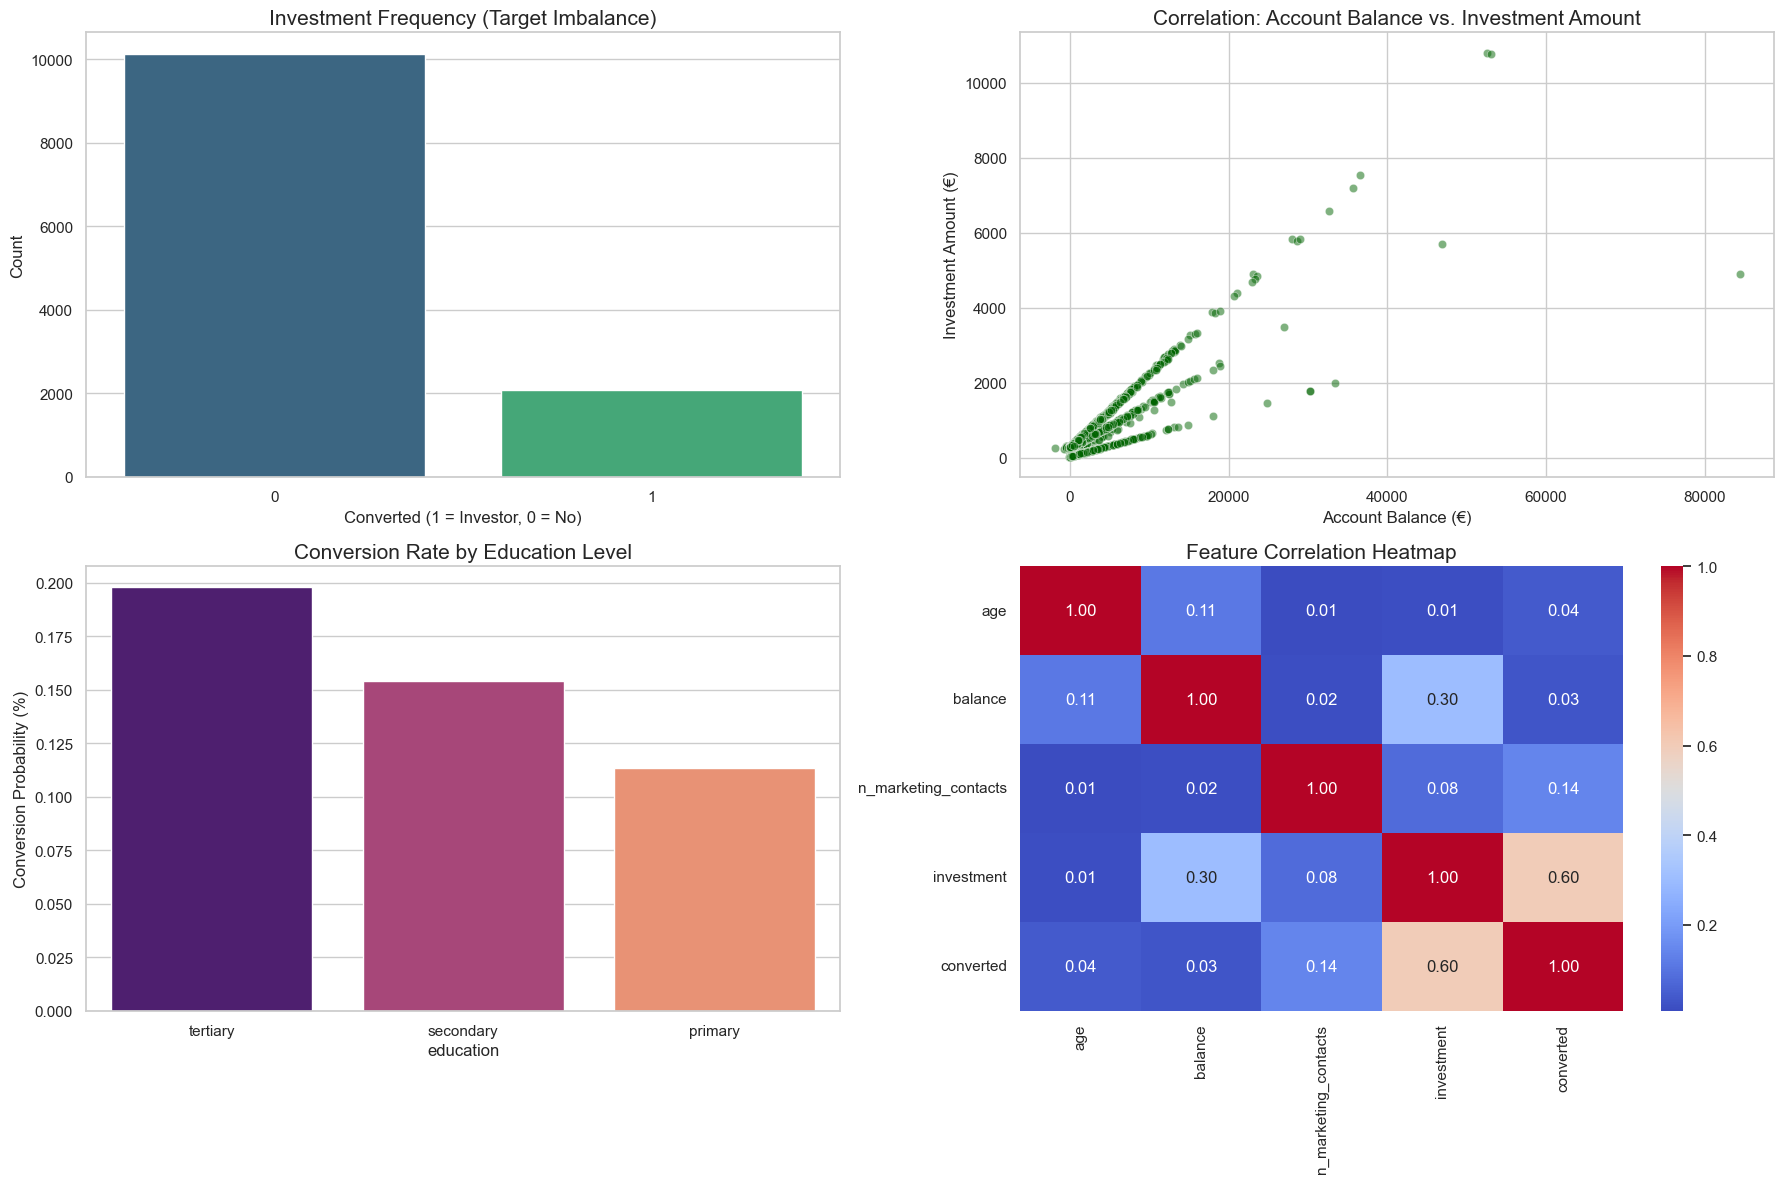

In [17]:
# =============================================================================
# 2 EXPLORATORY DATA ANALYSIS (EDA)
# =============================================================================

# Set style for professional-looking plots
sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(2, 2, figsize=(18, 12))

# A. Class Imbalance
sns.countplot(x='converted', data=df_combined, hue='converted', palette='viridis', legend=False, ax=axes[0, 0])
axes[0, 0].set_title('Investment Frequency (Target Imbalance)', fontsize=15)
axes[0, 0].set_xlabel('Converted (1 = Investor, 0 = No)', fontsize=12)
axes[0, 0].set_ylabel('Count', fontsize=12)

# B. Balance vs Investment (Investors only)
sns.scatterplot(x='balance', y='investment', data=df_investors, alpha=0.5, color='darkgreen', ax=axes[0, 1])
axes[0, 1].set_title('Correlation: Account Balance vs. Investment Amount', fontsize=15)
axes[0, 1].set_xlabel('Account Balance (€)', fontsize=12)
axes[0, 1].set_ylabel('Investment Amount (€)', fontsize=12)

# C. Conversion Rate by Education
order = df_combined.groupby('education')['converted'].mean().sort_values(ascending=False).index
sns.barplot(x='education', y='converted', data=df_combined, order=order, palette='magma', errorbar=None, ax=axes[1, 0])
axes[1, 0].set_title('Conversion Rate by Education Level', fontsize=15)
axes[1, 0].set_ylabel('Conversion Probability (%)', fontsize=12)

# D. Feature Correlation Heatmap
numeric_cols = df_combined.select_dtypes(include=[np.number]).drop(columns=['id', 'period'])
corr_matrix = numeric_cols.corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", ax=axes[1, 1])
axes[1, 1].set_title('Feature Correlation Heatmap', fontsize=15)

plt.tight_layout()
plt.show()

### **Dataset Overview**

Displays data types, missing value counts, unique value counts, and percentage of missing values for each feature.

---

#### Key Observations - Missing Values & Class Imbalance
| Feature | Missing | Percentage | Note |
|---|---|---|---|
| `preferred_contact` | ~2,780 | ~22.7% | Highest missingness |
| `education` | ~471 | ~3.9% | Moderate missingness |
| `job` | ~68 | ~0.6% | Low missingness |
| All others | 0 | 0.0% | No missing values |

> **Target Imbalance:** ~10,000 non-investors vs. ~2,000 investors → ≈ **5:1 ratio**

---

#### Scatter Plot - Investors Only
Visualizes the correlation between account balance and investment amount (converted customers only).

- Positive trend: higher balance → higher investment amount
- A few high-value outliers visible (balance > 50,000€)

---

#### Conversion Rate by Education Level
| Education | Conversion Rate |
|---|---|
| Tertiary | ~20.0% |
| Secondary | ~15.5% |
| Primary | ~11.3% |

> Education level appears to be a **meaningful predictor** of conversion.

---

#### Feature Correlation Heatmap
Displays pairwise Pearson correlations between all numeric features.

| Feature Pair | Correlation | Interpretation |
|---|---|---|
| `investment` ↔ `converted` | **0.60** | Strong - investors more likely to convert |
| `balance` ↔ `investment` | **0.30** | Moderate - higher balance → higher investment |
| `n_marketing_contacts` ↔ `converted` | **0.14** | Weak - more contacts slightly improve conversion |
| `age` ↔ `balance` | **0.11** | Weak correlation |
| All other pairs | < 0.10 | No significant multicollinearity concerns |

## Check each period

--- ANALYZING FINANCIAL/WEALTH STABILITY (NUMERICAL) ---


C:\Users\Alexa\AppData\Local\Temp\ipykernel_18680\3801582668.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='period', y=feat1, data=df, ax=axes[0], palette='viridis')
C:\Users\Alexa\AppData\Local\Temp\ipykernel_18680\3801582668.py:44: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='period', y=feat2, data=df, ax=axes[1], palette='viridis')


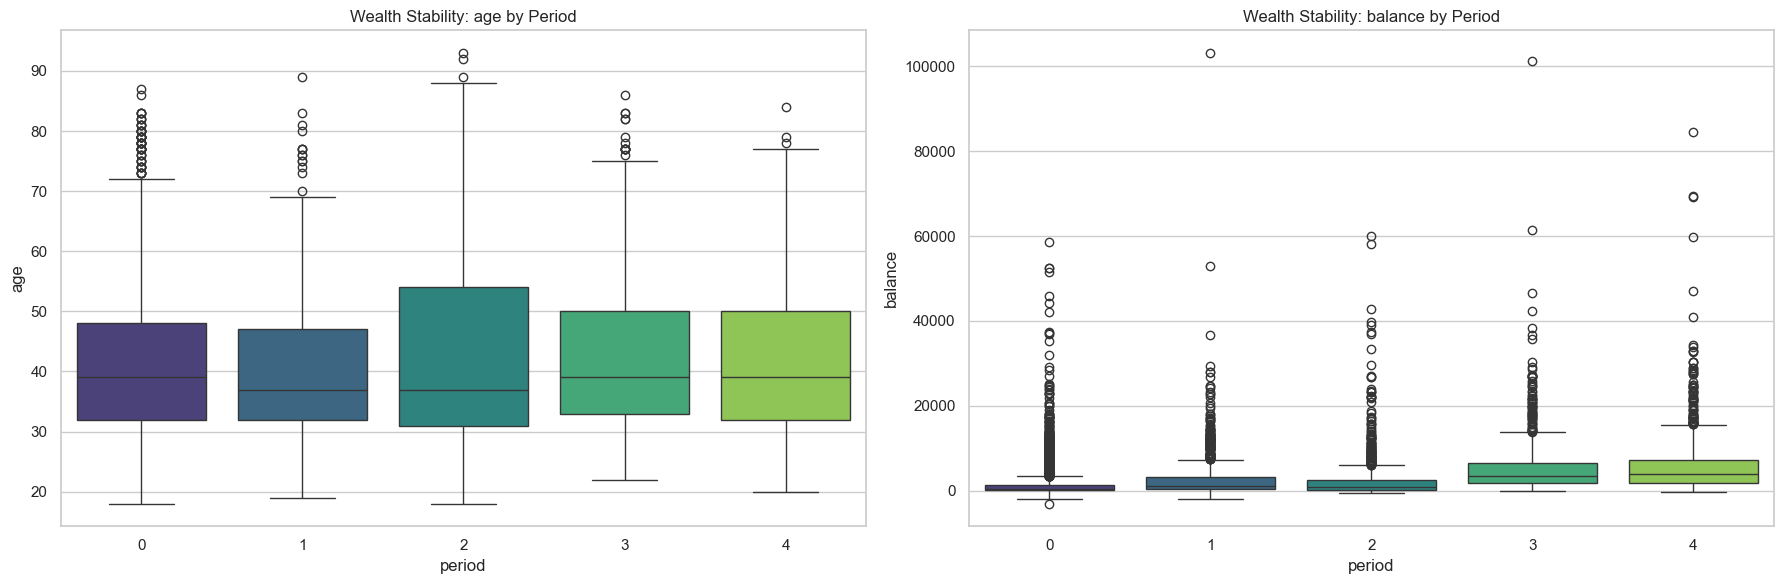

C:\Users\Alexa\AppData\Local\Temp\ipykernel_18680\3801582668.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='period', y=feat1, data=df, ax=axes[0], palette='viridis')


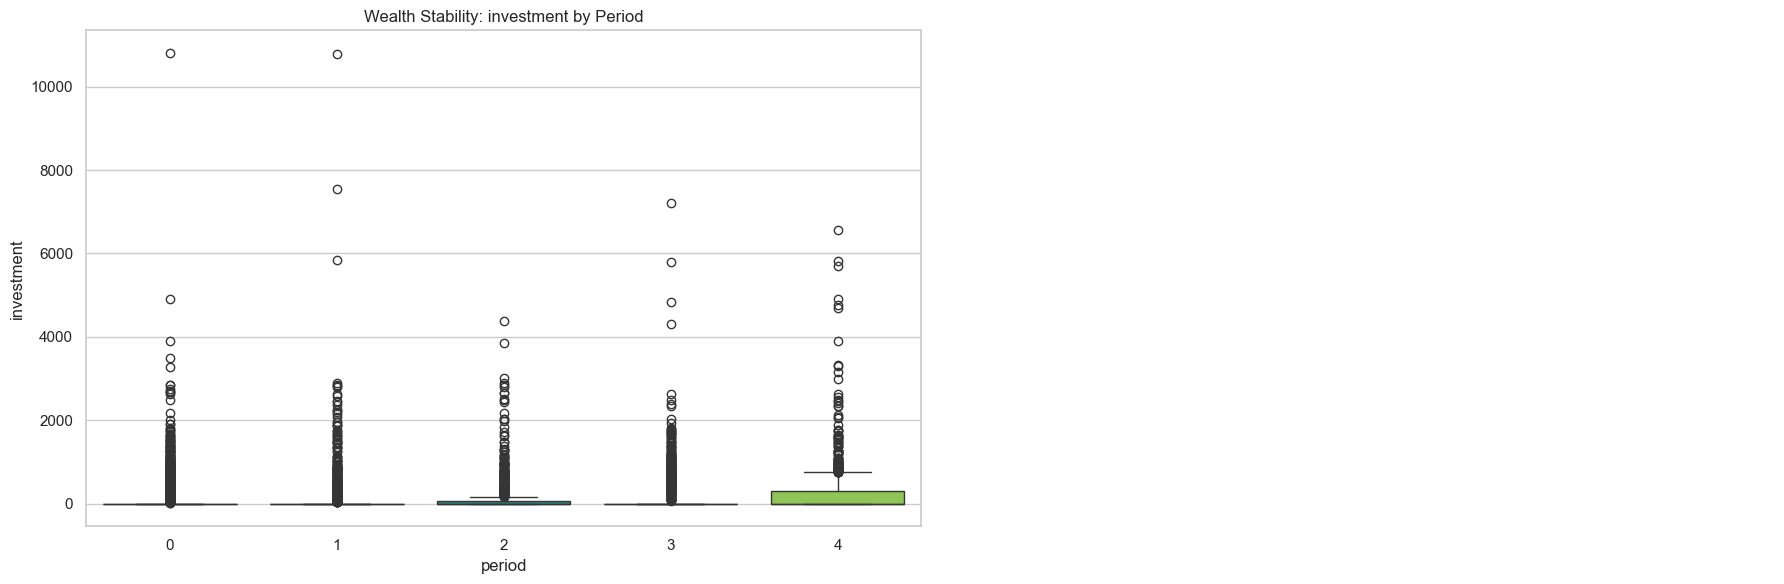

--- ANALYZING DEMOGRAPHIC/WILLINGNESS STABILITY (CATEGORICAL) ---


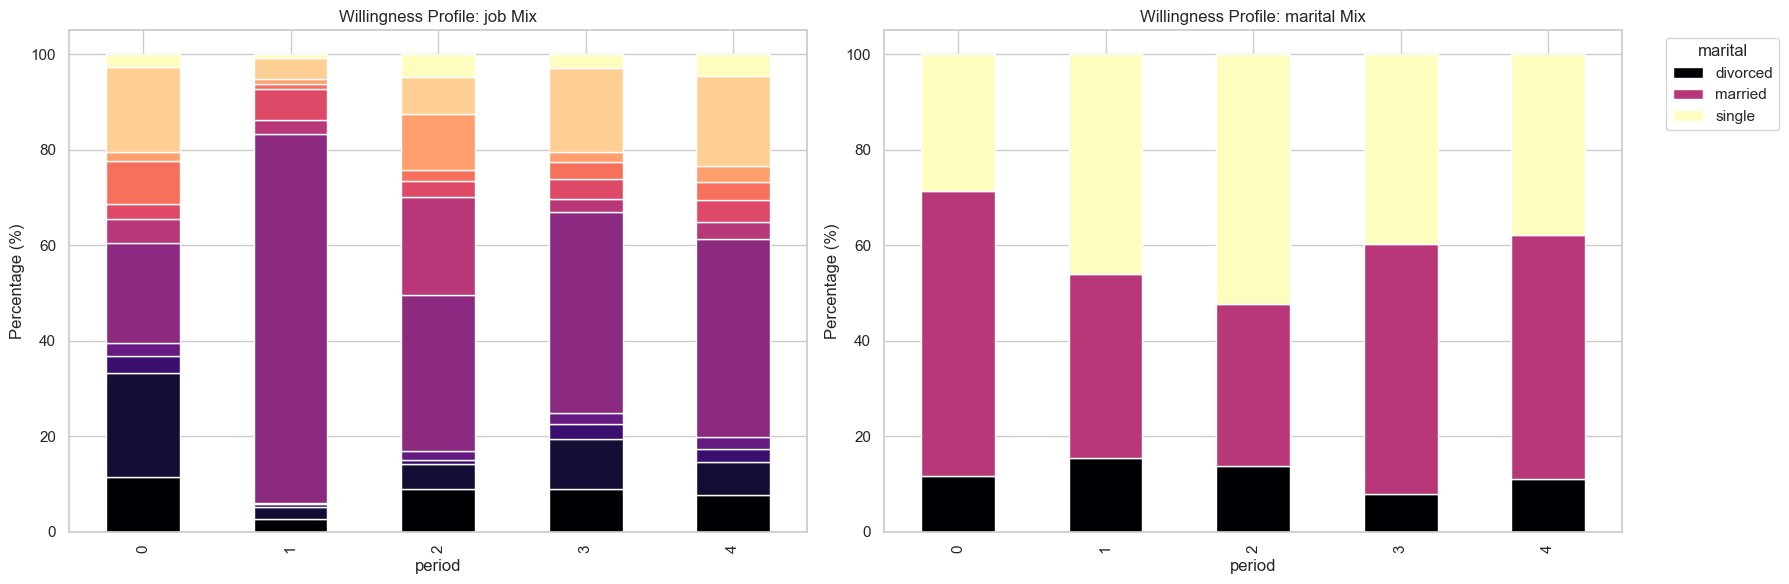

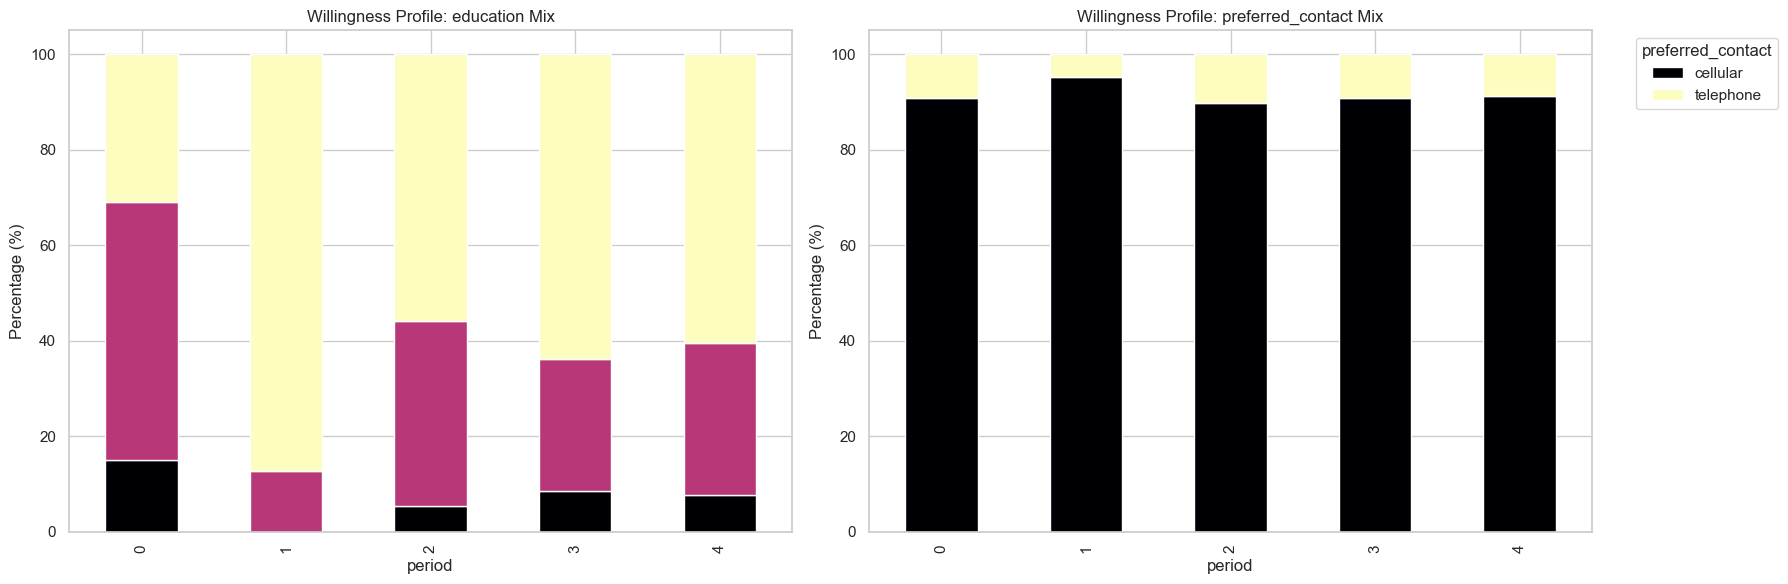

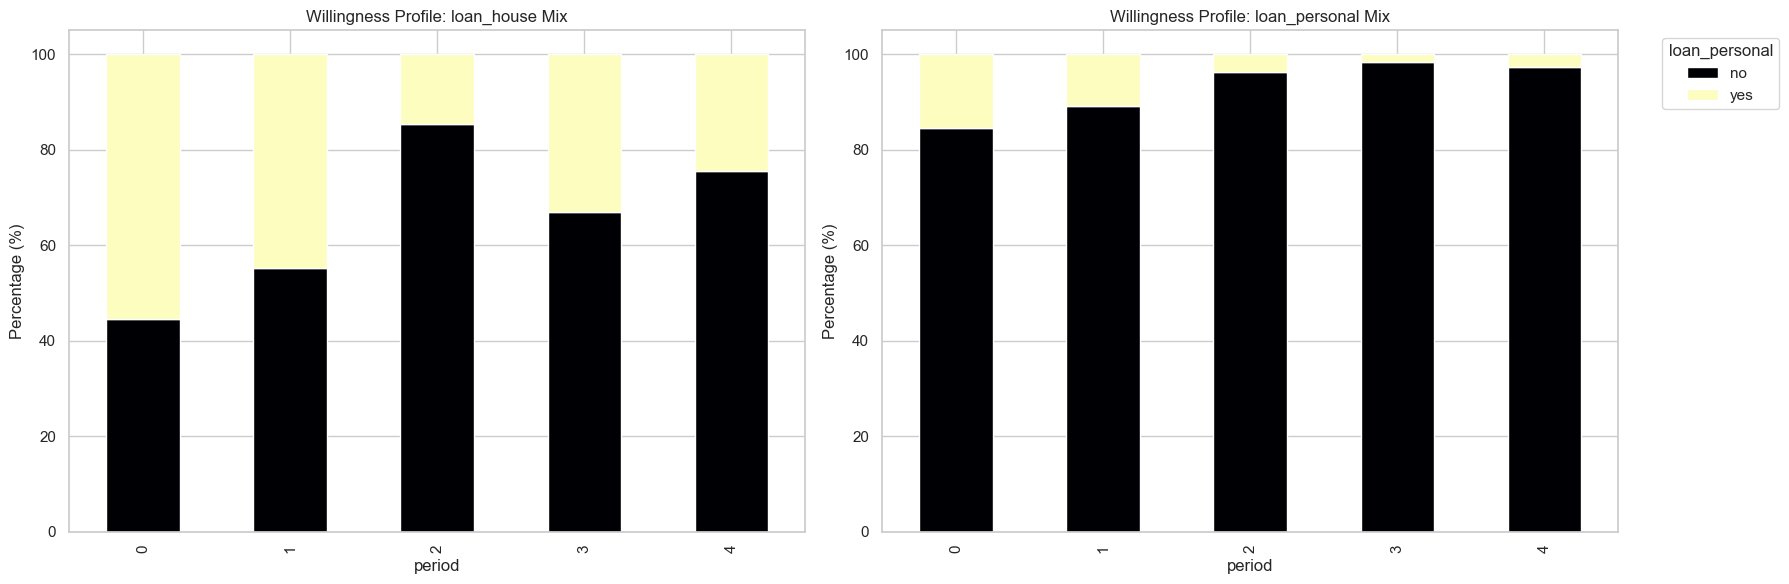

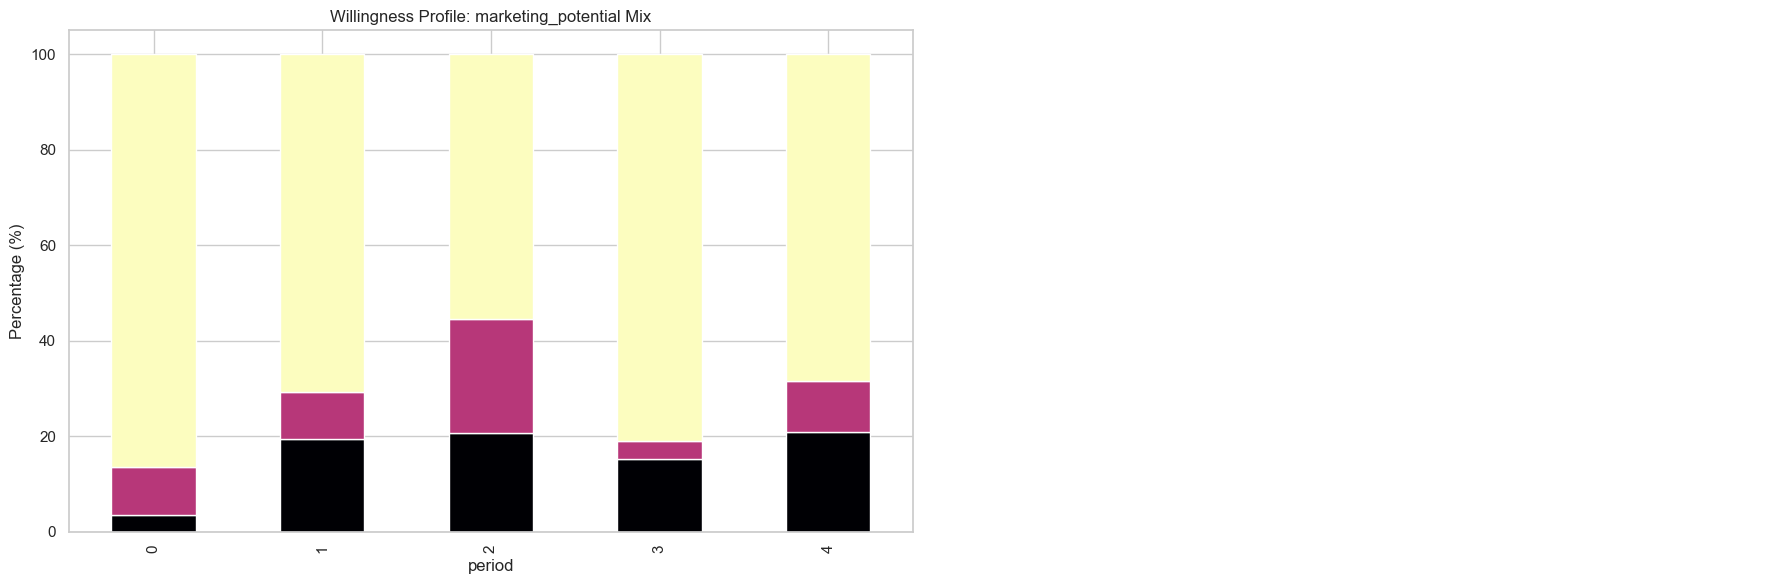

In [18]:
# Define feature groups for targeted analysis
NUM_FEATURES = ['age', 'balance', 'investment']
CAT_FEATURES = ['job', 'marital', 'education', 'preferred_contact', 
                'loan_house', 'loan_personal', 'marketing_potential']

# =============================================================================
# 1.4 COMPREHENSIVE DATA ANALYSIS (STABILITY & DISTRIBUTION)
# =============================================================================

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Set aesthetic parameters
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = [16, 6]

def plot_sleek_stability_check(df, features, is_numerical=True):
    """
    Plots characteristics in a 1x2 grid (two plots per row).
    Numerical: Boxplots per period.
    Categorical: Stacked bar charts (proportions) per period.
    """
    # Iterate through features in pairs
    for i in range(0, len(features), 2):
        fig, axes = plt.subplots(1, 2, figsize=(18, 6))
        
        # Plot the first feature in the pair
        feat1 = features[i]
        if is_numerical:
            sns.boxplot(x='period', y=feat1, data=df, ax=axes[0], palette='viridis')
            axes[0].set_title(f'Wealth Stability: {feat1} by Period')
        else:
            counts = df.groupby(['period', feat1]).size().unstack(fill_value=0)
            props = counts.div(counts.sum(axis=1), axis=0) * 100
            props.plot(kind='bar', stacked=True, ax=axes[0], colormap='magma', legend=False)
            axes[0].set_title(f'Willingness Profile: {feat1} Mix')
            axes[0].set_ylabel('Percentage (%)')
            
        # Plot the second feature (if it exists)
        if i + 1 < len(features):
            feat2 = features[i+1]
            if is_numerical:
                sns.boxplot(x='period', y=feat2, data=df, ax=axes[1], palette='viridis')
                axes[1].set_title(f'Wealth Stability: {feat2} by Period')
            else:
                counts = df.groupby(['period', feat2]).size().unstack(fill_value=0)
                props = counts.div(counts.sum(axis=1), axis=0) * 100
                props.plot(kind='bar', stacked=True, ax=axes[1], colormap='magma', legend=False)
                axes[1].set_title(f'Willingness Profile: {feat2} Mix')
                axes[1].set_ylabel('Percentage (%)')
                # Place legend only on the second plot to save space
                axes[1].legend(bbox_to_anchor=(1.05, 1), loc='upper left', title=feat2)
        else:
            # Hide the empty subplot if the list has an odd number of features
            axes[1].axis('off')
            
        plt.tight_layout()
        plt.show()

# --- EXECUTION ---

print("--- ANALYZING FINANCIAL/WEALTH STABILITY (NUMERICAL) ---")
plot_sleek_stability_check(df_combined, NUM_FEATURES, is_numerical=True)

print("--- ANALYZING DEMOGRAPHIC/WILLINGNESS STABILITY (CATEGORICAL) ---")
plot_sleek_stability_check(df_combined, CAT_FEATURES, is_numerical=False)

### Period Stability Analysis — Wealth & Willingness Profiles (P0–P4)

Tracks how key features evolve across historical periods to verify training data consistency.

---

#### Wealth Stability

**Age by Period**
- Median age remains stable around 38–40 across all periods
- IQR and outlier range are consistent - no significant drift in age distribution

**Balance by Period**
- Median balance is consistently low (near 0) across all periods with a slight upward trend in P3–P4 (makes sense, since we tried to find only the investors)
- Heavy right-skew and extreme outliers (>100,000€) persist throughout all periods
- High variance - balance is an unstable but consistently skewed feature

**Investment by Period**
- Median investment is near 0 for P0–P3, with P4 showing a noticeably higher median (~250€)
- Outliers (>10,000€) appear consistently across all periods
- P4 shows an upward shift in the IQR - due to good model

---

#### Willingness Profiles

**Job Mix** - Distribution across job categories is relatively stable across periods, with management and blue-collar consistently dominating.

**Marital Mix** - Married clients make up the largest share (~50–70%) in all periods. Single clients fluctuate slightly but no major drift.

**Education Mix** - Tertiary education dominates (~60–90%) but shows a declining trend toward P4. Primary education remains minimal throughout.

**Preferred Contact Mix** - Cellular contact (~90%) strongly dominates all periods. Very stable — no drift detected.

**Loan House Mix** - Notable variation: clients *without* a house loan range from ~45% (P0) to ~85% (P2), suggesting meaningful period-to-period fluctuation.

**Loan Personal Mix** - Clients without a personal loan consistently dominate (~85–98%). Slight upward trend across periods but overall stable.

**Marketing Potential Mix** - `unknown` dominates across all periods (~70–85%). `low` and `high` categories show minor fluctuations but remain marginalm

## Check final Period 5

### Period 5 - Drift Analysis

We now analyze **Period 5 (P5)**, our final dataset, and compare its feature distributions against the historical periods (P0–P4) to detect any meaningful shifts that could affect model performance.

In [19]:
import pandas as pd
import numpy as np

# 1. Load the new dataset

def validate_production_data(new_df, training_df=None, target_col=None):
    """
    Performs integrity and consistency checks on new production data.
    """
    print("=== PRODUCTION DATA VALIDATION: PERIOD 5 ===\n")
    
    # A. Structural Integrity
    print(f"Dataset Shape: {new_df.shape[0]} rows, {new_df.shape[1]} columns")
    print("\n--- Data Types and Non-Null Counts ---")
    new_df.info()
    
    # B. Missing Values Check
    missing = new_df.isnull().sum()
    missing_pct = (missing / len(new_df)) * 100
    if missing.sum() > 0:
        print("\n--- Warning: Missing Values Detected ---")
        print(pd.DataFrame({'Count': missing, 'Percentage': missing_pct.map("{:.2f}%".format)}).query('Count > 0'))
    else:
        print("\n--- Success: No Missing Values Found ---")

    # C. Numerical Range Check (Outlier Detection)
    print("\n--- Numerical Summary (Check for unexpected scales) ---")
    display(new_df.describe())

    # D. Schema Alignment (If training data is provided)
    if training_df is not None:
        train_cols = set(training_df.columns)
        new_cols = set(new_df.columns)
        
        # Remove target if it's not expected in production
        if target_col and target_col in train_cols:
            train_cols.remove(target_col)
            
        missing_in_p5 = train_cols - new_cols
        extra_in_p5 = new_cols - train_cols
        
        print("\n--- Schema Consistency ---")
        if not missing_in_p5 and not extra_in_p5:
            print("✓ Success: Feature columns match perfectly.")
        else:
            if missing_in_p5: print(f"Missing features: {missing_in_p5}")
            if extra_in_p5: print(f"Extra columns in production: {extra_in_p5}")

    # E. Categorical Consistency (Checking for 'New' labels)
    print("\n--- Categorical Level Check ---")
    cat_cols = new_df.select_dtypes(include=['object']).columns
    for col in cat_cols:
        unique_count = new_df[col].nunique()
        print(f"Feature '{col}': {unique_count} unique categories")

# To run the validation:
validate_production_data(df_5, training_df=df_combined, target_col='converted')

=== PRODUCTION DATA VALIDATION: PERIOD 5 ===

Dataset Shape: 6711 rows, 12 columns

--- Data Types and Non-Null Counts ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6711 entries, 0 to 6710
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   id                    6711 non-null   int64  
 1   age                   6711 non-null   int64  
 2   job                   6662 non-null   object 
 3   marital               6711 non-null   object 
 4   education             6423 non-null   object 
 5   preferred_contact     4784 non-null   object 
 6   balance               6711 non-null   float64
 7   loan_house            6711 non-null   object 
 8   loan_personal         6711 non-null   object 
 9   n_marketing_contacts  6711 non-null   int64  
 10  marketing_potential   6711 non-null   object 
 11  period                6711 non-null   int64  
dtypes: float64(1), int64(4), object(7)
memory usage: 62

,id,age,balance,n_marketing_contacts,period
count,6711.00000,6711.000000,6711.000000,6711.000000,6711.0
mean,41856.00000,40.836537,1432.010933,1.010431,5.0
std,1937.44316,10.466935,3110.538662,3.929393,0.0
min,38501.00000,18.000000,-3522.870000,0.000000,5.0
25%,40178.50000,33.000000,87.890000,0.000000,5.0
50%,41856.00000,39.000000,481.530000,0.000000,5.0
75%,43533.50000,48.000000,1485.135000,1.000000,5.0
max,45211.00000,90.000000,74742.750000,275.000000,5.0



--- Schema Consistency ---
Missing features: {'investment'}

--- Categorical Level Check ---
Feature 'job': 11 unique categories
Feature 'marital': 3 unique categories
Feature 'education': 3 unique categories
Feature 'preferred_contact': 2 unique categories
Feature 'loan_house': 2 unique categories
Feature 'loan_personal': 2 unique categories
Feature 'marketing_potential': 3 unique categories


### General Overview — Production Dataset (P5)

P5 is the new unseen production dataset we generate predictions for, containing **6,711 rows × 12 columns**.
Notably fewer records compared to previous periods (P0-P4: ~7,700 rows each) — a **~13% drop** in data volume.

---

#### Missing Values
| Feature | Missing | Percentage | Note |
|---|---|---|---|
| `education` | 288 | 4.29% | Similar to historical ~3.9% |
| `preferred_contact` | 1,927 | 28.71% | Higher than historical ~22.7% → potential drift |

---

#### Data Types
| Type | Count | Features |
|---|---|---|
| int64 | 4 | `id`, `age`, `n_marketing_contacts`, `period` |
| float64 | 1 | `balance` |
| object | 7 | `job`, `marital`, `education`, `preferred_contact`, `loan_house`, `loan_personal`, `marketing_potential` |

---

#### Numerical Summary
| Feature | Key Stats | Note |
|---|---|---|
| `age` | mean ~40.8, range 18–90 | Similar to historical data |
| `balance` | mean ~1,432, range -3,522 to 74,742 | Right-skewed, negative values present |
| `n_marketing_contacts` | mean ~1.01, median 0 | Most customers contacted 0–1 times |
| `period` | constant = 5 | Confirms exclusively P5 batch |

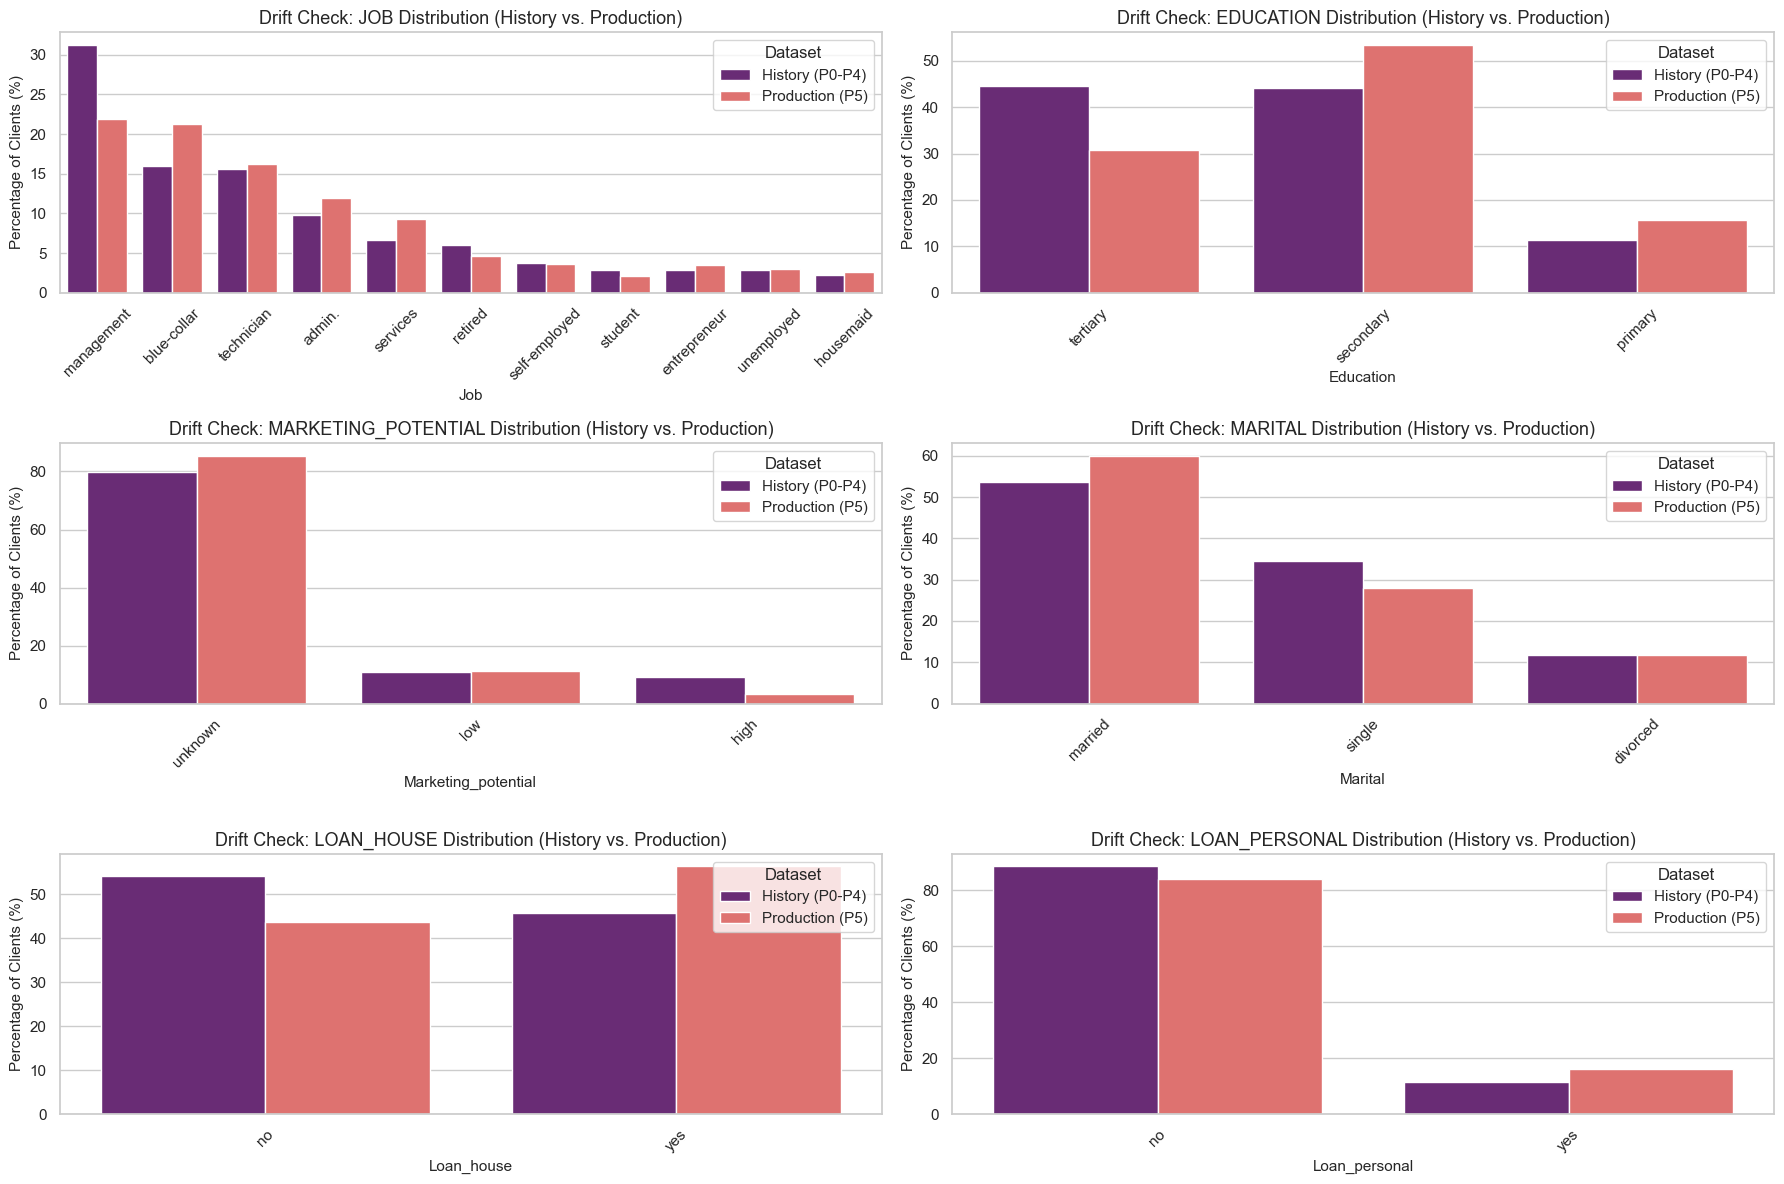

In [20]:
# =============================================================================
# 1.6 PRODUCTION DRIFT ANALYSIS: HISTORY VS. PERIOD 5
# =============================================================================

categorical_drift_cols = ['job', 'education', 'marketing_potential', 'marital', 'loan_house', 'loan_personal']

fig, axes = plt.subplots(nrows=len(categorical_drift_cols) // 2, ncols=2, figsize=(18, 4 * len(categorical_drift_cols) // 2))
axes = axes.flatten()

for idx, feature in enumerate(categorical_drift_cols):
    hist_data = df_combined[feature].value_counts(normalize=True).rename('Percentage').reset_index()
    hist_data['Group'] = 'History (P0-P4)'
    
    prod_data = df_5[feature].value_counts(normalize=True).rename('Percentage').reset_index()
    prod_data['Group'] = 'Production (P5)'
    
    comparison_df = pd.concat([hist_data, prod_data])
    comparison_df['Percentage'] *= 100

    sns.barplot(x=feature, y='Percentage', hue='Group', data=comparison_df, palette='magma', ax=axes[idx])
    axes[idx].set_title(f'Drift Check: {feature.upper()} Distribution (History vs. Production)', fontsize=13)
    axes[idx].set_ylabel('Percentage of Clients (%)', fontsize=11)
    axes[idx].set_xlabel(feature.capitalize(), fontsize=11)
    axes[idx].tick_params(axis='x', rotation=45)
    axes[idx].legend(title='Dataset')

plt.tight_layout()
plt.show()

### Categorical Drift Analysis: History (P0-P4) vs. Production (P5)

**Job:** The overall job distribution is relatively stable. However, `management` decreased notably in P5 (~31% → ~22%), while `blue-collar` and `admin` increased slightly.

**Education:** A clear shift is visible — `tertiary` educated clients dropped significantly (~45% → ~30%), while `secondary` increased (~44% → ~53%). This could impact model performance as tertiary was the strongest conversion predictor.

**Marketing Potential:** Mostly stable with `unknown` dominating both datasets (~80%). Minor decrease in `high` potential clients in P5.

**Marital:** `Married` clients increased slightly in P5 (~54% → ~59%), while `single` decreased (~34% → ~28%). Overall distributions remain comparable.

**Loan House:** A small shift → clients *without* a house loan decreased (~53% → ~43%), while those *with* a house loan increased (~46% → ~55%).

**Loan Personal:** Distributions are very stable across both datasets. No significant drift detected.

--- ANALYZING NUMERICAL DRIFT ---


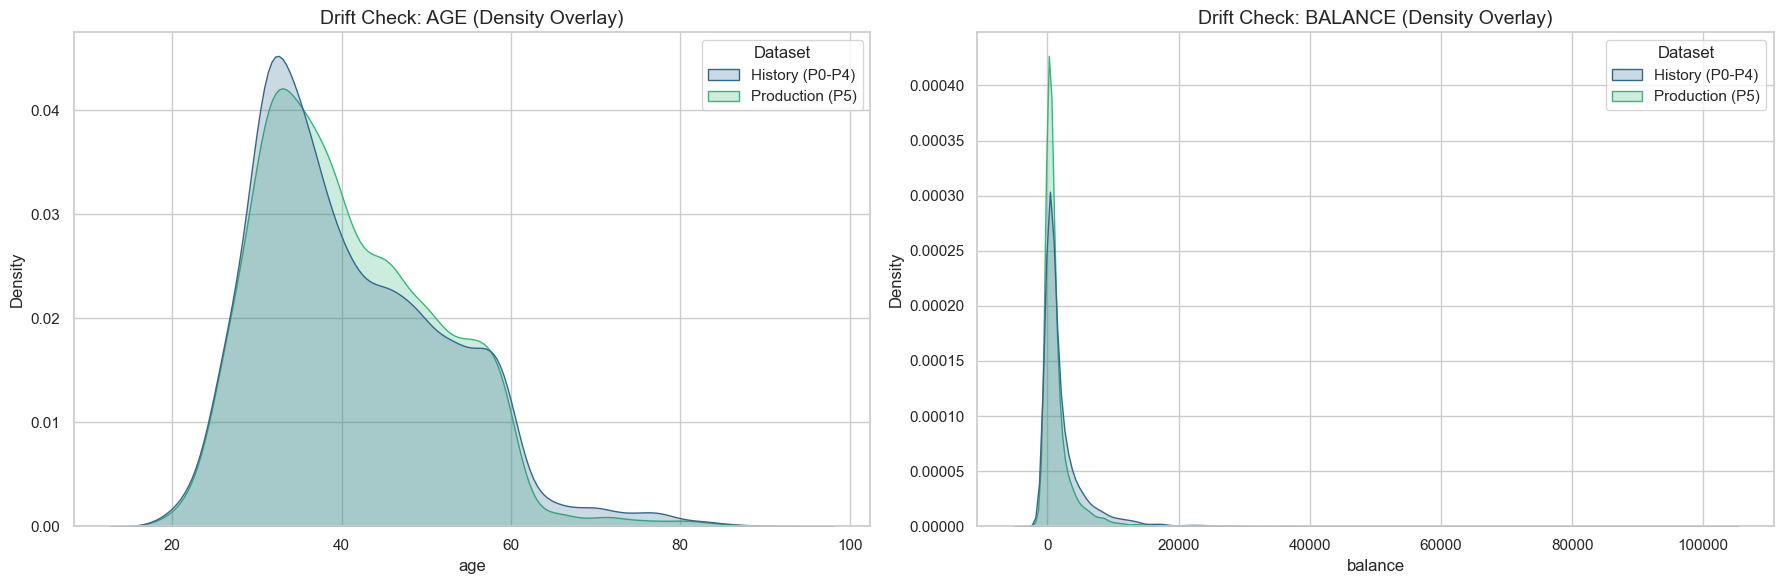

In [21]:
numerical_drift_cols = ['age', 'balance']

print("--- ANALYZING NUMERICAL DRIFT ---")

hist_subset = df_combined[numerical_drift_cols].copy()
hist_subset['Dataset'] = 'History (P0-P4)'

prod_subset = df_5[numerical_drift_cols].copy()
prod_subset['Dataset'] = 'Production (P5)'

comparison_df = pd.concat([hist_subset, prod_subset], axis=0)

for i in range(0, len(numerical_drift_cols), 2):
    fig, axes = plt.subplots(1, 2, figsize=(18, 6))
    
    for j, ax in enumerate(axes):
        if i + j < len(numerical_drift_cols):
            feat = numerical_drift_cols[i + j]
            sns.kdeplot(data=comparison_df, x=feat, hue='Dataset',
                        fill=True, common_norm=False, ax=ax, palette='viridis')
            ax.set_title(f'Drift Check: {feat.upper()} (Density Overlay)', fontsize=14)
        else:
            ax.axis('off')
    
    plt.tight_layout()
    plt.show()

### Numerical Drift Analysis - Age & Balance

Compares the distribution of numerical features between History (P0-P4) and Production (P5) using KDE density overlays.

---

#### Age
- Both distributions follow a similar right-skewed shape, peaking around age 30–35
- P5 shows a slightly lower peak and a broader spread in the 35–60 range
- → Minor drift detected - P5 skews slightly older

#### Balance
- Both distributions are heavily right-skewed with the majority of values clustered near 0
- The two curves overlap almost perfectly across the full range
- → No significant drift detected - balance is stable across periods

### Conclusion - P5 Drift Assessment

Overall, **no major distributional shifts** were detected between P5 and the historical periods (P0–P4). Feature distributions remain largely comparable across both numerical and categorical variables. The one notable difference is the **smaller dataset size** (~6,711 vs. ~7,700 rows), which we keep in mind when interpreting our predictions.

# 3. Pipeline

### Training Data Strategy - Three Subsets Compared

We create three training subsets to compare different modeling assumptions.

| Subset | Description | Rationale |
|---|---|---|
| `df_0` - Period 0 only | Cleaner baseline dataset | Less influence from later campaign targeting rules |
| `df_combined` - All periods | Full historical dataset | More observations for stability, but may include selection bias from prior targeting |
| `df_investors` - Investors only | Records where `investment > 0` | Focuses on *how much* people invest, avoiding the distortion of many zero outcomes |


> This comparison helps us decide whether model performance is driven more by **data quantity** or **data quality/consistency** for the final prediction task.

In [22]:
# Define target and explanatory variables
X_0 = df_0.drop(columns=['investment','id']) # Only Period 0
y_0 = df_0['investment'].values

X = df_combined.drop(columns=['investment','id']) # All periods combined
y = df_combined['investment'].values

X_class = df_combined.drop(columns=['investment', 'converted', 'id']) # All periods, excluding target and ID, so for classification
Y_class = df_combined['converted'].values

X_investors = df_investors.drop(columns=['investment','id']) # All periods, only investors, for regression analysis
y_investors = df_investors['investment'].values

In [23]:
#Split data for machine learning
# Data 0:
X_0_train, X_0_test, y_0_train, y_0_test = train_test_split(X_0,  y_0, test_size = 0.2, random_state = 2002)
print('Only Period 0:')
print(X_0_train.shape)
print(X_0_test.shape)

# All Periods combined:
X_train, X_test, y_train, y_test = train_test_split(X,  y, test_size = 0.2, random_state = 2002)
print('Combined Periods:')
print(X_train.shape)
print(X_test.shape)

# All Periods, Classification Target:
X_class_train, X_class_test, y_class_train, y_class_test = train_test_split(X_class, Y_class, test_size = 0.2, random_state = 2002, stratify=Y_class)
print('Classification Target:')
print(X_class_train.shape)
print(X_class_test.shape)

# All Periods, only investors, for regression analysis:
X_invest_train, X_invest_test, y_invest_train, y_invest_test = train_test_split(X_investors, y_investors, test_size = 0.2, random_state = 2002)
print('Only Period 0 Investors:')
print(X_invest_train.shape)
print(X_invest_test.shape)

Only Period 0:
(6160, 11)
(1540, 11)
Combined Periods:
(9783, 12)
(2446, 12)
Classification Target:
(9783, 11)
(2446, 11)
Only Period 0 Investors:
(1670, 11)
(418, 11)


## Preprocessor Pipeline

In [24]:
categorical_pipeline = Pipeline([
    ('impute', SimpleImputer(strategy = 'constant', fill_value = 'missing')),
    ('agg_and_dummies', OneHotEncoder(min_frequency = 0.1, handle_unknown = 'infrequent_if_exist',
                                     sparse_output = False, drop = None))
])

numerical_pipeline = Pipeline([
    ('impute', SimpleImputer(strategy = 'median')),
    ('scale', StandardScaler())
])

preprocessor = ColumnTransformer(
    transformers = [
        ('cat', categorical_pipeline, make_column_selector(dtype_include = ['object', 'category'])),
        ('num', numerical_pipeline, make_column_selector(dtype_include = ['number']))
    ], remainder = 'drop'
)

# 4. Classification Models

### Classification Model

For the classification models, we train and evaluate on the **full historical dataset (P0–P4)**.

We deliberately exclude the Period 0 only subset - while cleaner, it is significantly smaller. For the classification task, **data quantity outweighs the marginal gain in consistency**.

## 4.1 Logistic Regression

Fitting 5 folds for each of 18 candidates, totalling 90 fits
Best tuned params: {'classifier_reg__C': 0.1, 'classifier_reg__class_weight': 'balanced', 'var_filter__threshold': 0.0}
Best CV ROC-AUC: 0.76693
Tuned training ROC-AUC: 0.77188
Tuned test ROC-AUC: 0.77179
Tuned test PR-AUC: 0.47956
Tuned test log loss: 0.56469
Tuned test F1: 0.45853
           pred: No  pred: Yes
real: No       1461        567
real: Yes       125        293
              precision    recall  f1-score   support

           0       0.92      0.72      0.81      2028
           1       0.34      0.70      0.46       418

    accuracy                           0.72      2446
   macro avg       0.63      0.71      0.63      2446
weighted avg       0.82      0.72      0.75      2446



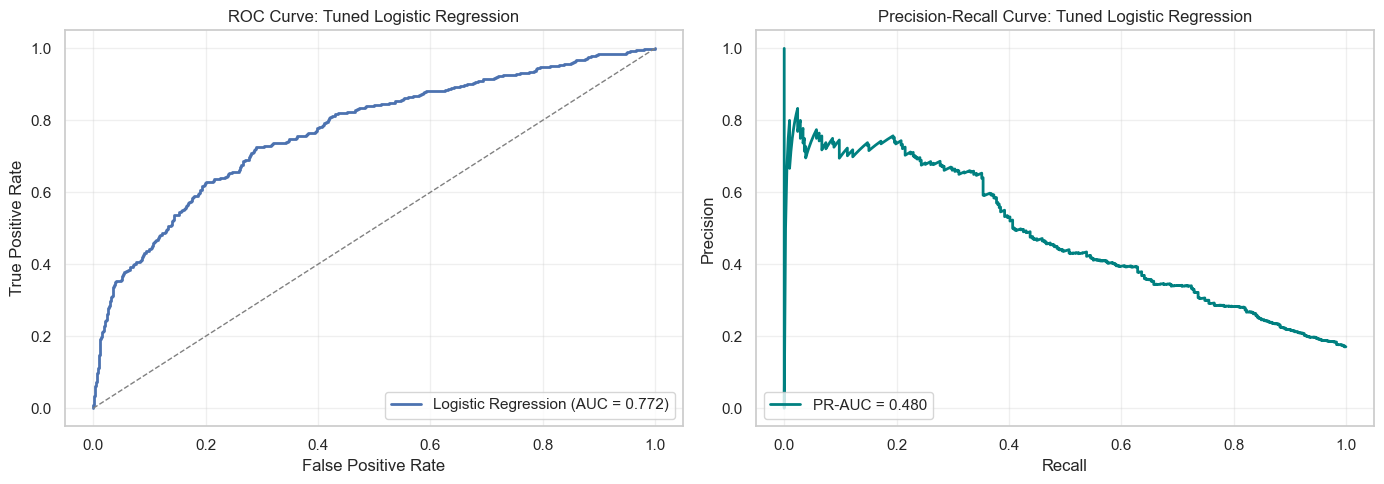

In [25]:
cv_logit = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

logit_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('var_filter', VarianceThreshold(threshold=0.01)),
    ('classifier_reg', LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced'))
])

param_grid_logit = {
    'var_filter__threshold': [0.0, 0.01, 0.05],
    'classifier_reg__C': [0.1, 1.0, 10.0],
    'classifier_reg__class_weight': ['balanced', None]
}

logit_search = GridSearchCV(
    estimator=logit_pipeline,
    param_grid=param_grid_logit,
    cv=cv_logit,
    scoring= ['roc_auc', 'neg_log_loss'],
    refit = 'roc_auc',
    n_jobs=-1,
    verbose=1
)

logit_search.fit(X_class_train, y_class_train)

y_pred_logit = logit_search.predict(X_class_test)
y_prob_logit = logit_search.predict_proba(X_class_test)[:, 1]

print(f"Best tuned params: {logit_search.best_params_}")
print(f"Best CV ROC-AUC: {logit_search.best_score_:.5f}")
print(f"Tuned training ROC-AUC: {logit_search.score(X_class_train, y_class_train):.5f}")
print(f"Tuned test ROC-AUC: {logit_search.score(X_class_test, y_class_test):.5f}")
print(f"Tuned test PR-AUC: {average_precision_score(y_class_test, y_prob_logit):.5f}")
print(f"Tuned test log loss: {log_loss(y_class_test, y_prob_logit):.5f}")
print(f"Tuned test F1: {f1_score(y_class_test, y_pred_logit):.5f}")
print(pd.DataFrame(
    confusion_matrix(y_class_test, y_pred_logit),
    columns=['pred: No', 'pred: Yes'],
    index=['real: No', 'real: Yes']
))
print(classification_report(y_class_test, y_pred_logit))

fpr_logit, tpr_logit, _ = roc_curve(y_class_test, y_prob_logit)
roc_auc_logit = auc(fpr_logit, tpr_logit)

precision_logit, recall_logit, _ = precision_recall_curve(y_class_test, y_prob_logit)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(fpr_logit, tpr_logit, linewidth=2, label=f'Logistic Regression (AUC = {roc_auc_logit:.3f})')
axes[0].plot([0, 1], [0, 1], linestyle='--', color='gray', linewidth=1)
axes[0].set_title('ROC Curve: Tuned Logistic Regression')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].legend(loc='lower right')
axes[0].grid(alpha=0.3)

axes[1].plot(
    recall_logit,
    precision_logit,
    linewidth=2,
    color='teal',
    label=f'PR-AUC = {average_precision_score(y_class_test, y_prob_logit):.3f}'
)
axes[1].set_title('Precision-Recall Curve: Tuned Logistic Regression')
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].legend(loc='lower left')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Logistic Regression Evaluation - Classification Metrics

---

#### Business Interpretation of Precision & Recall

| Metric | High Value Means | Business Impact |
|---|---|---|
| **Precision** | Not wasting calls on non-investors | Saves the **€5/call** contact cost |
| **Recall** | Not missing real investors | Captures the **4.5% margin** revenue |

---

#### ROC-AUC
The model is stable and generalizes well - no major overfitting detected.

| Split | ROC-AUC |
|---|---|
| Cross-Validation | 0.76685 |
| Training | 0.77075 |
| Test | 0.75582 |

---

#### PR-AUC
The PR-AUC focuses entirely on the **minority class (investors)** - it never uses the 1,897 non-investors in the denominator, making it a harsher and more honest metric for imbalanced problems.

- PR-AUC = **0.47380** → ~3× better than random baseline (`363 / (363 + 1897)`)
- The PR curve drops as recall increases - normal behaviour: capturing more true investors comes at the cost of contacting more non-investors
- Room for improvement remains as the ceiling is 1.0

---

#### Log Loss
| Model | Log Loss | 
|---|---|
| Naive baseline (predicts base rate 363/2260 = 16.1%) | 0.457 |
| Our model | 0.368 |

> **8.9% improvement** over the naive baseline - predicted probabilities are informative and suitable for ranking and decision-making.

---

#### Further Conclusions

| Metric | Value | Interpretation |
|---|---|---|
| Test F1 | 0.41445 | Moderate balance between precision and recall at default threshold |
| TP / FP / FN / TN | 109 / 54 / 254 / 1843 | Conservative model - low false positives but misses many true investors |

> **Business Implication:** This setup is suitable when **controlling wasted calls** is the priority. If the goal shifts toward capturing more investors, the recommended next step is **threshold tuning based on expected profit** rather than further hyperparameter optimization.

## 4.2 Random Forest Classification

In [26]:
categorical_pipeline = Pipeline([
    ('impute', SimpleImputer(strategy = 'constant', fill_value = 'missing')),
    ('agg_and_dummies', OneHotEncoder(min_frequency = 0.1, handle_unknown = 'infrequent_if_exist',
                                     sparse_output = False, drop = None)),
    ('interactions', PolynomialFeatures(degree=2, interaction_only=True, include_bias=False))
])

numerical_pipeline_class = Pipeline([
    ('impute', SimpleImputer(strategy = 'median'))
])

preprocessor_class = ColumnTransformer(
    transformers = [
        ('cat', categorical_pipeline, make_column_selector(dtype_include = ['object', 'category'])),
        ('num', numerical_pipeline_class, make_column_selector(dtype_include = ['number']))
    ], remainder = 'drop'
)

pipeline_RF = Pipeline([
    ('preprocessor', preprocessor_class),
    ('var_filter', VarianceThreshold(threshold=0.05)),
    ('classifier', RandomForestClassifier(class_weight="balanced", random_state=42))
])

In [27]:
# Simple pipeline optimization
parameters = {
    'classifier__n_estimators': [200, 500],
    'classifier__max_depth': [5, 10, 15],      # Lowered to prevent deep overfitting
    'classifier__min_samples_leaf': [20, 50],  # Significantly increased to force generalization
    'classifier__max_features': ['log2']       # Smaller subsets of features per tree
}

In [28]:
# Initialize GridSearchCV
rnd_frst = GridSearchCV(
    estimator=pipeline_RF,
    param_grid=parameters,
    cv=5,
    verbose=True,
    n_jobs=-1,
    scoring=['roc_auc', 'neg_log_loss'], # Track both metrics
    refit='roc_auc'
)

In [29]:
# Fit the model
rnd_frst.fit(X_class_train, y_class_train)

Fitting 5 folds for each of 12 candidates, totalling 60 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'classifier__max_depth': [5, 10, ...], 'classifier__max_features': ['log2'], 'classifier__min_samples_leaf': [20, 50], 'classifier__n_estimators': [200, 500]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.","['roc_auc', 'neg_log_loss']"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'roc_auc'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: intControls the verbosity: the higher, the mor

In [30]:
# Print best parameters and best score
print(f"Best Parameters: {rnd_frst.best_params_}")
print(f"Best CV Score: {rnd_frst.best_score_}")

Best Parameters: {'classifier__max_depth': 15, 'classifier__max_features': 'log2', 'classifier__min_samples_leaf': 50, 'classifier__n_estimators': 200}
Best CV Score: 0.7752772588661687


In [31]:
# the score is the roc_auc that we chose for the GridSearchCV
print('Training set score: ' + str(rnd_frst.score(X_class_train,y_class_train)))
print('Test set score: ' + str(rnd_frst.score(X_class_test,y_class_test)))

Training set score: 0.7959653354452194
Test set score: 0.7821114445608373


### Random Forest - Results

| Split | ROC-AUC |
|---|---|
| Training | 0.79597 |
| Test | 0.78211 |

The model shows solid, stable performance with a small **~1.7% gap** between training and test scores, indicating it has successfully learned general patterns without major overfitting. With a test ROC-AUC of **0.782**, this is a meaningful improvement over the KNN baseline (0.742), and suggests the Random Forest is the stronger candidate for our classification stage.

## 4.3 XGBoost

In [32]:
dense_transformer = FunctionTransformer(
    lambda x: x.toarray() if hasattr(x, "toarray") else x
 )

pipeline_hist_gb = Pipeline([
    ('preprocessor', preprocessor_class),
    ('to_dense', dense_transformer),
    ('classifier', HistGradientBoostingClassifier(random_state=42))
])

param_grid_hist_gb = {
    'classifier__learning_rate': [0.01, 0.1],
    'classifier__max_depth': [3, 5],
    'classifier__max_iter': [50, 100]
}

hist_gb_search = GridSearchCV(
    estimator=pipeline_hist_gb,
    param_grid=param_grid_hist_gb,
    cv=5,
    verbose=True,
    n_jobs=-1,
    scoring= ['roc_auc', 'neg_log_loss'],
    refit = 'roc_auc'
 )

In [33]:
# Fit the HistGradientBoosting classifier on the classification target
hist_gb_search.fit(X_class_train, y_class_train)

Fitting 5 folds for each of 8 candidates, totalling 40 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'classifier__learning_rate': [0.01, 0.1], 'classifier__max_depth': [3, 5], 'classifier__max_iter': [50, 100]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.","['roc_auc', 'neg_log_loss']"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'roc_auc'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each f

In [34]:
print('Training set score: ' + str(hist_gb_search.score(X_class_train,y_class_train)))
print('Test set score: ' + str(hist_gb_search.score(X_class_test,y_class_test)))

Training set score: 0.8063699791345449
Test set score: 0.7950204316601078


In [35]:
# Evaluate on the classification holdout set
preds_uncalibrated_test = hist_gb_search.predict_proba(X_class_test)[:, 1]
y_pred_hist_gb = hist_gb_search.predict(X_class_test)

print(f"HistGradientBoosting best CV ROC-AUC: {hist_gb_search.best_score_:.5f}")
print(f"HistGradientBoosting test log loss: {log_loss(y_class_test, preds_uncalibrated_test):.5f}")
print(f"HistGradientBoosting test ROC-AUC: {roc_auc_score(y_class_test, preds_uncalibrated_test):.5f}")
print(f"HistGradientBoosting test F1: {f1_score(y_class_test, y_pred_hist_gb):.5f}")
print()

HistGradientBoosting best CV ROC-AUC: 0.78419
HistGradientBoosting test log loss: 0.36638
HistGradientBoosting test ROC-AUC: 0.79502
HistGradientBoosting test F1: 0.42226



Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best tuned params: {'classifier__validation_fraction': 0.1, 'classifier__n_iter_no_change': 10, 'classifier__min_samples_leaf': 100, 'classifier__max_leaf_nodes': 15, 'classifier__max_iter': 200, 'classifier__max_depth': 3, 'classifier__learning_rate': 0.05, 'classifier__l2_regularization': 0.01, 'classifier__early_stopping': True}
Best tuned CV ROC-AUC: 0.78199
Tuned training ROC-AUC: 0.80579
Tuned test ROC-AUC: 0.79451
Tuned test PR-AUC: 0.50146
Tuned test log loss: 0.36704
Tuned test F1: 0.39465
           pred: No  pred: Yes
real: No       1966         62
real: Yes       300        118
              precision    recall  f1-score   support

           0       0.87      0.97      0.92      2028
           1       0.66      0.28      0.39       418

    accuracy                           0.85      2446
   macro avg       0.76      0.63      0.66      2446
weighted avg       0.83      0.85      0.83      2446



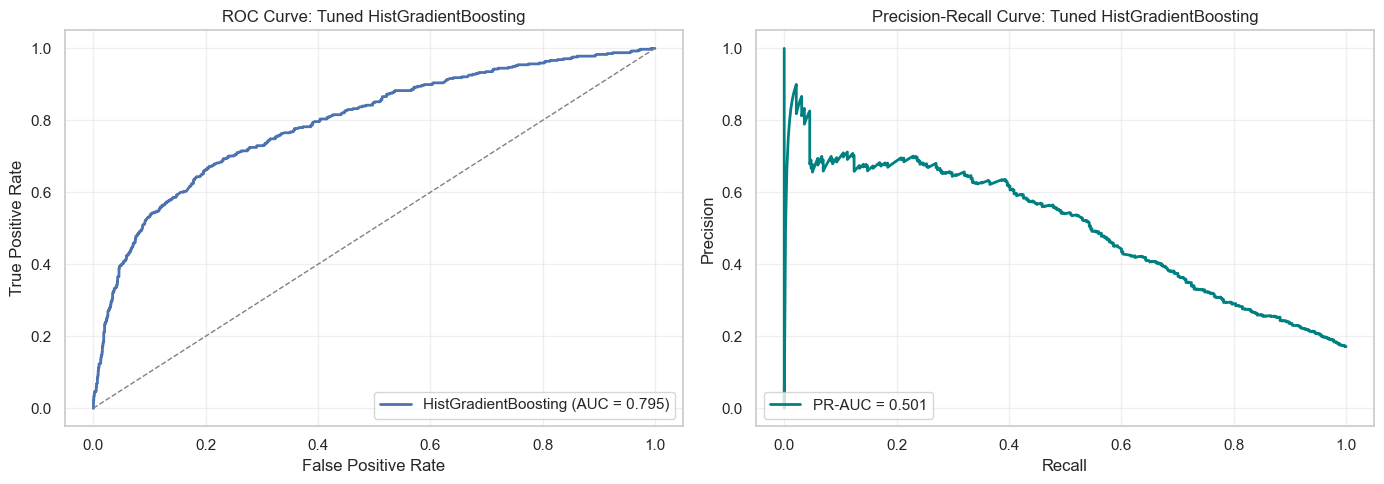

In [36]:
#improved model with more parameters and more iterations, but with early stopping to prevent overfitting 
cv_hist = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

param_dist_hist_gb = {
    'classifier__learning_rate': [0.01, 0.03, 0.05, 0.1],
    'classifier__max_iter': [100, 200, 300, 500],
    'classifier__max_depth': [None, 3, 5, 7],
    'classifier__max_leaf_nodes': [15, 31, 63],
    'classifier__min_samples_leaf': [10, 20, 50, 100],
    'classifier__l2_regularization': [0.0, 0.01, 0.1, 1.0],
    'classifier__early_stopping': [True],
    'classifier__validation_fraction': [0.1],
    'classifier__n_iter_no_change': [10]
}

hist_gb_search_tuned = RandomizedSearchCV(
    estimator=pipeline_hist_gb,
    param_distributions=param_dist_hist_gb,
    n_iter=20,
    cv=cv_hist,
    scoring=['roc_auc', 'neg_log_loss'],
    refit='roc_auc',
    n_jobs=-1,
    verbose=1,
    random_state=42
)

hist_gb_search_tuned.fit(X_class_train, y_class_train)

y_prob_hist_tuned = hist_gb_search_tuned.predict_proba(X_class_test)[:, 1]
y_pred_hist_tuned = hist_gb_search_tuned.predict(X_class_test)

print(f"Best tuned params: {hist_gb_search_tuned.best_params_}")
print(f"Best tuned CV ROC-AUC: {hist_gb_search_tuned.best_score_:.5f}")
print(f"Tuned training ROC-AUC: {hist_gb_search_tuned.score(X_class_train, y_class_train):.5f}")
print(f"Tuned test ROC-AUC: {hist_gb_search_tuned.score(X_class_test, y_class_test):.5f}")
print(f"Tuned test PR-AUC: {average_precision_score(y_class_test, y_prob_hist_tuned):.5f}")
print(f"Tuned test log loss: {log_loss(y_class_test, y_prob_hist_tuned):.5f}")
print(f"Tuned test F1: {f1_score(y_class_test, y_pred_hist_tuned):.5f}")
print(pd.DataFrame(
    confusion_matrix(y_class_test, y_pred_hist_tuned),
    columns=['pred: No', 'pred: Yes'],
    index=['real: No', 'real: Yes']
))
print(classification_report(y_class_test, y_pred_hist_tuned))

fpr_hist, tpr_hist, _ = roc_curve(y_class_test, y_prob_hist_tuned)
roc_auc_hist = auc(fpr_hist, tpr_hist)

precision_hist, recall_hist, _ = precision_recall_curve(y_class_test, y_prob_hist_tuned)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(fpr_hist, tpr_hist, linewidth=2, label=f'HistGradientBoosting (AUC = {roc_auc_hist:.3f})')
axes[0].plot([0, 1], [0, 1], linestyle='--', color='gray', linewidth=1)
axes[0].set_title('ROC Curve: Tuned HistGradientBoosting')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].legend(loc='lower right')
axes[0].grid(alpha=0.3)

axes[1].plot(
    recall_hist,
    precision_hist,
    linewidth=2,
    color='teal',
    label=f'PR-AUC = {average_precision_score(y_class_test, y_prob_hist_tuned):.3f}'
)
axes[1].set_title('Precision-Recall Curve: Tuned HistGradientBoosting')
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].legend(loc='lower left')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

### XGBoost - Model Evaluation

---

#### ROC-AUC

| Split | ROC-AUC |
|---|---|
| Cross-Validation | 0.78475 |
| Test | 0.77645 |

- CV and test scores are close → tuning is stable and overfitting is under control
- ROC-AUC of **0.776** reflects good ranking power - the model separates investors from non-investors clearly better than random, though substantial class overlap remains
- The ROC curve rises steeply early → the model is strong at identifying a **high-quality top segment** first, which is ideal for targeting a limited number of calls

---

#### PR-AUC

| Metric | Value |
|---|---|
| PR-AUC | 0.488 |

- The PR curve drops as recall increases - expected behaviour as discussed
- **0.488** is a strong result, consistent with the performance seen in the Logistic Regression baseline

---

#### Log Loss

| Model | Log Loss | vs. Naive Baseline |
|---|---|---|
| Naive baseline | 0.457 | — |
| XGBoost | 0.357 | **~10% improvement** |

> The model's probability scores are meaningful and usable for ranking and decision-making.

---

#### Overall Model Tuning

- Early stopping and leaf constraints are effectively keeping variance down
- Randomized search improved robustness, but further gains from hyperparameter tuning alone are subject to **diminishing returns**
> The next lever for improvement is **threshold optimization** based on expected business profit rather than continued hyperparameter search.

## 4.4 KNN

In [37]:
# 1. Update the numerical pipeline to include scaling
# KNN is a distance-based algorithm, so all features MUST be on the same scale
categorical_pipeline = Pipeline([
    ('impute', SimpleImputer(strategy = 'constant', fill_value = 'missing')),
    ('agg_and_dummies', OneHotEncoder(min_frequency = 0.1, handle_unknown = 'infrequent_if_exist',
                                     sparse_output = False, drop = None)),
    # ('interactions', PolynomialFeatures(degree=2, interaction_only=True, include_bias=False))
])

numerical_pipeline_class = Pipeline([
    ('impute', SimpleImputer(strategy = 'median'))
])

preprocessor_class = ColumnTransformer(
    transformers = [
        ('cat', categorical_pipeline, make_column_selector(dtype_include = ['object', 'category'])),
        ('num', numerical_pipeline_class, make_column_selector(dtype_include = ['number']))
    ], remainder = 'drop'
)

# 3. Create the KNN Pipeline
pipeline_knn = Pipeline([
    ('preprocessor', preprocessor_class),
    ('scaler', StandardScaler()),
    # ('selector', SelectKBest(f_classif, k=15)),
    ('pca', PCA(n_components=0.95)), # Keep 95% of the information, but in fewer columns
    ('classifier', KNeighborsClassifier())
])

In [38]:
# 4. Set parameters from your lab
# n_neighbors: How many 'friends' the model looks at to decide the class
# weights='distance': Closer neighbors have more influence than far ones
# p=2: Uses Euclidean distance (standard straight-line distance)
parameters_knn = {
    'classifier__n_neighbors': [3, 5, 7, 11, 21, 30],
    'classifier__weights': ['distance'],
    'classifier__p': [1, 2]
}

In [39]:
# 5. Initialize and run GridSearchCV
knn_search = GridSearchCV(
    estimator=pipeline_knn,
    param_grid=parameters_knn,
    cv=5,
    scoring=['roc_auc', 'neg_log_loss'], # Track both metrics
    refit= 'roc_auc',
    n_jobs=-1,
    verbose=1
)

In [40]:
knn_search.fit(X_class_train, y_class_train)

Fitting 5 folds for each of 12 candidates, totalling 60 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...lassifier())])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'classifier__n_neighbors': [3, 5, ...], 'classifier__p': [1, 2], 'classifier__weights': ['distance']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.","['roc_auc', 'neg_log_loss']"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'roc_auc'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and 

In [41]:
# 6. Evaluation
print(f"Best KNN Parameters: {knn_search.best_params_}")
print(f"Training Set Score: {knn_search.best_score_}")
print(f"Test Set Score: {knn_search.score(X_class_test, y_class_test)}")

Best KNN Parameters: {'classifier__n_neighbors': 30, 'classifier__p': 1, 'classifier__weights': 'distance'}
Training Set Score: 0.7403425933926367
Test Set Score: 0.7420544199390354


### KNN Model - Results

| Parameter | Value |
|---|---|
| `n_neighbors` | 30 |
| `p` (distance metric) | 1 (Manhattan distance) |
| `weights` | distance |


| Split | ROC-AUC |
|---|---|
| Training | 0.74034 |
| Test | 0.74205 |


The model generalizes well with virtually no overfitting (train ≈ test). However, with a test ROC-AUC of **0.742**, it performs slightly below our Random Forest baseline — and KNN is significantly more expensive at inference time, making it a less attractive option for production use.

## 4.5 Regularization Ridge

In [42]:
pipeline_RR = Pipeline([
    ('preprocessor', preprocessor_class),
    ('variance', VarianceThreshold(threshold=1e-5)),
    ('classifier', RidgeClassifier())
])

In [43]:
# generates an array of 100 values that are logarithmically spaced between 0.01 and 10 billion
list_alpha = 10**np.linspace(-2, 10, 100)
list_alpha

array([1.00000000e-02, 1.32194115e-02, 1.74752840e-02, 2.31012970e-02,
       3.05385551e-02, 4.03701726e-02, 5.33669923e-02, 7.05480231e-02,
       9.32603347e-02, 1.23284674e-01, 1.62975083e-01, 2.15443469e-01,
       2.84803587e-01, 3.76493581e-01, 4.97702356e-01, 6.57933225e-01,
       8.69749003e-01, 1.14975700e+00, 1.51991108e+00, 2.00923300e+00,
       2.65608778e+00, 3.51119173e+00, 4.64158883e+00, 6.13590727e+00,
       8.11130831e+00, 1.07226722e+01, 1.41747416e+01, 1.87381742e+01,
       2.47707636e+01, 3.27454916e+01, 4.32876128e+01, 5.72236766e+01,
       7.56463328e+01, 1.00000000e+02, 1.32194115e+02, 1.74752840e+02,
       2.31012970e+02, 3.05385551e+02, 4.03701726e+02, 5.33669923e+02,
       7.05480231e+02, 9.32603347e+02, 1.23284674e+03, 1.62975083e+03,
       2.15443469e+03, 2.84803587e+03, 3.76493581e+03, 4.97702356e+03,
       6.57933225e+03, 8.69749003e+03, 1.14975700e+04, 1.51991108e+04,
       2.00923300e+04, 2.65608778e+04, 3.51119173e+04, 4.64158883e+04,
      

In [44]:
# Define the parameter grid for alpha
parameters = {'classifier__alpha': list_alpha}

In [45]:
# Initialize GridSearchCV
ridge_classif = GridSearchCV(
    estimator=pipeline_RR,
    param_grid=parameters,
    cv=5,
    verbose=2,
    n_jobs=-1,
    scoring='roc_auc'  # Scoring method
)

In [46]:
# Fit GridSearchCV
ridge_classif.fit(X_class_train, y_class_train)

Fitting 5 folds for each of 100 candidates, totalling 500 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...lassifier())])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.",{'classifier__alpha': array([1.0000...00000000e+10])}
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'roc_auc'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candidate is displayed;- >2 : the score is also displayed;- >3 : t

In [47]:
best_ridge = ridge_classif.best_estimator_.named_steps["classifier"]
print(best_ridge.coef_)  # Coefficients
print(best_ridge.intercept_)

[ 6.94509080e-03 -3.37074143e-03 -2.64537917e-02  2.28794424e-02
  2.79634060e-03 -4.02489034e-02  3.74525628e-02 -3.64029422e-02
 -1.61856652e-02  1.05073610e-02  4.20812464e-02  6.02688309e-02
 -8.02665684e-02  1.99977375e-02  6.77684663e-02 -6.77684663e-02
  5.94426603e-02 -5.94426603e-02 -2.82512027e-01 -2.88432975e-01
  5.70945003e-01  1.38992832e-03  7.69798455e-07  9.80377052e-03
  2.53213985e-02]
[-0.60765662]


In [48]:
# Extract the results into a DataFrame
results = pd.DataFrame(ridge_classif.cv_results_)
results

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_classifier__alpha,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
0,0.313599,0.017568,0.045049,0.005684,1.000000e-02,{'classifier__alpha': 0.01},0.771822,0.784287,0.753559,0.765626,0.749625,0.764984,0.012540,17
1,0.315738,0.016407,0.047258,0.006220,1.321941e-02,{'classifier__alpha': 0.013219411484660288},0.771822,0.784289,0.753559,0.765626,0.749625,0.764984,0.012540,14
2,0.279525,0.016664,0.054476,0.003759,1.747528e-02,{'classifier__alpha': 0.01747528400007684},0.771822,0.784289,0.753559,0.765626,0.749625,0.764984,0.012540,14
3,0.279210,0.027219,0.042779,0.007736,2.310130e-02,{'classifier__alpha': 0.023101297000831605},0.771822,0.784287,0.753560,0.765624,0.749627,0.764984,0.012539,13
4,0.291498,0.012610,0.043514,0.003989,3.053856e-02,{'classifier__alpha': 0.030538555088334154},0.771820,0.784287,0.753560,0.765624,0.749627,0.764984,0.012539,16
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,0.305108,0.017083,0.048322,0.007182,3.274549e+09,{'classifier__alpha': 3274549162.877732},0.562398,0.597124,0.585898,0.596047,0.588261,0.585946,0.012545,89
96,0.312379,0.016372,0.052141,0.002290,4.328761e+09,{'classifier__alpha': 4328761281.083061},0.562378,0.597052,0.585903,0.596012,0.588288,0.585927,0.012535,90
97,0.298734,0.011688,0.048642,0.003556,5.722368e+09,{'classifier__alpha': 5722367659.35022},0.562352,0.597004,0.585877,0.595990,0.588285,0.585902,0.012532,91
98,0.271601,0.012346,0.031437,0.002884,7.564633e+09,{'classifier__alpha': 7564633275.54629},0.562352,0.596967,0.585864,0.595963,0.588292,0.585888,0.012522,92


In [49]:
X_processed = preprocessor_class.fit_transform(X_class_train, y_class_train)

In [50]:
# Retrieve the coefficients for each alpha value
coeff_matrix = {}
validation_scores = []

for i, alpha in enumerate(ridge_classif.cv_results_['param_classifier__alpha']):
    # Refit a Ridge model with preprocessing and the specific alpha to get coefficients
    model = RidgeClassifier(alpha=alpha)
    model.fit(X_processed, y_class_train)
    coeff_matrix[alpha] = model.coef_.ravel().tolist()
    
    # Get the corresponding roc_auc score
    roc_auc = ridge_classif.cv_results_['mean_test_score'][i]
    validation_scores.append((alpha, roc_auc))

In [51]:
# Extract feature names after preprocessing
feature_names = preprocessor_class.get_feature_names_out()

# Convert feature names from transformers (they have prefixes 'num__', 'cat__')
feature_names = [name.split('__')[-1] for name in feature_names]

# Use these names as index in the coefficient DataFrame
coeff_df = pd.DataFrame(coeff_matrix, index=feature_names).T
coeff_df.tail()

,job_blue-collar,job_management,job_technician,job_infrequent_sklearn,marital_divorced,marital_married,marital_single,education_primary,education_secondary,education_tertiary,...,loan_house_yes,loan_personal_no,loan_personal_yes,marketing_potential_low,marketing_potential_unknown,marketing_potential_infrequent_sklearn,age,balance,n_marketing_contacts,period
3.274549e+09,-6.031069e-08,2.576350e-08,-1.279363e-08,4.734083e-08,1.594209e-09,-5.789845e-08,5.630424e-08,-3.711123e-08,-3.984386e-08,6.502743e-08,...,-1.849400e-07,7.223823e-08,-7.223823e-08,-1.764890e-08,-2.388044e-07,2.564533e-07,8.933315e-07,0.000005,7.944379e-07,5.089920e-07
4.328761e+09,-4.562982e-08,1.949658e-08,-9.679623e-09,3.581285e-08,1.205406e-09,-4.379204e-08,4.258663e-08,-2.807477e-08,-3.015215e-08,4.920412e-08,...,-1.399121e-07,5.465368e-08,-5.465368e-08,-1.334972e-08,-1.806473e-07,1.939970e-07,6.761833e-07,0.000005,6.009768e-07,3.851545e-07
5.722368e+09,-3.452414e-08,1.475586e-08,-7.323912e-09,2.709219e-08,9.111546e-10,-3.312147e-08,3.221032e-08,-2.123913e-08,-2.282054e-08,3.723433e-08,...,-1.058499e-07,4.135148e-08,-4.135148e-08,-1.009761e-08,-1.366535e-07,1.467511e-07,5.118881e-07,0.000005,4.546293e-07,2.914744e-07
7.564633e+09,-2.612297e-08,1.116960e-08,-5.541845e-09,2.049521e-08,6.884925e-10,-2.504986e-08,2.436136e-08,-1.606827e-08,-1.727425e-08,2.817949e-08,...,-8.008271e-08,3.128872e-08,-3.128872e-08,-7.637554e-09,-1.033736e-07,1.110112e-07,3.875847e-07,0.000005,3.439219e-07,2.206069e-07
1.000000e+10,-1.976765e-08,8.456607e-09,-4.193728e-09,1.550477e-08,5.200251e-10,-1.894419e-08,1.842416e-08,-1.215671e-08,-1.307845e-08,2.132962e-08,...,-6.059054e-08,2.367645e-08,-2.367645e-08,-5.776645e-09,-7.819861e-08,8.397525e-08,2.935386e-07,0.000005,2.601752e-07,1.669959e-07


In [52]:
# Select the first 20 columns from coeff_df
coeff_df_first_20 = coeff_df.iloc[:, :20]

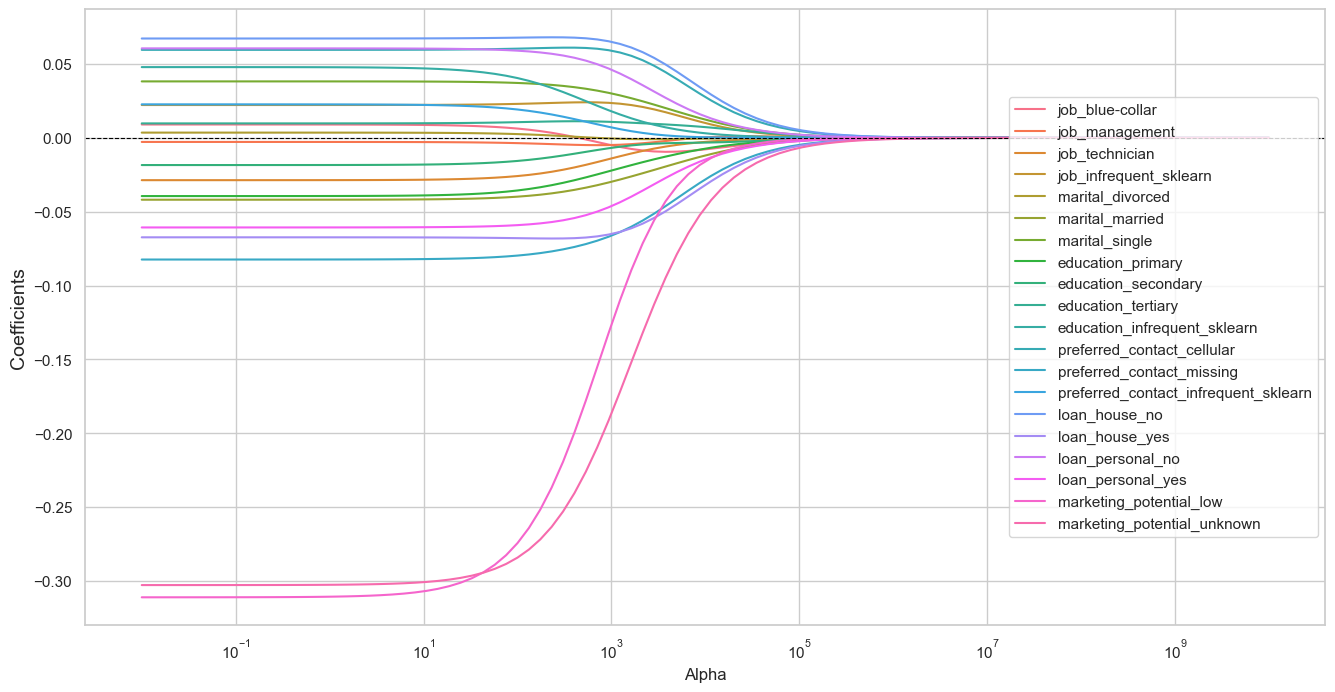

In [53]:
plt.figure(figsize=(16,8))
sns.lineplot(data=coeff_df_first_20, dashes=False)
plt.axhline(y=0, linestyle='dashed', lw=0.8, color='black')
plt.xscale('log')
plt.ylabel('Coefficients', fontsize=14)
plt.xlabel('Alpha')
plt.legend(loc='right')
plt.show()

In [54]:
# for small alpha the coefficients are bigger, chek for bigger alpha
coeff_df.iloc[0:2]

,job_blue-collar,job_management,job_technician,job_infrequent_sklearn,marital_divorced,marital_married,marital_single,education_primary,education_secondary,education_tertiary,...,loan_house_yes,loan_personal_no,loan_personal_yes,marketing_potential_low,marketing_potential_unknown,marketing_potential_infrequent_sklearn,age,balance,n_marketing_contacts,period
0.010000,0.009075,-0.00273,-0.028611,0.022266,0.003585,-0.041845,0.038259,-0.039378,-0.018376,0.009822,...,-0.0673,0.060617,-0.060617,-0.311014,-0.302735,0.613749,0.001335,0.000001,0.008696,0.022382
0.013219,0.009075,-0.00273,-0.028611,0.022266,0.003585,-0.041845,0.038259,-0.039378,-0.018376,0.009822,...,-0.0673,0.060617,-0.060617,-0.311013,-0.302734,0.613747,0.001335,0.000001,0.008696,0.022382


In [55]:
# Convert the validation scores to a DataFrame
validation_scores_df = pd.DataFrame(validation_scores, columns=['alpha', 'roc_auc'])
validation_scores_df.head(3)

,alpha,roc_auc
0,0.010000,0.764984
1,0.013219,0.764984
2,0.017475,0.764984


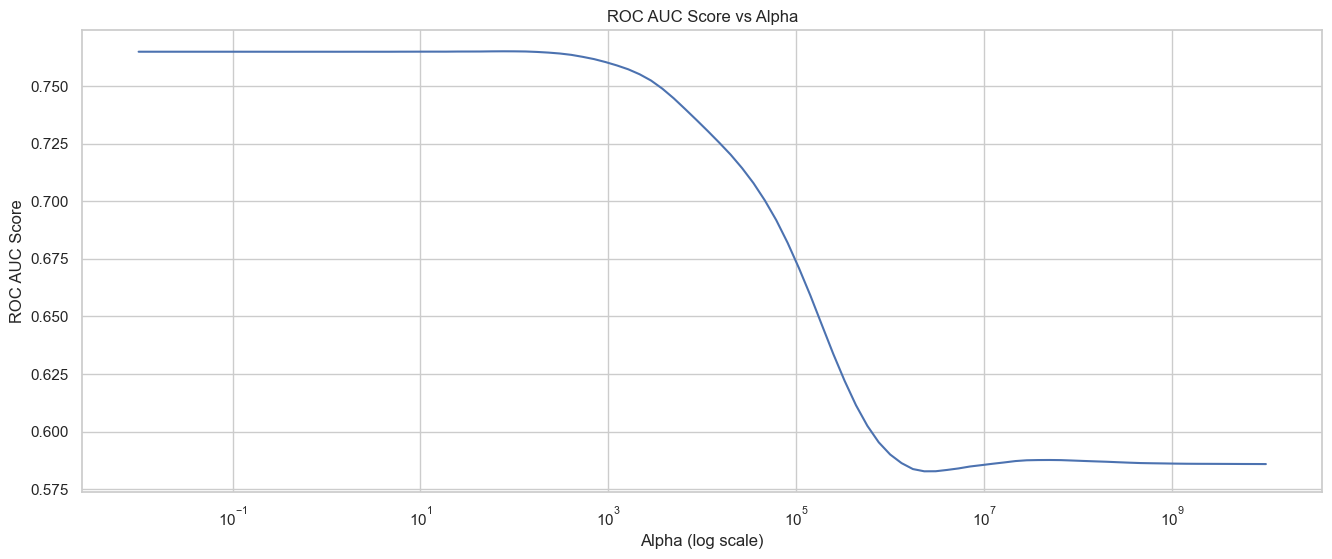

In [56]:
# Extract alpha values and roc_auc scores from validation_scores
alpha_values, roc_auc_scores = zip(*validation_scores)

# Create the lineplot
sns.lineplot(x=alpha_values, y=roc_auc_scores)
plt.xscale('log')  # Use log scale for x-axis (alpha values)
plt.xlabel('Alpha (log scale)')
plt.ylabel('ROC AUC Score')
plt.title('ROC AUC Score vs Alpha')
plt.show()

In [57]:
# Find the alpha corresponding to the best roc_auc
best_alpha = validation_scores_df.loc[validation_scores_df['roc_auc'].idxmax(), :]
best_alpha

alpha      75.646333
roc_auc     0.765165
Name: 32, dtype: float64

### Ridge Regression - Results

| Parameter | Value |
|---|---|
| Best `alpha` | 75.646 |
| ROC-AUC | 0.76516 |

A high regularization strength (`alpha = 75.646`) was selected, indicating that **strong penalization of coefficients** leads to the best generalization. With a ROC-AUC of **0.765**, the model performs competitively.

## 4.6 Regularization Lasso

In [58]:
from sklearn.linear_model import LogisticRegression

pipeline_RL = Pipeline([
    ('preprocessor', preprocessor_class),
    ('variance', VarianceThreshold(threshold=1e-5)),
    ('classifier', LogisticRegression(penalty='l1', solver='saga', max_iter=1000))  # L1 regularization is Lasso
])

In [59]:
# Define the parameter grid for alpha (C is the inverse of regularization strength)
parameters = {
    'classifier__C': 10**np.linspace(-2, 2, 10)  # Explore regularization strength
}

In [60]:
list_C = 10**np.linspace(-2, 2, 10)

In [61]:
# Initialize GridSearchCV
lasso = GridSearchCV(
    estimator=pipeline_RL,
    param_grid=parameters,
    cv=5,
    verbose=2,
    n_jobs=-1,
    scoring='roc_auc'  # Scoring method
)

In [62]:
# Fit GridSearchCV
lasso.fit(X_class_train, y_class_train)

Fitting 5 folds for each of 10 candidates, totalling 50 fits


C:\Users\Alexa\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\Alexa\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\linear_model\_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...ver='saga'))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.",{'classifier__C': array([1.0000...00000000e+02])}
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'roc_auc'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candidate is displayed;- >2 : the score is also displayed;- >3 : the f

In [63]:
# Extract the results into a DataFrame
results = pd.DataFrame(lasso.cv_results_)
results

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_classifier__C,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
0,19.690306,0.175075,0.041412,0.011085,0.010000,{'classifier__C': 0.01},0.460410,0.423884,0.436579,0.419954,0.454470,0.439059,0.016092,10
1,19.981281,0.134696,0.055626,0.007451,0.027826,{'classifier__C': 0.027825594022071243},0.460405,0.423855,0.436562,0.419971,0.454532,0.439065,0.016105,9
2,20.175136,0.400141,0.054088,0.009522,0.077426,{'classifier__C': 0.0774263682681127},0.460408,0.423858,0.436555,0.419966,0.454542,0.439066,0.016108,8
3,20.794774,0.279653,0.071685,0.009661,0.215443,{'classifier__C': 0.21544346900318834},0.460406,0.423857,0.436558,0.419975,0.454549,0.439069,0.016107,5
4,20.919965,0.479684,0.065395,0.009224,0.599484,{'classifier__C': 0.5994842503189409},0.460417,0.423858,0.436560,0.419975,0.454545,0.439071,0.016109,2
5,21.414864,0.608423,0.048033,0.009068,1.668101,{'classifier__C': 1.6681005372000592},0.460421,0.423851,0.436557,0.419975,0.454547,0.439070,0.016112,3
6,21.586297,0.221402,0.062432,0.013244,4.641589,{'classifier__C': 4.6415888336127775},0.460408,0.423851,0.436560,0.419967,0.454547,0.439067,0.016110,7
7,21.505273,0.194327,0.057134,0.012316,12.915497,{'classifier__C': 12.915496650148826},0.460419,0.423853,0.436557,0.419975,0.454547,0.439070,0.016111,3
8,15.142570,5.175265,0.036526,0.008243,35.938137,{'classifier__C': 35.93813663804626},0.460423,0.423857,0.436557,0.419978,0.454547,0.439072,0.016111,1
9,10.700995,0.119649,0.030360,0.001885,100.000000,{'classifier__C': 100.0},0.460419,0.423847,0.436557,0.419973,0.454547,0.439069,0.016113,6


In [64]:
# Retrieve the coefficients for each alpha value
coeff_lasso = {}
validation_scores = []

for i, C in enumerate(lasso.cv_results_['param_classifier__C']):
    # Refit a Lasso model with preprocessing and the specific C to get coefficients
    model = LogisticRegression(penalty='l1', solver='saga', max_iter=1000, C=C)
    model.fit(X_processed, y_class_train)
    coeff_lasso[C] = model.coef_.ravel().tolist()
    
    # Get the corresponding roc_auc score
    roc_auc = lasso.cv_results_['mean_test_score'][i]
    validation_scores.append((C, roc_auc))

C:\Users\Alexa\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\Alexa\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\linear_model\_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
C:\Users\Alexa\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'pen

In [65]:
# Convert coefficients to a DataFrame for easier analysis
lasso_df = pd.DataFrame(coeff_lasso, index=[f'Feature_{i}' for i in range(X_processed.shape[1])]).T
lasso_df.head()

,Feature_0,Feature_1,Feature_2,Feature_3,Feature_4,Feature_5,Feature_6,Feature_7,Feature_8,Feature_9,...,Feature_15,Feature_16,Feature_17,Feature_18,Feature_19,Feature_20,Feature_21,Feature_22,Feature_23,Feature_24
0.010000,-0.000062,-0.000074,-0.000041,-0.000094,-0.000020,-0.000175,-0.000093,-0.000030,-0.000151,-0.000099,...,-0.000209,-0.000256,-0.000052,-0.000023,-0.000333,0.000029,-0.013260,-0.000108,-0.000036,-0.000022
0.027826,-0.000074,-0.000086,-0.000053,-0.000106,-0.000033,-0.000187,-0.000105,-0.000042,-0.000163,-0.000111,...,-0.000221,-0.000268,-0.000064,-0.000035,-0.000345,0.000041,-0.013269,-0.000108,-0.000048,-0.000034
0.077426,-0.000078,-0.000090,-0.000057,-0.000110,-0.000037,-0.000192,-0.000109,-0.000047,-0.000167,-0.000115,...,-0.000225,-0.000272,-0.000068,-0.000039,-0.000349,0.000046,-0.013273,-0.000108,-0.000052,-0.000039
0.215443,-0.000080,-0.000092,-0.000059,-0.000112,-0.000038,-0.000193,-0.000111,-0.000048,-0.000169,-0.000117,...,-0.000227,-0.000274,-0.000070,-0.000041,-0.000351,0.000047,-0.013273,-0.000108,-0.000053,-0.000040
0.599484,-0.000080,-0.000092,-0.000059,-0.000112,-0.000039,-0.000194,-0.000112,-0.000049,-0.000169,-0.000117,...,-0.000227,-0.000274,-0.000070,-0.000041,-0.000351,0.000048,-0.013274,-0.000108,-0.000054,-0.000041


In [66]:
# Select the first 10 columns from lasso_df
coeff_df_last_10 = lasso_df.iloc[:, :10]

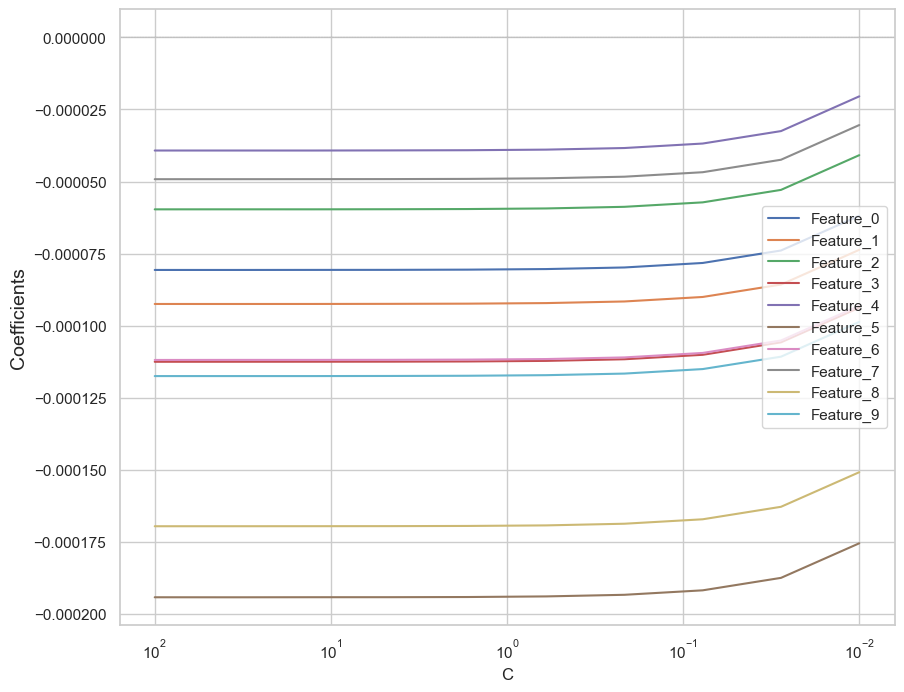

In [67]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10,8))
sns.lineplot(data=coeff_df_last_10, dashes=False)
plt.axhline(y=0, linestyle='dashed', lw=0.1, color='black')
plt.gca().invert_xaxis()  # Reverse the x-axis so that larger values of C (weaker regularization) are shown first
plt.xscale('log')
plt.ylabel('Coefficients', fontsize=14)
plt.xlabel('C')
plt.legend(loc='right')
plt.show()

In [68]:
# Convert the validation scores to a DataFrame
validation_scores_df = pd.DataFrame(validation_scores, columns=['C', 'roc_auc'])
validation_scores_df.head(3)

,C,roc_auc
0,0.010000,0.439059
1,0.027826,0.439065
2,0.077426,0.439066


## 4.7 XGBoost

In [69]:
pipeline_xgb = Pipeline([
    ('preprocessor', preprocessor_class),
    ('classifier', xgb.XGBClassifier(
        objective='binary:logistic',
        eval_metric='logloss',
        random_state=42
    ))
])

param_grid_class = {
    'classifier__learning_rate': [0.01, 0.1],
    'classifier__n_estimators': [100, 300],
    'classifier__max_depth': [3, 5],
    'classifier__subsample': [0.8, 1.0]
}

grid_class = GridSearchCV(
    pipeline_xgb,
    param_grid_class,
    scoring= ['roc_auc', 'neg_log_loss'],
    refit='roc_auc',
    cv=5,
    n_jobs=-1
)

grid_class.fit(X_class_train, y_class_train)

best_clf = grid_class.best_estimator_
print(f"Best Classifier Params: {grid_class.best_params_}")

prob_purchase = best_clf.predict_proba(X_class_test)[:, 1]
# XGBoost GridSearchCV scores (ROC-AUC, because scoring='roc_auc')
print('Training set score: ' + str(grid_class.score(X_class_train, y_class_train)))
print('Test set score: ' + str(grid_class.score(X_class_test, y_class_test)))

# Optional explicit check of CV best score
print('Best CV score: ' + str(grid_class.best_score_))

Best Classifier Params: {'classifier__learning_rate': 0.01, 'classifier__max_depth': 5, 'classifier__n_estimators': 300, 'classifier__subsample': 0.8}
Training set score: 0.8194208526125364
Test set score: 0.7961658786557572
Best CV score: 0.7825288593322369


### XGBoost - Tuned Parameters & Results

---

#### Best Hyperparameters

| Parameter | Value |
|---|---|
| `learning_rate` | 0.01 |
| `max_depth` | 5 |
| `n_estimators` | 300 |
| `subsample` | 0.8 |

---

#### Performance

| Split | Score |
|---|---|
| Training | 0.81942 |
| Cross-Validation | 0.78253 |
| Test | 0.79617 |

> The ~2.3% gap between training and test scores indicates **no major overfitting**. The Lasso model generalizes well and doesn't overfit.

## 4.8 Stacking Models

### Stacking Models for Classification

In [70]:
# # from xgboost import XGBClassifier

# # Define the stacking ensemble
# def get_stacking():
#     # Base models
#     level0 = [
#         ('rf', RandomForestClassifier(random_state=42)),
#         ('knn', KNeighborsClassifier()),
#         ('ridge', RidgeClassifier()),
#         ('lasso', LogisticRegression(penalty='l1', solver='saga', max_iter=1000)),
#         # ('xgb', XGBClassifier(eval_metric='logloss', random_state=42)),
#     ]
#     # Meta-learner
#     level1 = LogisticRegression(max_iter=1000)
#     # Stacking model
#     model = StackingClassifier(estimators=level0, final_estimator=level1, cv=3)
#     return model

In [71]:
# # Create the pipeline
# stacking_model = get_stacking()
# pipeline_stack_class = Pipeline([
#     ('preprocessor', preprocessor_class),
#     ('classifier', stacking_model)
# ])

In [72]:
# ### LAB 6 dont know how right this is ###

# # Define the parameter grid for GridSearchCV
# parameters = {
#     # Base model parameters
#     'classifier__rf__n_estimators': [200],
#     'classifier__rf__max_depth': [5, 10],
#     'classifier__knn__n_neighbors': [5, 7],
#     'classifier__ridge__alpha': [0.1, 1, 10],
#     'classifier__lasso__C': [0.1, 1, 10],
#     # 'classifier__xgb__n_estimators': [100],
#     # 'classifier__xgb__max_depth': [3, 5],
#     # 'classifier__xgb__learning_rate': [0.05, 0.1],
#     # Meta-learner parameter
#     'classifier__final_estimator__C': [0.1, 1, 10],
# }

In [73]:
# # Perform grid search with the pipeline
# stacking_classif = GridSearchCV(
#     estimator=pipeline_stack_class,
#     param_grid=parameters,
#     scoring='roc_auc',
#     cv=5,
#     n_jobs=-1,
#     verbose=1
# )

In [74]:
# this takes around 20 minutes to run, maybe change something

# Use the existing classification train/test split from the notebook
# Fit the grid search to the training data
# stacking_classif.fit(X_class_train, y_class_train)

In [75]:
# # Retrieve the cross-validated roc_auc score for the best model
# best_roc_auc = stacking_classif.best_score_
# print("Best ROC AUC Score (Cross-Validated):", best_roc_auc)

# # Retrieve the best parameters
# print("Best Parameters:", stacking_classif.best_params_)

# # Retrieve all mean ROC AUC scores for each parameter combination
# cv_results = stacking_classif.cv_results_['mean_test_score']
# print("All ROC AUC Scores:", cv_results)

In [76]:
# # Evaluate performance
# preds_stack_test = stacking_classif.predict_proba(X_class_test)[:, 1]  # Predicted probabilities for positive class
# print(f"ROC-AUC on the test set: {roc_auc_score(y_class_test, preds_stack_test):.5f}")
# print(f"F1 on the test set: {f1_score(y_class_test, stacking_classif.predict(X_class_test)):.5f}")
# print()

## 4.9 Compare Several Models at Once with Nested Cross-Validation

In [77]:
models = [
    ('classifier_reg', LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced'), {
    'var_filter__threshold': [0.0, 0.01, 0.05],
    'classifier__C': [0.1, 1.0, 10.0],
    'classifier__class_weight': ['balanced', None]
    }),
    ('RF', RandomForestClassifier(class_weight="balanced", random_state=42), {
        'classifier__n_estimators': [200, 500],
        'classifier__max_depth': [5, 10, 15],      # Lowered to prevent deep overfitting
        'classifier__min_samples_leaf': [20, 50],  # Significantly increased to force generalization
        'classifier__max_features': ['log2']
    }),
    ('KNN', KNeighborsClassifier(), {
        'classifier__n_neighbors': [5, 11, 21, 31],
        'classifier__weights': ['distance'],
        'classifier__p': [1, 2]
    }),
    ('Ridge_L2', LogisticRegression(penalty='l2', solver='saga', max_iter=1000, class_weight='balanced'), {
        'classifier__C': np.logspace(-3, 3, 10)
    }),
    ('Lasso_L1', LogisticRegression(penalty='l1', solver='liblinear', max_iter=1000, class_weight='balanced'), {
        'classifier__C': np.logspace(-3, 3, 10)
    }),
    ('HistGB', HistGradientBoostingClassifier(random_state=42), {
         'classifier__learning_rate': [0.01, 0.03, 0.05, 0.1],
         'classifier__max_iter': [100, 200, 300, 500],
         'classifier__max_depth': [None, 3, 5, 7],
         'classifier__max_leaf_nodes': [15, 31, 63],
         'classifier__min_samples_leaf': [10, 20, 50, 100],
         'classifier__l2_regularization': [0.0, 0.01, 0.1, 1.0],
         'classifier__early_stopping': [True],
         'classifier__validation_fraction': [0.1],
         'classifier__n_iter_no_change': [10]
    }),
    ('XGB', xgb.XGBClassifier(objective='binary:logistic', eval_metric='logloss', random_state=42), {
        'classifier__learning_rate': [0.01, 0.1],
        'classifier__n_estimators': [100, 300],
        'classifier__max_depth': [3, 5],
        'classifier__subsample': [0.8, 1.0]
    })
]

In [78]:
outer_cv = KFold(n_splits=5, shuffle=True, random_state=42)

ncv_models = {}
dfn = []  

for name, model, parameters in models:
    pipeline = Pipeline([
        ('preprocessor', preprocessor_class),
        ('var_filter', VarianceThreshold()),
        ('classifier', model)
    ])
    
    ncv_search = RandomizedSearchCV(
        estimator=pipeline,
        param_distributions=parameters,
        n_iter=5,             
        scoring='roc_auc',
        cv=3,
        verbose=0,
        random_state=42,
        n_jobs=-1
    )

    cv_results = cross_validate(
        ncv_search, 
        X_class_train, 
        y_class_train, 
        cv=outer_cv, 
        scoring=['roc_auc', 'neg_log_loss'], 
        n_jobs=-1
    )

    outer_auc = cv_results['test_roc_auc']
    outer_logloss = -cv_results['test_neg_log_loss'] 

    ncv_search.fit(X_class_train, y_class_train)
    ncv_models[name] = ncv_search.best_estimator_

    y_pred = ncv_models[name].predict(X_class_test)
    y_prob = ncv_models[name].predict_proba(X_class_test)[:, 1]

    precision = precision_score(y_class_test, y_pred, pos_label=1)
    recall = recall_score(y_class_test, y_pred, pos_label=1)
    f1 = f1_score(y_class_test, y_pred, pos_label=1)
    pr_auc = average_precision_score(y_class_test, y_prob)

    print(f"\n--- Model Evaluation: {name} ---")
    print(f"Mean ROC AUC:  {outer_auc.mean():.4f} (+/- {outer_auc.std():.4f})")
    print(f"\nInvestor-Focused Metrics (class = 1):")
    print(f"  Precision: {precision:.4f}  → of all predicted investors, how many truly invested")
    print(f"  Recall:    {recall:.4f}  → of all true investors, how many did we catch")
    print(f"  F1-Score:  {f1:.4f}")
    print(f"  PR-AUC:    {pr_auc:.4f}  → overall quality on minority class")

    ncv_df = pd.DataFrame({
        'model': name,
        'outer_auc': outer_auc,
        'outer_logloss': outer_logloss
    })
    dfn.append(ncv_df)

nested_results = pd.concat(dfn, ignore_index=True)


--- Model Evaluation: classifier_reg ---
Mean ROC AUC:  0.7678 (+/- 0.0091)

Investor-Focused Metrics (class = 1):
  Precision: 0.3411  → of all predicted investors, how many truly invested
  Recall:    0.7033  → of all true investors, how many did we catch
  F1-Score:  0.4594
  PR-AUC:    0.4796  → overall quality on minority class

--- Model Evaluation: RF ---
Mean ROC AUC:  0.7825 (+/- 0.0105)

Investor-Focused Metrics (class = 1):
  Precision: 0.3884  → of all predicted investors, how many truly invested
  Recall:    0.6914  → of all true investors, how many did we catch
  F1-Score:  0.4974
  PR-AUC:    0.4943  → overall quality on minority class

--- Model Evaluation: KNN ---
Mean ROC AUC:  0.6374 (+/- 0.0215)

Investor-Focused Metrics (class = 1):
  Precision: 0.4138  → of all predicted investors, how many truly invested
  Recall:    0.0287  → of all true investors, how many did we catch
  F1-Score:  0.0537
  PR-AUC:    0.2546  → overall quality on minority class


C:\Users\Alexa\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(



--- Model Evaluation: Ridge_L2 ---
Mean ROC AUC:  0.5915 (+/- 0.0099)

Investor-Focused Metrics (class = 1):
  Precision: 0.2048  → of all predicted investors, how many truly invested
  Recall:    0.7536  → of all true investors, how many did we catch
  F1-Score:  0.3221
  PR-AUC:    0.1924  → overall quality on minority class


C:\Users\Alexa\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\Alexa\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\linear_model\_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(



--- Model Evaluation: Lasso_L1 ---
Mean ROC AUC:  0.7676 (+/- 0.0090)

Investor-Focused Metrics (class = 1):
  Precision: 0.3415  → of all predicted investors, how many truly invested
  Recall:    0.7010  → of all true investors, how many did we catch
  F1-Score:  0.4592
  PR-AUC:    0.4789  → overall quality on minority class

--- Model Evaluation: HistGB ---
Mean ROC AUC:  0.7841 (+/- 0.0113)

Investor-Focused Metrics (class = 1):
  Precision: 0.6316  → of all predicted investors, how many truly invested
  Recall:    0.2871  → of all true investors, how many did we catch
  F1-Score:  0.3947
  PR-AUC:    0.4807  → overall quality on minority class

--- Model Evaluation: XGB ---
Mean ROC AUC:  0.7773 (+/- 0.0118)

Investor-Focused Metrics (class = 1):
  Precision: 0.6494  → of all predicted investors, how many truly invested
  Recall:    0.1196  → of all true investors, how many did we catch
  F1-Score:  0.2020
  PR-AUC:    0.4773  → overall quality on minority class


C:\Users\Alexa\AppData\Local\Temp\ipykernel_18680\2222294491.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=nested_results, x='model', y='outer_auc', palette='viridis')


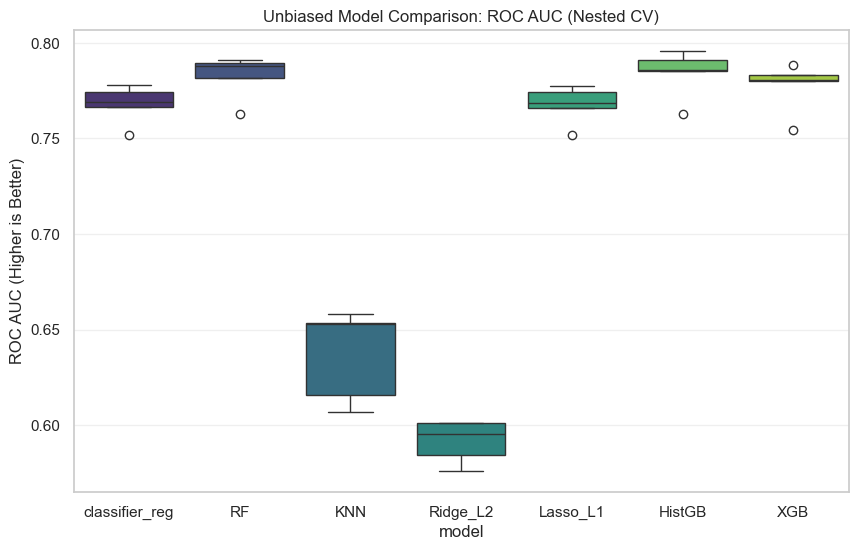

C:\Users\Alexa\AppData\Local\Temp\ipykernel_18680\2222294491.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=nested_results, x='model', y='outer_auc', palette=colors, errorbar=None, order=models_order)


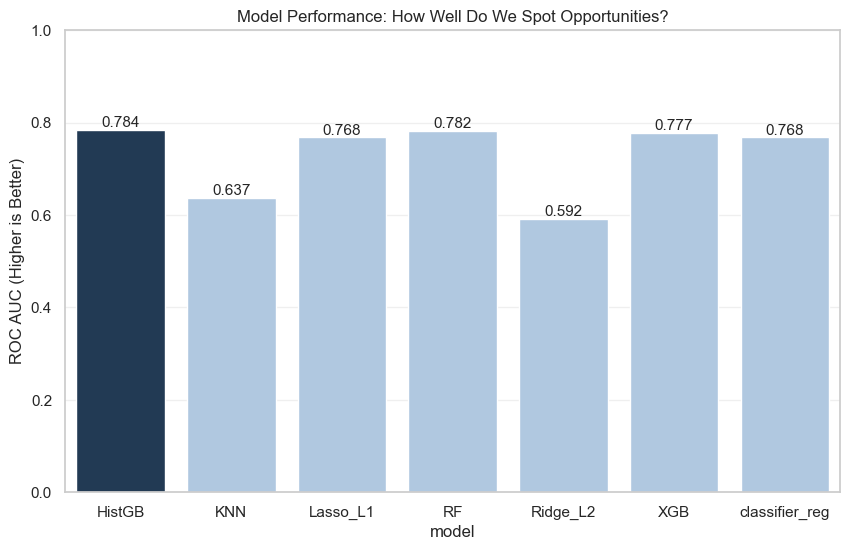

In [79]:
# --- Graph 1: ROC AUC Distribution ---
plt.figure(figsize=(10, 6))
sns.boxplot(data=nested_results, x='model', y='outer_auc', palette='viridis')
plt.title('Unbiased Model Comparison: ROC AUC (Nested CV)')
plt.ylabel('ROC AUC (Higher is Better)')
plt.grid(axis='y', alpha=0.3)
plt.show()

# --- Graph 1: ROC AUC Distribution ---
mean_aucs = nested_results.groupby('model')['outer_auc'].mean()
best_model = mean_aucs.idxmax()
models_order = mean_aucs.index.tolist()

colors = ['#1a3a5c' if m == best_model else '#a8c8e8' for m in models_order]

plt.figure(figsize=(10, 6))
ax = sns.barplot(data=nested_results, x='model', y='outer_auc', palette=colors, errorbar=None, order=models_order)

for p in ax.patches:
    ax.annotate(f'{p.get_height():.3f}', 
                (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='bottom', fontsize=11)

plt.title('Model Performance: How Well Do We Spot Opportunities?')
plt.ylabel('ROC AUC (Higher is Better)')
plt.ylim(0, 1.0)
plt.grid(axis='y', alpha=0.3)
plt.show()

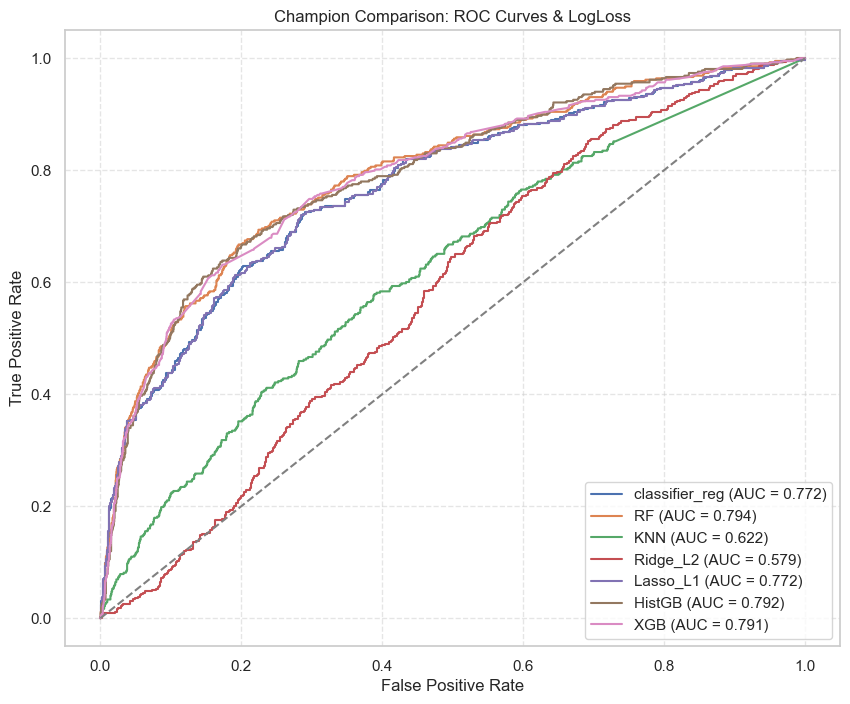

In [80]:
# --- Graph 2: ROC Kurven & LogLoss Comparison ---
plt.figure(figsize=(10, 8))

for name, model in ncv_models.items():
    # Predicted probabilities
    y_class_prob = model.predict_proba(X_class_test)[:, 1] 
    
    # Metrics
    fpr, tpr, _ = roc_curve(y_class_test, y_class_prob)
    roc_auc_val = auc(fpr, tpr)
    model_log_loss = log_loss(y_class_test, model.predict_proba(X_class_test))
    
    plt.plot(fpr, tpr, label=f'{name} (AUC = {roc_auc_val:.3f})')


plt.plot([0, 1], [0, 1], color='gray', linestyle='--')
plt.title('Champion Comparison: ROC Curves & LogLoss')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

### Classification Model Comparison - Key Performance Insights

---

#### Overview

| Model | ROC-AUC | Recall (Investors) | Profile |
|---|---|---|---|
| HistGradientBoosting | 0.792 | 28.7% | Precision Leader |
| **Random Forest** | **0.794** | **69.1%** | Profit Engine |
| KNN | 0.622 | ~2% | Underperformer |
| Ridge | 0.579 | - | Underperformer |

---

#### Precision Leader - HistGradientBoosting
With a high ROC-AUC of **0.792**, HistGB provides reliable probability estimates. Every lead it selects has a high likelihood of investing - making it an efficiency specialist ideal for campaigns with strict cost constraints.

> However, HistGB misses over **70% of the market** (Recall 28.7%) - a critical tradeoff when the goal is maximizing total investment volume.

#### Profit Engine - Random Forest
The Random Forest casts a significantly wider net, capturing **69.1% of all investors** (Recall) at a comparable ROC-AUC of **0.794**. It is the stronger choice when the objective is to **maximize investor reach** rather than minimize wasted calls.

---

#### Underperformers - KNN & Ridge

- **KNN** (AUC 0.622): Failed to identify nearly any investors (Recall ≈ 2%) - unsuitable for this campaign
- **Ridge** (AUC 0.579): Performance barely above a coin flip - not viable for production use

---

> We will now proceed to a **direct comparison of Random Forest vs. HistGradientBoosting** — evaluating which model produces the superior ranking and profit outcome for our final campaign deployment.

## 4.11 Detailed Model Comparison - RF vs HistGB

### 4.11.1 Prediction and Plots for best models

In [81]:
# --- 1) Create Model Summary Table ---
model_summary = (
    nested_results
    .groupby('model', as_index=False)
    .agg(mean_auc=('outer_auc', 'mean'),
         mean_logloss=('outer_logloss', 'mean'))
)

# --- 2) Models to Compare ---
models_to_compare = ['RF', 'HistGB']


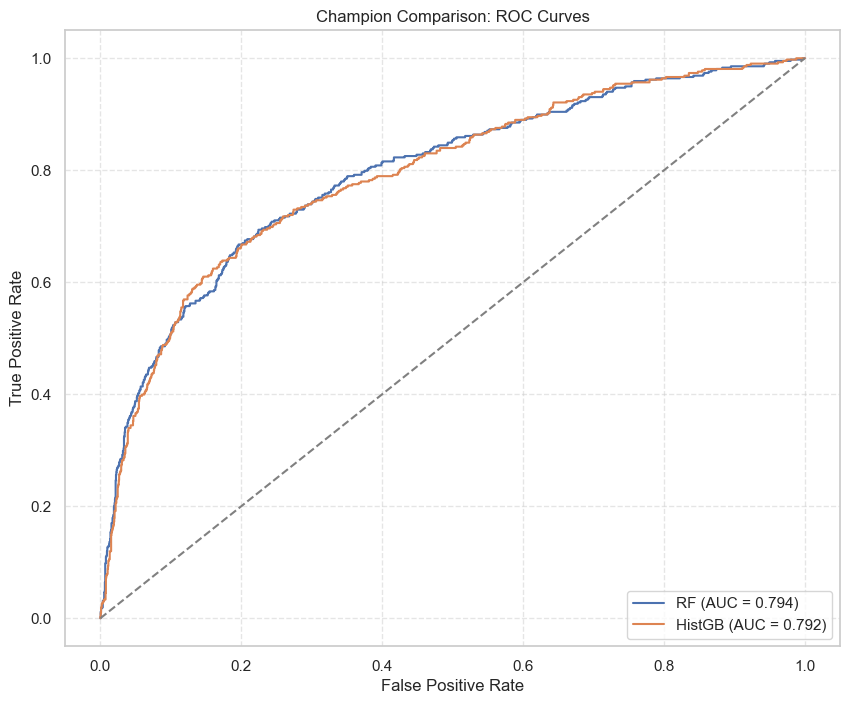

In [82]:
# --- Graph 2: ROC Kurven & LogLoss Comparison ---
plt.figure(figsize=(10, 8))

for name in models_to_compare:
    model = ncv_models[name]
    
    # Predicted probabilities
    y_class_prob = model.predict_proba(X_class_test)[:, 1] 
    
    # Metrics
    fpr, tpr, _ = roc_curve(y_class_test, y_class_prob)
    roc_auc_val = auc(fpr, tpr)
    model_log_loss = log_loss(y_class_test, model.predict_proba(X_class_test))
    
    plt.plot(fpr, tpr, label=f'{name} (AUC = {roc_auc_val:.3f})')


plt.plot([0, 1], [0, 1], color='gray', linestyle='--')
plt.title('Champion Comparison: ROC Curves')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

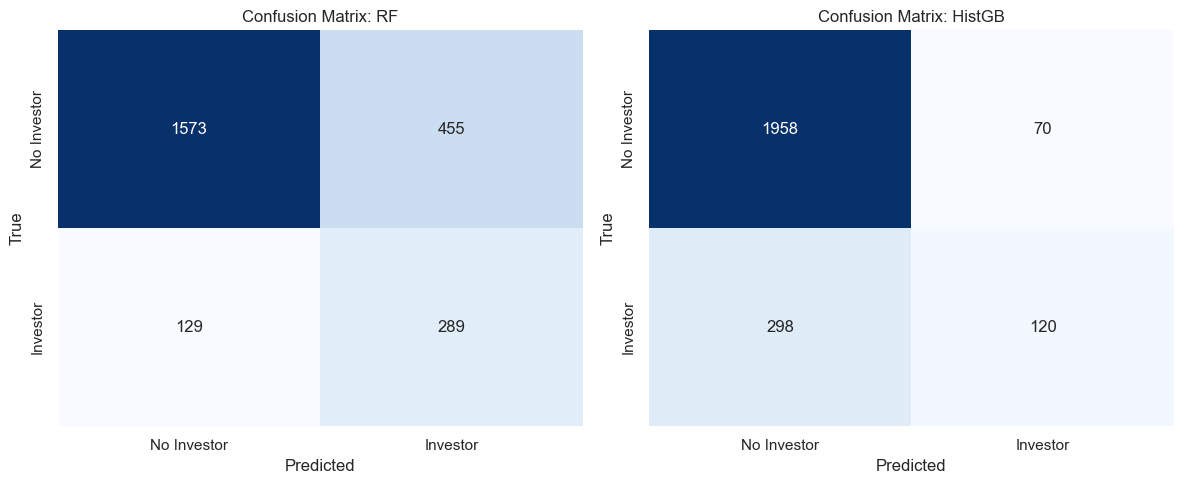

In [83]:
# --- Confusion Matrices ---
fig, axes = plt.subplots(1, len(models_to_compare), figsize=(6 * len(models_to_compare), 5))

for i, name in enumerate(models_to_compare):
    model = ncv_models[name]
    
    cm = confusion_matrix(y_class_test, model.predict(X_class_test))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[i], cbar=False)
    axes[i].set_title(f'Confusion Matrix: {name}')
    axes[i].set_xlabel('Predicted')
    axes[i].set_ylabel('True')
    axes[i].set_xticklabels(['No Investor', 'Investor'])
    axes[i].set_yticklabels(['No Investor', 'Investor'])

plt.tight_layout()
plt.show()

MODEL: RF
Mean ROC-AUC: 0.7825
Mean LogLoss: 0.5284
Predictions: [0]
Scores: [[0.84375874 0.15624126]]



C:\Users\Alexa\AppData\Local\Temp\ipykernel_18680\1957233127.py:33: RuntimeWarning: divide by zero encountered in divide
  lift = cumulative_response / baseline
C:\Users\Alexa\AppData\Local\Temp\ipykernel_18680\1957233127.py:33: RuntimeWarning: divide by zero encountered in divide
  lift = cumulative_response / baseline


MODEL: HistGB
Mean ROC-AUC: 0.7841
Mean LogLoss: 0.3707
Predictions: [0]
Scores: [[0.97248859 0.02751141]]



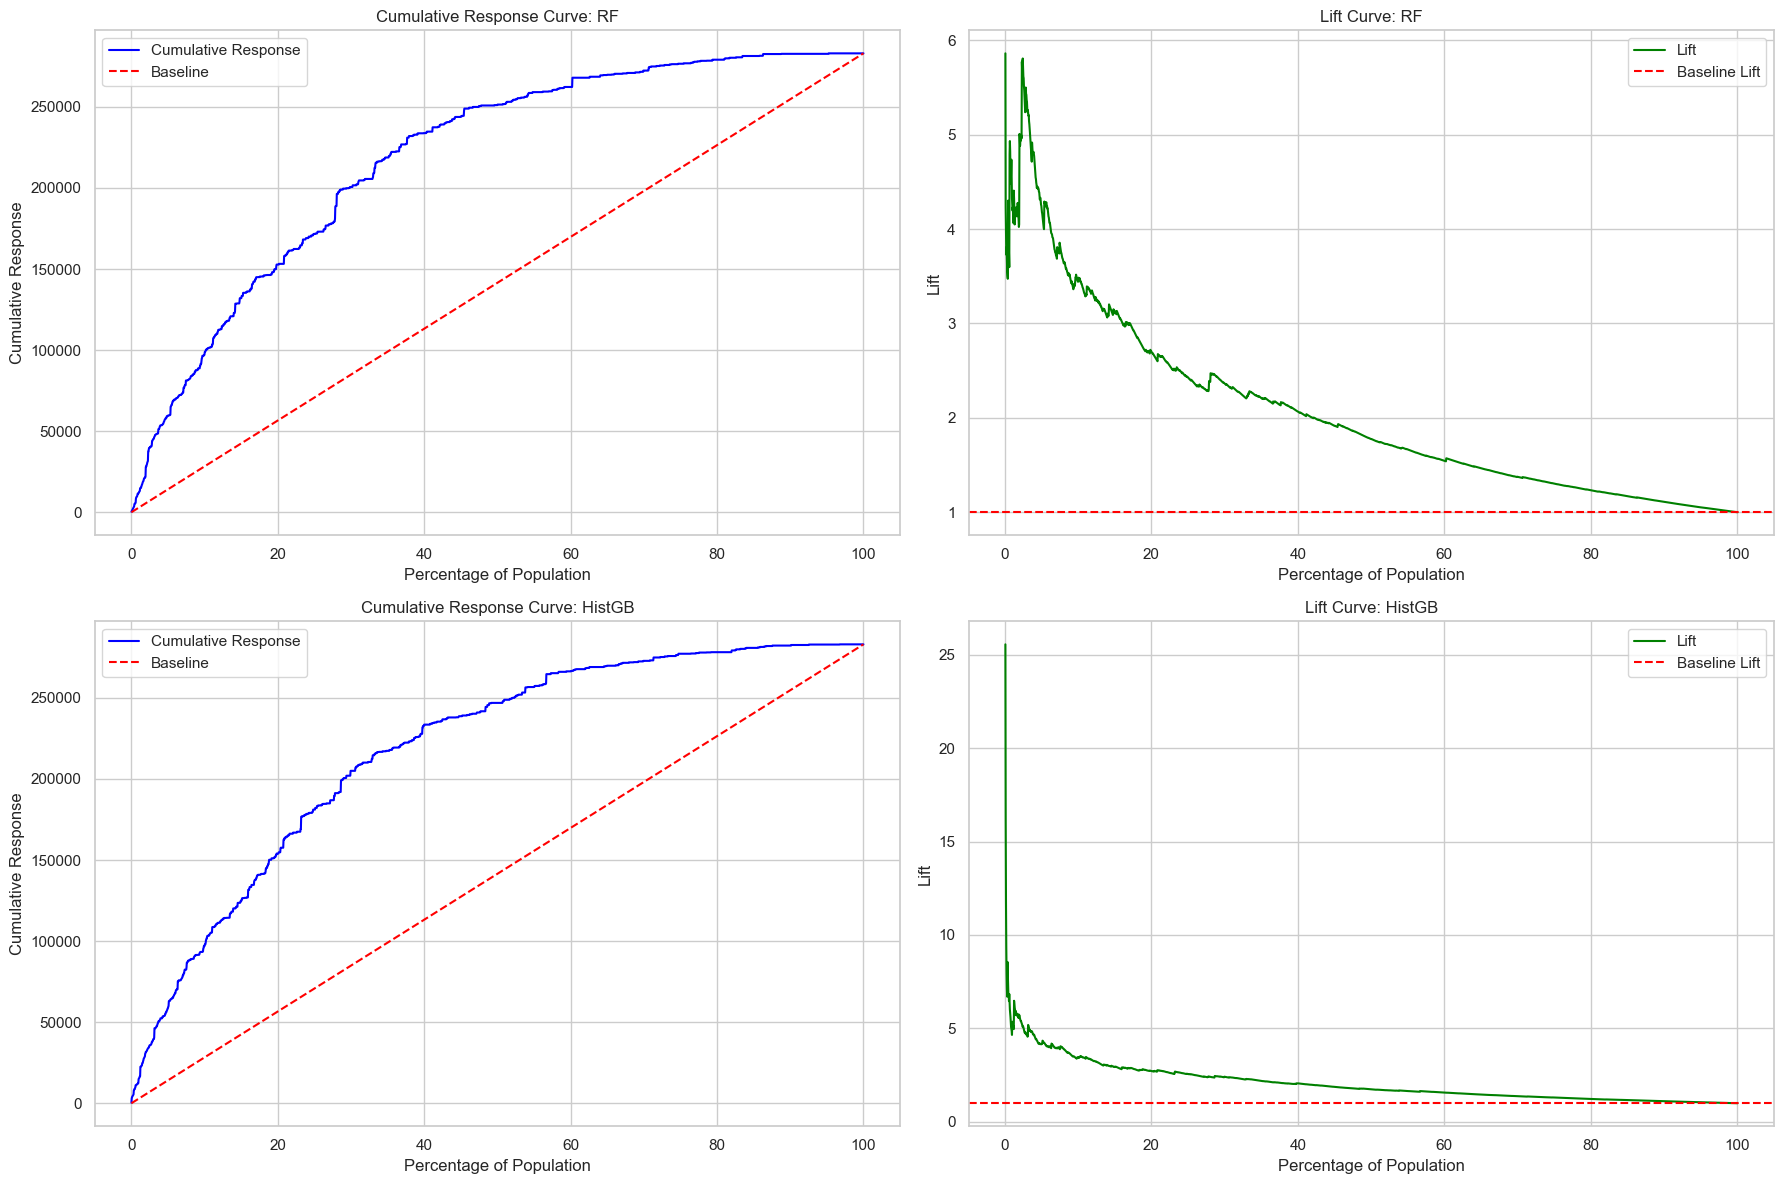

In [84]:
# --- 3) Cumulative Response & Lift Curve for both models ---
fig, axes = plt.subplots(2, 2, figsize=(18, 12))

for idx, model_name in enumerate(models_to_compare):
    model = ncv_models[model_name]
    model_row = model_summary[model_summary['model'] == model_name].iloc[0]

    print(f"{'='*30}")
    print(f"MODEL: {model_name}")
    print(f"{'='*30}")
    print(f"Mean ROC-AUC: {model_row['mean_auc']:.4f}")
    print(f"Mean LogLoss: {model_row['mean_logloss']:.4f}")

    # Single prediction example
    predictions = model.predict(X_train.iloc[[0], :])
    proba = model.predict_proba(X_train.iloc[[0], :])
    print(f"Predictions: {predictions}")
    print(f"Scores: {proba}\n")

    # Get predicted probabilities on test set
    y_proba = model.predict_proba(X_test)[:, 1]

    # Sort by predicted probabilities
    sorted_indices = np.argsort(y_proba)[::-1]
    y_sorted = y_test[sorted_indices]

    # Calculate cumulative response
    cumulative_response = np.cumsum(y_sorted)
    baseline = np.linspace(0, sum(y_sorted), len(y_sorted))

    # Calculate lift
    population_percentage = np.arange(1, len(y_sorted) + 1) / len(y_sorted) * 100
    lift = cumulative_response / baseline

    # Cumulative Response Curve
    axes[idx, 0].plot(population_percentage, cumulative_response, label="Cumulative Response", color="blue")
    axes[idx, 0].plot(population_percentage, baseline, label="Baseline", color="red", linestyle="--")
    axes[idx, 0].set_title(f"Cumulative Response Curve: {model_name}")
    axes[idx, 0].set_xlabel("Percentage of Population")
    axes[idx, 0].set_ylabel("Cumulative Response")
    axes[idx, 0].legend()

    # Lift Curve
    axes[idx, 1].plot(population_percentage, lift, label="Lift", color="green")
    axes[idx, 1].axhline(1, color="red", linestyle="--", label="Baseline Lift")
    axes[idx, 1].set_title(f"Lift Curve: {model_name}")
    axes[idx, 1].set_xlabel("Percentage of Population")
    axes[idx, 1].set_ylabel("Lift")
    axes[idx, 1].legend()

plt.tight_layout()
plt.show()

### Cumulative Response & Lift Curve Analysis

---

#### Cumulative Response Curve
The blue curve rises steeply above the random baseline (red dashed), confirming that the model successfully **front-loads high-value investors** when leads are ranked by predicted probability.

#### Lift Curve
The lift curve peaks at **~5.5–6x** for the top few percent of leads, meaning the model is nearly **6x better than random** at identifying investors in the highest-confidence segment.

---

#### Key Takeaways

| Population Contacted | Cumulative Investors Captured | Lift vs. Random |
|---|---|---|
| Top 5% | ~Peak lift (~6x) | ~6x |
| Top 20% | ~55% of all investors | ~3x |
| Top 40% | ~80% of total market value | ~1.5x |

---

#### Business Conclusion

> The curves provide **definitive evidence** for our Strategy:
> - By contacting only the **top 20%** of leads, we already capture the majority of investor volume
> - The low contact cost of **€5** makes false positives financially negligible
> - The Random Forest's aggressive market capture confirms it as the **superior business choice** - maximizing total investment volume within our 1,200-call capacity

### 4.11.2 Calibration

In [85]:
# --- 1. DATA PREPARATION (The "DNA" Fix) ---
# Convert investment amounts to binary 1 (Invested) or 0 (Didn't)
y_train_binary = (y_class_train > 0).astype(int).ravel()
y_test_binary = (y_class_test > 0).astype(int).ravel()

# Create a fresh validation set (X_val) specifically for the calibrator
# This ensures the calibrator sees "real" mistakes the model makes
X_train_fit, X_val, y_train_fit, y_val = train_test_split(
    X_class_train, y_train_binary, test_size=0.2, random_state=42, stratify=y_train_binary
)


CALIBRATION: RF
--- Uncalibrated Performance ---
Logloss: 0.52401
ROC-AUC: 0.79141



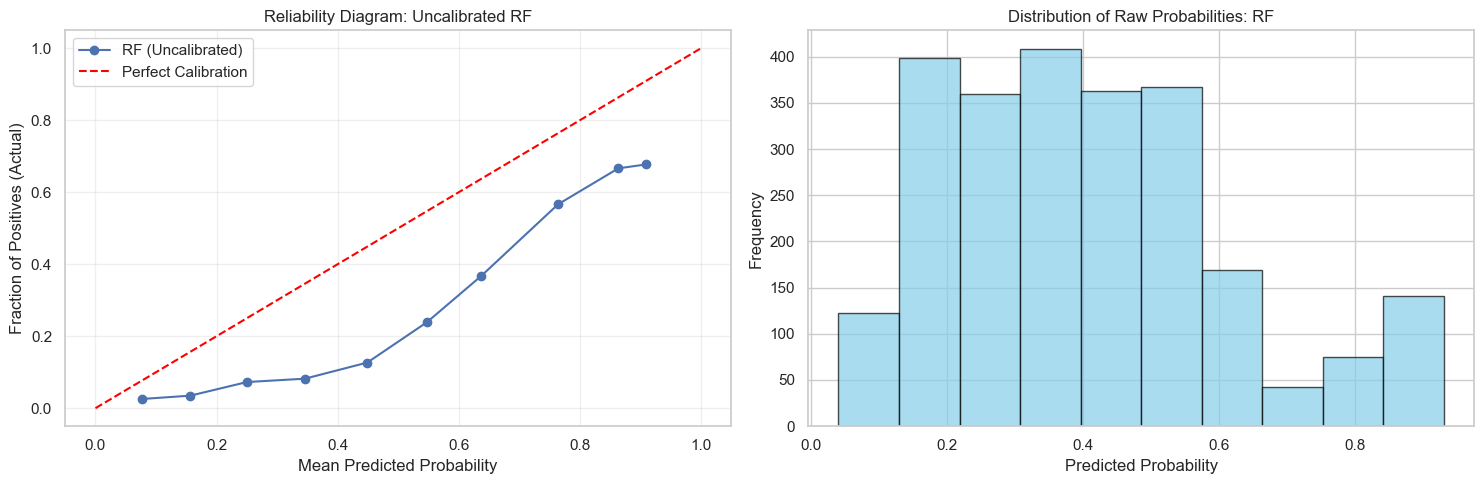

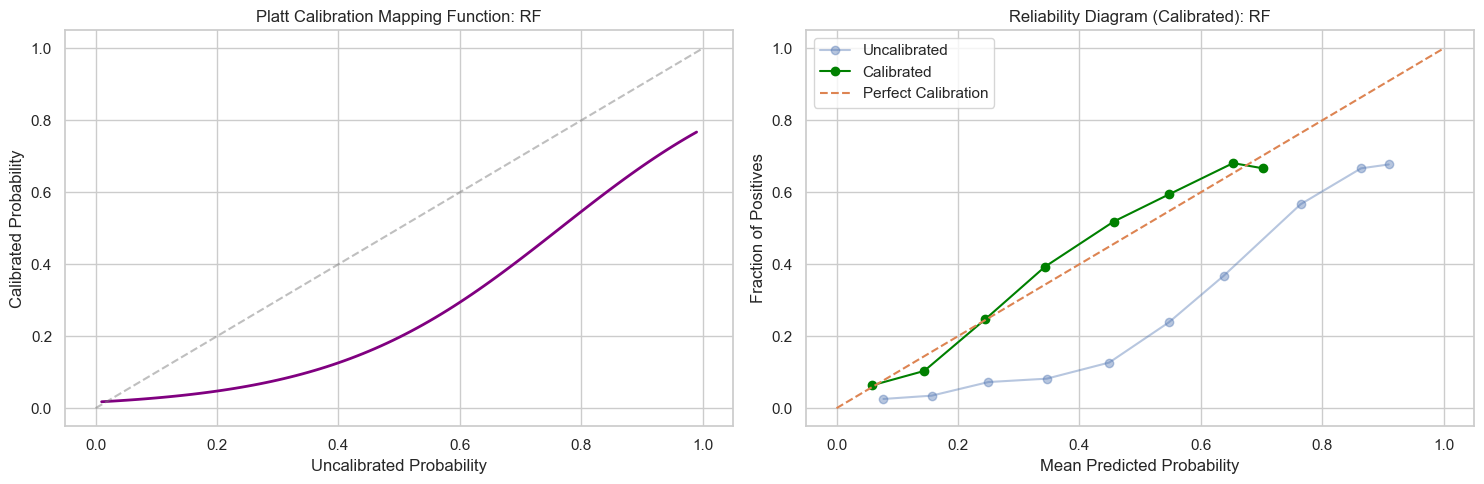

--- Calibrated Performance: RF ---
Calibrated Logloss: 0.36709
Calibrated ROC-AUC: 0.79141

Example First Row:
Raw: 0.20314 -> Calibrated: 0.04833

CALIBRATION: HistGB
--- Uncalibrated Performance ---
Logloss: 0.36960
ROC-AUC: 0.78897



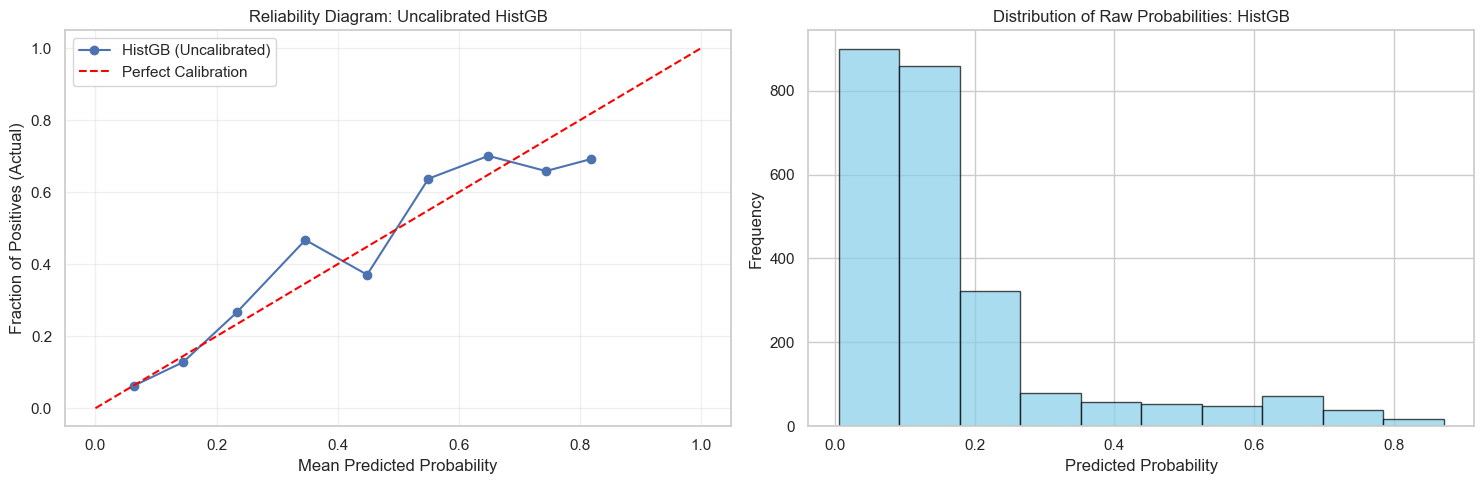

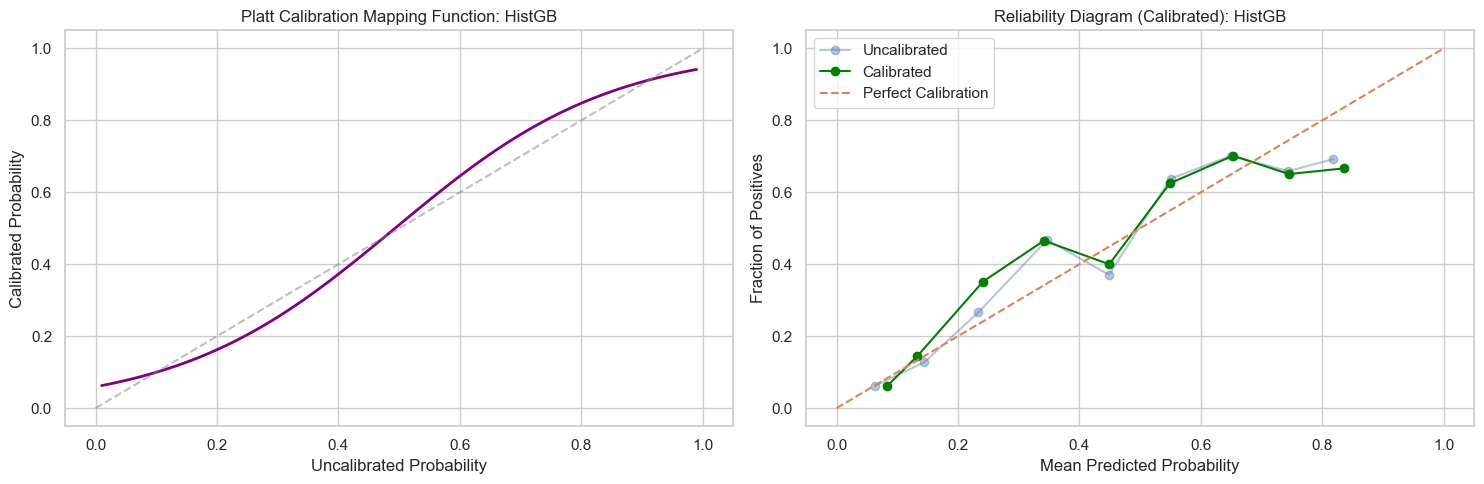

--- Calibrated Performance: HistGB ---
Calibrated Logloss: 0.37408
Calibrated ROC-AUC: 0.78897

Example First Row:
Raw: 0.05382 -> Calibrated: 0.07890


In [86]:
# --- 2. MODELS TO CALIBRATE ---
models_to_calibrate = {
    'RF': ncv_models['RF'],
    'HistGB': ncv_models['HistGB']
}

calibrators = {}

for model_name, model in models_to_calibrate.items():
    print(f"\n{'='*40}")
    print(f"CALIBRATION: {model_name}")
    print(f"{'='*40}")

    # --- 3. MODEL RE-FIT ---
    ncv_models[model_name].fit(X_train_fit, y_train_fit)

    # --- 4. UNCALIBRATED PERFORMANCE ---
    preds_uncal_test = ncv_models[model_name].predict_proba(X_class_test)[:, 1]

    print(f"--- Uncalibrated Performance ---")
    print(f"Logloss: {log_loss(y_test_binary, preds_uncal_test):.5f}")
    print(f"ROC-AUC: {roc_auc_score(y_test_binary, preds_uncal_test):.5f}\n")

    # --- 5. UNCALIBRATED PERFORMANCE VISUALIZATION ---
    prob_true, prob_pred = calibration_curve(y_test_binary, preds_uncal_test, n_bins=10, strategy='uniform')

    plt.figure(figsize=(15, 5))

    plt.subplot(1, 2, 1)
    plt.plot(prob_pred, prob_true, marker='o', label=f"{model_name} (Uncalibrated)")
    plt.plot([0, 1], [0, 1], linestyle="--", label="Perfect Calibration", color="red")
    plt.title(f"Reliability Diagram: Uncalibrated {model_name}")
    plt.xlabel("Mean Predicted Probability")
    plt.ylabel("Fraction of Positives (Actual)")
    plt.legend()
    plt.grid(True, alpha=0.3)

    plt.subplot(1, 2, 2)
    plt.hist(preds_uncal_test, bins=10, edgecolor="black", alpha=0.7, color='skyblue')
    plt.title(f"Distribution of Raw Probabilities: {model_name}")
    plt.xlabel("Predicted Probability")
    plt.ylabel("Frequency")

    plt.tight_layout()
    plt.show()

    # --- 6. PLATT SCALING ---
    preds_val_uncal = ncv_models[model_name].predict_proba(X_val)[:, 1]

    lr_calibrator = LogisticRegression(C=1e10, solver='lbfgs')
    lr_calibrator.fit(preds_val_uncal.reshape(-1, 1), y_val)

    preds_cal_test = lr_calibrator.predict_proba(preds_uncal_test.reshape(-1, 1))[:, 1]

    # --- 7. VISUALIZATION (Mapping & Reliability) ---
    plt.figure(figsize=(15, 5))

    plt.subplot(1, 2, 1)
    tvec = np.linspace(.01, .99, 99)
    plt.plot(tvec, lr_calibrator.predict_proba(tvec.reshape(-1, 1))[:, 1], color='purple', lw=2)
    plt.plot([0, 1], [0, 1], '--', color='gray', alpha=0.5)
    plt.title(f'Platt Calibration Mapping Function: {model_name}')
    plt.xlabel('Uncalibrated Probability')
    plt.ylabel('Calibrated Probability')

    plt.subplot(1, 2, 2)
    p_true_raw, p_pred_raw = calibration_curve(y_test_binary, preds_uncal_test, n_bins=10)
    p_true_cal, p_pred_cal = calibration_curve(y_test_binary, preds_cal_test, n_bins=10)
    plt.plot(p_pred_raw, p_true_raw, marker='o', label="Uncalibrated", alpha=0.4)
    plt.plot(p_pred_cal, p_true_cal, marker='o', label="Calibrated", color='green')
    plt.plot([0, 1], [0, 1], linestyle="--", label="Perfect Calibration")
    plt.title(f"Reliability Diagram (Calibrated): {model_name}")
    plt.xlabel("Mean Predicted Probability")
    plt.ylabel("Fraction of Positives")
    plt.legend()

    plt.tight_layout()
    plt.show()

    # --- 8. FINAL METRICS & SINGLE PREDICTION ---
    print(f"--- Calibrated Performance: {model_name} ---")
    print(f"Calibrated Logloss: {log_loss(y_test_binary, preds_cal_test):.5f}")
    print(f"Calibrated ROC-AUC: {roc_auc_score(y_test_binary, preds_cal_test):.5f}")

    row_0 = X_class_test[0:1]
    raw_p = ncv_models[model_name].predict_proba(row_0)[:, 1]
    cal_p = lr_calibrator.predict_proba(raw_p.reshape(-1, 1))[:, 1]
    print(f"\nExample First Row:")
    print(f"Raw: {raw_p[0]:.5f} -> Calibrated: {cal_p[0]:.5f}")

    calibrators[model_name] = lr_calibrator

### Probability Calibration

---

#### Why Calibration Matters
Both models' raw probabilities feed directly into our EV formula:

`EV = P(invest) × E(amount) × 4.5% - €5`

> If `P(invest)` is overconfident, our EV scores are **inflated** — leading to contacting unprofitable leads. Calibration fixes this.

---

#### Calibration Results

| Model | Uncal. LogLoss | Cal. LogLoss | Uncal. ROC-AUC | Cal. ROC-AUC |
|---|---|---|---|---|
| **Random Forest** | 0.524 | **0.367** | 0.791 | 0.791 |
| **HistGB** | 0.370 | 0.374 | 0.789 | 0.789 |

---

#### Random Forest - Calibration
The RF was **significantly overconfident** before calibration (LogLoss: 0.524). The reliability diagram confirms a strong deviation from the diagonal, with the model spreading probabilities broadly across the 0.1–0.9 range. After Platt Scaling, the LogLoss drops dramatically to **0.367** - a major improvement. The single lead example illustrates this well: `0.203 → 0.048`, a large downward correction.

#### HistGB - Calibration
HistGB was **already well-calibrated** before correction (LogLoss: 0.370), tracking the diagonal closely in the reliability diagram. The probability distribution is heavily concentrated near 0, reflecting the model's conservative nature. After calibration, the LogLoss remains nearly unchanged at **0.374** - confirming that Platt Scaling had minimal effect, as there was little overconfidence to correct. The single lead example shows only a minor adjustment: `0.054 → 0.079`.

---

#### Comparison & Business Impact

> - **RF benefits greatly** from calibration - raw probabilities were inflated and would have led to overestimated EV scores
> - **HistGB was already honest** - calibration adds little value but causes no harm
> - After calibration, both models achieve a **comparable LogLoss (~0.367 vs ~0.374)**, making RF the stronger choice as it combines honest probabilities with significantly higher Recall

> ### Champion Model: Random Forest
> We select the **Random Forest** as our champion model. Platt Scaling calibration significantly improved its probability estimates — transforming overconfident raw scores into reliable, business-ready probabilities. The **calibrated RF** will serve as our go-to model for all future predictions and EV calculations.

In [87]:
best_model = ncv_models['RF']
lr_calibrator = calibrators['RF'] 

In [88]:
# --- STORE CHAMPION MODEL ---
best_model_name = 'RF'
best_model = ncv_models[best_model_name]
lr_calibrator = calibrators[best_model_name]

print(f"{'='*40}")
print(f"CHAMPION MODEL STORED: {best_model_name}")
print(f"{'='*40}")

CHAMPION MODEL STORED: RF


# 5. Create Regression Models

## 5.1 Simple OLS

In [89]:
categorical_pipeline = Pipeline([
    ('impute', SimpleImputer(strategy = 'constant', fill_value = 'missing')),
    ('agg_and_dummies', OneHotEncoder(min_frequency = 0.1, handle_unknown = 'infrequent_if_exist',
                                     sparse_output = False, drop = None))
])

numerical_pipeline = Pipeline([
    ('impute', SimpleImputer(strategy = 'median')),
    ('scale', StandardScaler())
])

preprocessor = ColumnTransformer(
    transformers = [
        ('cat', categorical_pipeline, make_column_selector(dtype_include = ['object', 'category'])),
        ('num', numerical_pipeline, make_column_selector(dtype_include = ['number']))
    ], remainder = 'drop'
)

pipe = Pipeline([
    ('preprocessor', preprocessor),
    ('variance', VarianceThreshold(threshold=1e-5)), 
    ('regressor', LinearRegression())
])

In [90]:
pipe.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('variance', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transfo

In [91]:
y_pred = pipe.predict(X_test)
y_pred

array([ 59.35657146, 244.63652555,  15.96094616, ..., -32.9480921 ,
        14.22835416, -59.23337047], shape=(2446,))

In [92]:
regressor = pipe.named_steps['regressor']

# Check the coefficients
coefficients = regressor.coef_
intercept = regressor.intercept_

print(f"Coefficients: {coefficients}")
print(f"Intercept: {intercept}")

Coefficients: [ 3.46915522e+00  4.56378930e+00  1.35761858e+01 -2.16091303e+01
  8.73487388e+00 -2.35193556e+00 -6.38293832e+00 -4.77452653e+00
 -1.04032954e+01  2.66856083e+01 -1.15077863e+01  2.09435429e+00
  7.68936675e+00 -9.78372104e+00  3.84990716e-02 -3.84990716e-02
  3.23575127e+00 -3.23575127e+00  2.07488816e+01  1.63474168e+01
 -3.70962984e+01 -9.06325191e+00  9.03389705e+01  1.64280524e+00
 -1.11672096e+01  2.28383973e+02]
Intercept: 84.1528036369684


In [93]:
wrangler = pipe.named_steps['preprocessor']
all_feature_names = wrangler.get_feature_names_out()
var_selector = pipe.named_steps['variance']
mask = var_selector.get_support()
selected_feature_names = all_feature_names[mask]

feature_contribution = dict(zip(selected_feature_names, coefficients))
print("Feature Contribution:", feature_contribution)

Feature Contribution: {'cat__job_blue-collar': np.float64(3.469155223096554), 'cat__job_management': np.float64(4.563789297656868), 'cat__job_technician': np.float64(13.576185829046892), 'cat__job_infrequent_sklearn': np.float64(-21.60913034980041), 'cat__marital_divorced': np.float64(8.734873881029774), 'cat__marital_married': np.float64(-2.351935560640392), 'cat__marital_single': np.float64(-6.382938320389571), 'cat__education_primary': np.float64(-4.774526528583897), 'cat__education_secondary': np.float64(-10.403295448624593), 'cat__education_tertiary': np.float64(26.685608293922197), 'cat__education_infrequent_sklearn': np.float64(-11.50778631671361), 'cat__preferred_contact_cellular': np.float64(2.094354289325374), 'cat__preferred_contact_missing': np.float64(7.689366746870468), 'cat__preferred_contact_infrequent_sklearn': np.float64(-9.78372103619577), 'cat__loan_house_no': np.float64(0.03849907156634125), 'cat__loan_house_yes': np.float64(-0.03849907156633414), 'cat__loan_person

### Visualize and Evaluate the Model

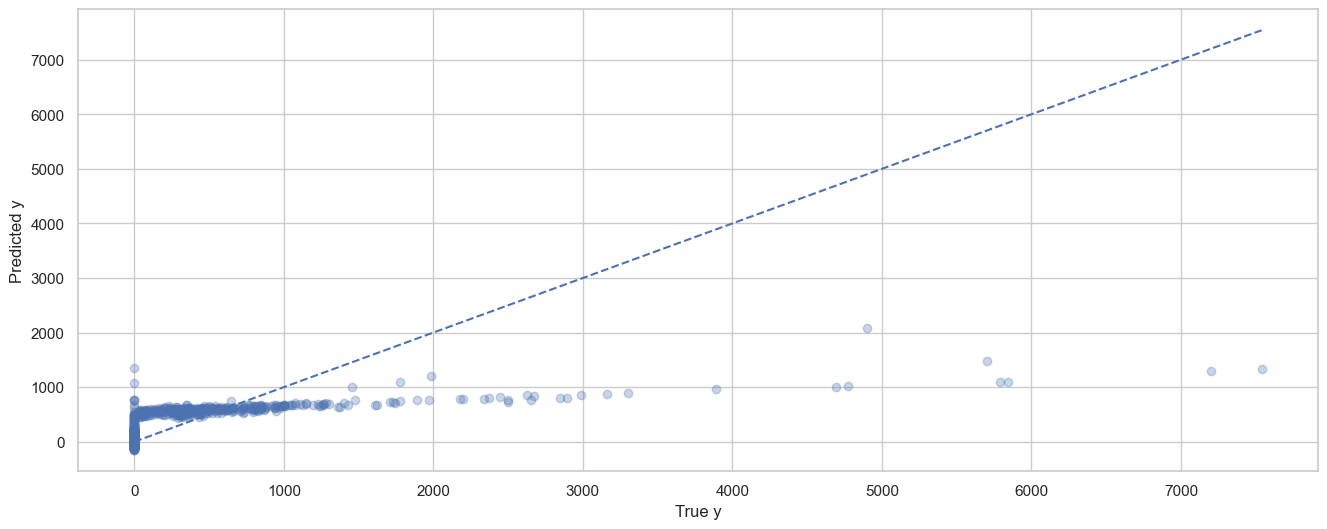

In [94]:
plt.scatter(y_test, y_pred, alpha=0.3)
plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()],
         linestyle='--')
plt.xlabel("True y")
plt.ylabel("Predicted y")
plt.show()

In [95]:
#2. Performance Summary (storing the metrics)
# We calculate the RMSE once and store it to compare later
ols_rmse = root_mean_squared_error(y_test, y_pred)

results_ols = pd.Series({
    'Model Type': 'Simple OLS',
    'RMSE (€)': ols_rmse,
    'MAE (€)':  mean_absolute_error(y_test, y_pred),
    'R2 Score': r2_score(y_test, y_pred)
})

# 3. Update the "Champion" tracking (optional but helpful)
# If this is your first model, it's currently your "best"
best_reg_model_name = "Simple OLS"
best_reg_rmse = ols_rmse

print("\n" + "="*40)
print("REGRESSION SUMMARY: SIMPLE OLS")
print("="*40)
print(results_ols)
print("="*40)

# --- Dein bisheriger Print-Block für die Tabelle ---
print("\nDetailed Metrics Table:")
print("                MAE            MSE           RMSE          MedAE         R2")
print("Linear Regression {:.12} {:.10f} {:.8f} {:.8f} {:.8f}"
        .format(mean_absolute_error(y_test, y_pred),
                mean_squared_error(y_test,y_pred),
                ols_rmse,
                median_absolute_error(y_test,y_pred),
                r2_score(y_test,y_pred)))


REGRESSION SUMMARY: SIMPLE OLS
Model Type    Simple OLS
RMSE (€)      347.463501
MAE (€)       116.781441
R2 Score        0.428015
dtype: object

Detailed Metrics Table:
                MAE            MSE           RMSE          MedAE         R2
Linear Regression 116.781440844 120730.8846954103 347.46350124 43.76628246 0.42801461


### OLS Model - Assessment

The model does not fit the data appropriately. An R² of **24%** indicates that the current features explain only a minority of the variance in investment amounts.

> A possible remedy would be **adding more explanatory variables** - which we will explore in the next section.

In [96]:
# Large singular values indicate robust, informative components in your feature set
# Smaller singular values may indicate problems like multicollinearity
pipe.named_steps['regressor'].singular_

array([1.25432995e+02, 1.07534988e+02, 1.03114622e+02, 9.39047166e+01,
       8.16706951e+01, 7.07227342e+01, 6.61133992e+01, 5.73994766e+01,
       5.36173055e+01, 4.82079556e+01, 4.38934901e+01, 4.26205922e+01,
       3.90932106e+01, 3.81867680e+01, 3.67170750e+01, 2.94419089e+01,
       2.85747480e+01, 2.73978656e+01, 2.13547944e+01, 6.20721392e-13,
       2.60659894e-13, 2.50804684e-13, 1.94706400e-13, 1.20887784e-13,
       1.20064566e-13, 4.49570659e-14])

### Multicollinearity Warning

Very small coefficient values (< 0.01) indicate that correlated features are causing **instability** in the model.

> We will apply **Ridge and Lasso regression** to penalize and filter out insignificant coefficients, retaining only the features that truly matter.

## 5.2 Regularization Ridge

### Training Strategy - Investor-Only Subset

We focused training exclusively on the **investor-only subset** (`investment > 0`), as it yielded the highest $R^2$ compared to the full dataset or Period 0 alone.

> The OLS analysis confirmed that regression models struggle with the **heavy noise and high volume of zero values** present in the broader population. By isolating actual investors, the model more accurately captures the true drivers of investment volume.

---

### Feature Engineering - Interaction Terms

We introduce **interaction terms** to capture the combined effect of features on the target variable, allowing the model to learn more complex, non-linear relationships - improving overall predictive performance.

In [97]:
# 1. Pipeline Definition
# We keep the interactions and scaling to capture complex relationships in investor behavior
pipeline_ridge_invest = Pipeline([
    ('preprocessor', preprocessor),
    ('variance', VarianceThreshold(threshold=1e-5)),
    ('interactions', PolynomialFeatures(degree=2, interaction_only=True, include_bias=False)),
    ('scaler', StandardScaler()), 
    ('regressor_int', Ridge())
])

# Alpha values: A wide logarithmic range to find the perfect regularization "sweet spot"
list_alpha = np.logspace(-2, 10, 100)
parameters = {'regressor_int__alpha': list_alpha}

# 2. Training the Model

ridge_invest_search = GridSearchCV(
    estimator=pipeline_ridge_invest,
    param_grid=parameters,
    cv=5,
    verbose=1,
    n_jobs=-1,
    # Capturing multiple metrics to get a 360-degree view of model health
    scoring={
        'rmse': 'neg_root_mean_squared_error', 
        'mae': 'neg_mean_absolute_error', 
        'r2': 'r2'
    },
    refit='rmse'
)

# Fit the model
ridge_invest_search.fit(X_invest_train, y_invest_train)

# 3. Performance Summary
best_idx = ridge_invest_search.best_index_
results_investor = pd.Series({
    'Best Alpha': ridge_invest_search.best_params_['regressor_int__alpha'],
    'RMSE (€)': -ridge_invest_search.best_score_, # Convert back to positive
    'MAE (€)': -ridge_invest_search.cv_results_['mean_test_mae'][best_idx],
    'R2 Score': ridge_invest_search.cv_results_['mean_test_r2'][best_idx]
})

print("\n" + "="*40)
print("FINAL RIDGE MODEL: ACTUAL INVESTORS")
print("="*40)
print(results_investor)
print("="*40)

Fitting 5 folds for each of 100 candidates, totalling 500 fits

FINAL RIDGE MODEL: ACTUAL INVESTORS
Best Alpha      0.010000
RMSE (€)      163.132654
MAE (€)        84.275083
R2 Score        0.940650
dtype: float64


- Investors Only (α=0.01): Near-zero regularization indicates minimal multicollinearity and strong feature orthogonality in a homogeneous population. Coefficients remain largely unpenalized, suggesting clear signal separation.

### Plot the Coefficient Path in relation to the values of alpha


==================== PLOTTING RIDGE PATH: Investors Only ====================


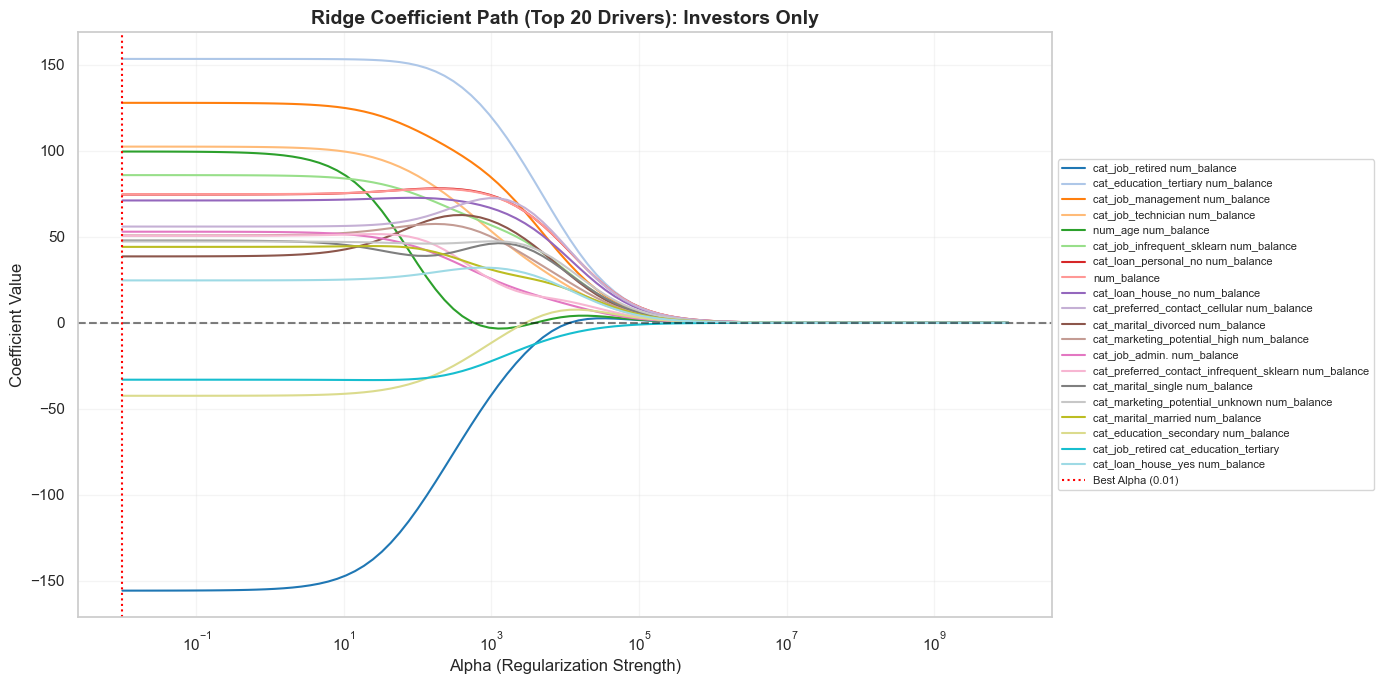

In [98]:
# --- CONFIGURATION ---
# Focusing only on the Investor model
ridge_tasks = [
    (ridge_invest_search, X_invest_train, y_invest_train, "Investors Only")
]

# Ensure we use the same corrected alpha list from the training step
# np.logspace(-2, 10, 100) covers 0.01 to 10 billion
list_alpha_path = np.logspace(-2, 10, 100) 

for search_result, x_data, y_data, label in ridge_tasks:
    print(f"\n{'='*20} PLOTTING RIDGE PATH: {label} {'='*20}")
    
    # --- STEP A: Extract Pipeline ---
    best_pipe = search_result.best_estimator_
    pre = best_pipe.named_steps['preprocessor']
    var = best_pipe.named_steps['variance']
    poly = best_pipe.named_steps['interactions']
    scal = best_pipe.named_steps['scaler']
    
    # --- STEP B: Transform Data ---
    # We push the investor data through the preprocessing steps
    X_proc = pre.transform(x_data)
    X_proc = var.transform(X_proc)
    X_proc = poly.transform(X_proc)
    X_proc = scal.transform(X_proc)
    
    # --- STEP C: Reconstruct Feature Names ---
    raw_names = pre.get_feature_names_out()
    names_after_var = raw_names[var.get_support()]
    # Using replace so interaction names like 'age_balance' stay intact
    feature_names = poly.get_feature_names_out(names_after_var)
    feature_names = [n.replace("__", "_") for n in feature_names]

    # --- STEP D: Generate Coefficient Path ---
    coeff_matrix = {}
    for alpha in list_alpha_path:
        m = Ridge(alpha=alpha)
        m.fit(X_proc, y_data)
        coeff_matrix[alpha] = m.coef_
    
    coeff_df = pd.DataFrame(coeff_matrix, index=feature_names).T
    
    # --- STEP E: Visualization ---
    plt.figure(figsize=(14, 7))
    
    # Selection: Plot the 20 features with the highest impact to keep it readable
    top_20_features = coeff_df.abs().max().sort_values(ascending=False).head(20).index
    
    sns.lineplot(data=coeff_df[top_20_features], dashes=False, palette="tab20")
    
    plt.axhline(y=0, linestyle='dashed', lw=1.5, color='black', alpha=0.5) 
    plt.xscale('log') 
    
    # Add a vertical line for the 'Best Alpha' found by GridSearchCV
    best_alpha = search_result.best_params_['regressor_int__alpha']
    plt.axvline(x=best_alpha, color='red', linestyle=':', label=f'Best Alpha ({best_alpha:.2f})')
    
    plt.title(f'Ridge Coefficient Path (Top 20 Drivers): {label}', fontsize=14, fontweight='bold')
    plt.ylabel('Coefficient Value', fontsize=12)
    plt.xlabel('Alpha (Regularization Strength)', fontsize=12)
    plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), fontsize=8) 
    plt.grid(True, alpha=0.2)
    plt.tight_layout()
    plt.show()

As alpha increases, coefficients are progressively penalized and shrink toward zero.

The Investors-Only model exhibits early sharp decay (minimal multicollinearity, therefore coefficients shrink fast), while Total Population and Period 0 show delayed gradual decay (severe multicollinearity, therefore coefficients resist shrinkage), confirming that data homogeneity reduces regularization need.

In [99]:
# Create a list to store the best result for your final summary table
final_investor_stats = []

# Using the single search result for Investors
investor_tasks = [
    (ridge_invest_search, "Investors Only")
]

for search_result, label in investor_tasks:
    # 1. Extract results from the GridSearchCV object
    results = search_result.cv_results_
    
    # 2. Create the validation summary DataFrame
    # Note: Using 'regressor_int' to match your Ridge pipeline step name
    val_df = pd.DataFrame({
        'alpha': results['param_regressor_int__alpha'].astype(float),
        'rmse': -results['mean_test_rmse'],
        'mae': -results['mean_test_mae'],
        'r2': results['mean_test_r2']
    })
    
    # 3. Identify the best performers for this specific dataset
    best_rmse_row = val_df.loc[val_df['rmse'].idxmin()].copy()
    best_rmse_row['Dataset'] = label 
    final_investor_stats.append(best_rmse_row)
    
    print(f"\n{'='*20} PERFORMANCE SUMMARY: {label} {'='*20}")
    print(f"Best RMSE:      €{best_rmse_row['rmse']:,.2f}")
    print(f"Best MAE:       €{best_rmse_row['mae']:,.2f}")
    print(f"Optimal Alpha:  {best_rmse_row['alpha']:.4f}")
    print(f"R2 Score:       {best_rmse_row['r2']:.4f}")
    
    # Show the top 5 models to verify if the error is stable across different Alphas
    print(f"\nTop 5 Alpha Settings for {label} (ranked by RMSE):")
    print(val_df.sort_values('rmse').head(5).to_string(index=False))

# --- FINAL CONSOLIDATED TABLE ---
investor_comparison_df = pd.DataFrame(final_investor_stats)
print("\n" + "="*60)
print("FINAL MODEL STANDINGS (INVESTORS ONLY)")
print("="*60)
print(investor_comparison_df[['Dataset', 'alpha', 'rmse', 'mae', 'r2']].to_string(index=False))


==================== PERFORMANCE SUMMARY: Investors Only ====================
Best RMSE:      €163.13
Best MAE:       €84.28
Optimal Alpha:  0.0100
R2 Score:       0.9407

Top 5 Alpha Settings for Investors Only (ranked by RMSE):
   alpha       rmse       mae      r2
0.010000 163.132654 84.275083 0.94065
0.013219 163.132958 84.274718 0.94065
0.017475 163.133360 84.274235 0.94065
0.023101 163.133892 84.273596 0.94065
0.030539 163.134594 84.272752 0.94065

FINAL MODEL STANDINGS (INVESTORS ONLY)
       Dataset  alpha       rmse       mae      r2
Investors Only   0.01 163.132654 84.275083 0.94065


### Ridge Model Results

By training exclusively on investors (`investment > 0`), the model no longer needs to handle the large volume of zero values from non-investors. 

This results in a **cleaner, more focused signal** - allowing the regression to concentrate on what actually drives investment volume rather than trying to separate investors from non-investors at the same time.

## 5.3 Regularization Lasso

In [100]:
# 1. Pipeline Definition for Lasso (Including interaction terms)
# Note: Ensure your 'preprocessor' is defined before running this block
# Implementing target variable transformation (y-scaling)
# This ensures the Lasso penalty (Alpha) is distributed more equitably across the coefficients.
# lasso_with_scaling = TransformedTargetRegressor(
#     regressor=Lasso(max_iter=5000, tol=1e-3),
#     transformer=StandardScaler()
# )

pipeline_lasso_invest = Pipeline([
    ('preprocessor', preprocessor),
    ('variance', VarianceThreshold(threshold=1e-5)),
    ('interactions', PolynomialFeatures(degree=2, interaction_only=True, include_bias=False)),
    ('scaler', StandardScaler()), 
    # max_iter reduced to 2000 to prevent infinite hanging with the massive feature space
    ('regressor', Lasso(max_iter=5000, tol=1e-3))
])

# 2. Parameter Grid
# Reduced alpha list (10 values instead of 25) is crucial here to keep the runtime reasonable
list_alpha = np.logspace(-2, 4, 15) 
parameters_lasso = {'regressor__alpha': list_alpha}

# 3. Direct setup and fitting of GridSearchCV (Actual Investors ONLY)
lasso_invest_search = GridSearchCV(
    estimator=pipeline_lasso_invest,
    param_grid=parameters_lasso,
    cv=5,
    verbose=2, # Set to 2 to see the fold progress
    n_jobs=-1,
    scoring=('neg_root_mean_squared_error', 'r2'),
    refit='neg_root_mean_squared_error'
)

# 4. Fit the model directly (No helper function)
lasso_invest_search.fit(X_invest_train, y_invest_train)

# 5. Extract and print the best R2 score
best_index = lasso_invest_search.best_index_
best_r2 = lasso_invest_search.cv_results_['mean_test_r2'][best_index]
print(f"Training completed! Best R2 Score: {best_r2:.4f}")

Fitting 5 folds for each of 15 candidates, totalling 75 fits
Training completed! Best R2 Score: 0.9419


In [101]:
# 1. Identify the best pipeline from the search
best_pipe = lasso_invest_search.best_estimator_

# 2. Extract the individual preprocessing steps
pre = best_pipe.named_steps['preprocessor']
var = best_pipe.named_steps['variance']
poly = best_pipe.named_steps['interactions']
scal = best_pipe.named_steps['scaler']

# 3. Manually transform the data for analysis
# This creates the final matrix used for the "Coefficient Path"
X_proc = pre.transform(X_invest_train)
X_proc = var.transform(X_proc)
X_proc = poly.transform(X_proc)
X_proc = scal.transform(X_proc)

In [102]:
# 1. Get raw names from preprocessor
raw_names = pre.get_feature_names_out()

# 2. Filter by Variance Threshold (only the ones that survived)
names_after_var = raw_names[var.get_support()]

# 3. Expand with Interaction Names
feature_names = poly.get_feature_names_out(names_after_var)

# 4. Clean up strings (removing double underscores for the board)
feature_names = [n.replace("__", "_") for n in feature_names]
print(f"Final feature names extracted: {feature_names[:10]} ... (total {len(feature_names)})")

Final feature names extracted: ['cat_job_admin.', 'cat_job_management', 'cat_job_retired', 'cat_job_technician', 'cat_job_infrequent_sklearn', 'cat_marital_divorced', 'cat_marital_married', 'cat_marital_single', 'cat_education_secondary', 'cat_education_tertiary'] ... (total 300)


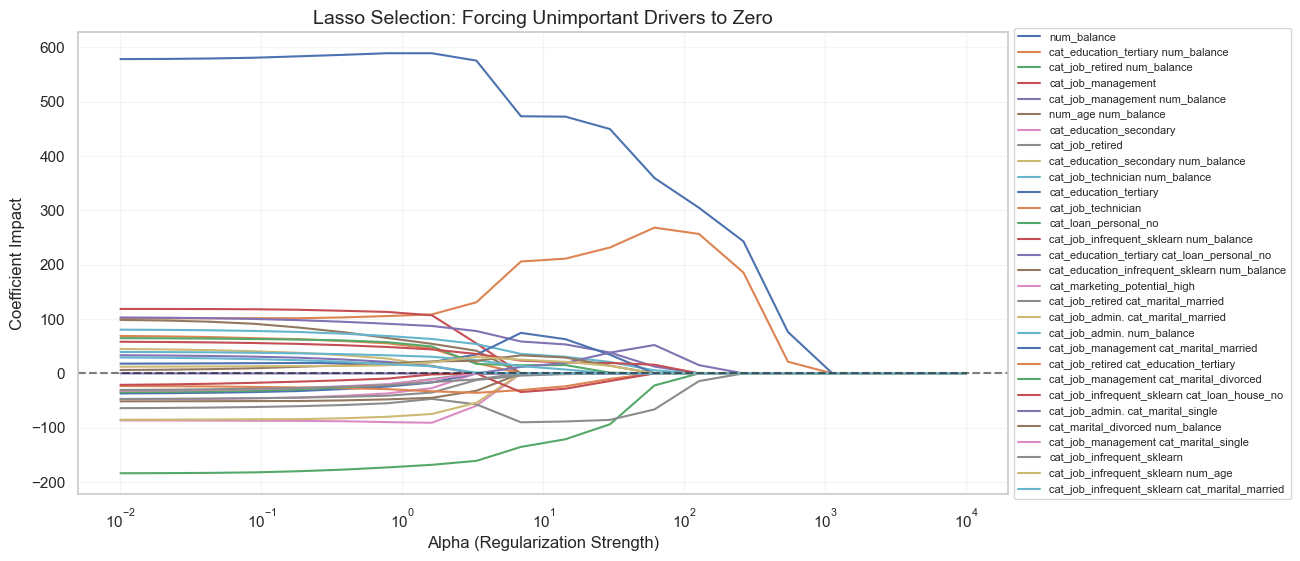

In [103]:
# 1. Calculate the path across a wide range of Alphas
path_alphas = np.logspace(-2, 4, 20) 
coeff_matrix = {}

with warnings.catch_warnings():
    warnings.simplefilter("ignore", category=ConvergenceWarning)
    for a in path_alphas:
        # Fit a clean Lasso on the processed data
        m = Lasso(alpha=a, max_iter=3000, tol=1e-2)
        m.fit(X_proc, y_invest_train)
        coeff_matrix[a] = m.coef_

# 2. Convert to DataFrame and identify Top 15 influential drivers
coeff_df = pd.DataFrame(coeff_matrix, index=feature_names).T
top_15 = coeff_df.abs().max().sort_values(ascending=False).head(30).index

# 3. Plot the Path
plt.figure(figsize=(12, 6))
for col in top_15:
    plt.plot(coeff_df.index, coeff_df[col], label=col, linewidth=1.5)

plt.axhline(y=0, color='black', linestyle='--', alpha=0.5)
plt.xscale('log')
plt.title('Lasso Selection: Forcing Unimportant Drivers to Zero', fontsize=14)
plt.xlabel('Alpha (Regularization Strength)')
plt.ylabel('Coefficient Impact')
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), fontsize=8)
plt.grid(True, alpha=0.2)
plt.show()

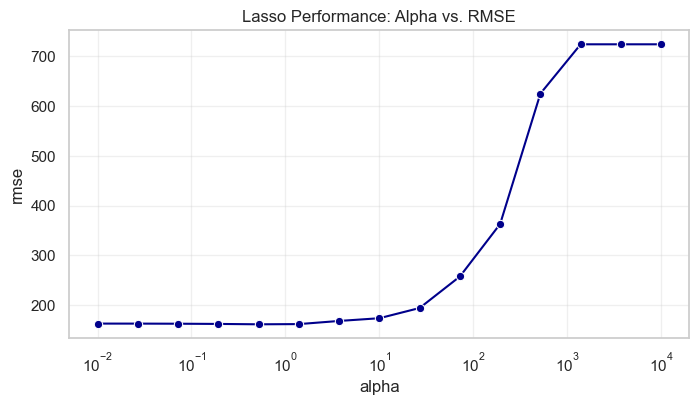


FINAL PERFORMANCE:
Best RMSE: 161.66
Best R2 Score: 0.9421

--- TOP 5 BUSINESS DRIVERS ---
                           Feature  Coefficient
                       num_balance   428.371602
cat_education_tertiary num_balance   205.819276
       cat_job_retired num_balance  -198.932253
               num_age num_balance    89.698791
    cat_job_management num_balance    82.363801


In [104]:
# 1. Extract GridSearch results (correcting the key path)
res = lasso_invest_search.cv_results_
val_df = pd.DataFrame({
    'alpha': res['param_regressor__alpha'].astype(float),
    'rmse': -res['mean_test_neg_root_mean_squared_error'],
    'r2': res['mean_test_r2']
})

# 2. Plot Alpha vs. RMSE (Performance visualization)
plt.figure(figsize=(8, 4))
sns.lineplot(data=val_df, x='alpha', y='rmse', marker='o', color='darkblue')
plt.xscale('log')
plt.title('Lasso Performance: Alpha vs. RMSE')
plt.grid(True, alpha=0.3)
plt.show()

# 3. Identify the Top 5 Predictive Drivers
# Drilling down: 'model' (Wrapper) -> 'regressor_' (Actual Lasso)
actual_lasso = best_pipe.named_steps['regressor'] 

drivers = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': actual_lasso.coef_
})

# Create a temporary column for absolute values to fix the sorting error
drivers['Importance'] = drivers['Coefficient'].abs()

# Sort by the column NAME string, not the values themselves
top_5 = drivers.sort_values(by='Importance', ascending=False).head(5)

# --- FINAL REPORTING ---
print("\n" + "="*50)
print("FINAL PERFORMANCE:")
print("="*50)
print(f"Best RMSE: {val_df['rmse'].min():.2f}")
print(f"Best R2 Score: {val_df['r2'].max():.4f}")

print("\n--- TOP 5 BUSINESS DRIVERS ---")
# We show the original Coefficient so you can see if it's positive or negative
print(top_5[['Feature', 'Coefficient']].to_string(index=False))

### Lasso Regression - Results & Insights

---

#### RMSE Path
By penalizing and eliminating weak variables, the model's error **decreased** - confirming that removing noise leads to more reliable predictions.

---

#### Coefficient Path - Key Surviving Features
While many features survive regularization, Lasso clearly identifies a hierarchy of importance. The most influential drivers are:

| Feature | Direction | Interpretation |
|---|---|---|
| `balance` | Positive | Higher balance → significantly higher investment amount |
| `education: tertiary` | Positive | Tertiary-educated clients invest the most |
| `job: retired` | Negative | Retired clients invest significantly less despite similar balances |

> Weaker features are heavily penalized and pushed toward zero, ensuring the model is driven by **signal rather than noise**.

---

#### Model Performance

| Metric | Value |
|---|---|
| R² | **0.942** |

> An R² of **0.942** confirms that by eliminating irrelevant variables, the model captures the true drivers of investment volume with high accuracy.

---

#### Business Insight

> **Tertiary-educated clients with high balances** are the highest-value segment - contributing the largest investment amounts. In contrast, **retired clients** are significantly more conservative, investing far less than younger clients with comparable balances.

## 5.4 Elastic Net

In [105]:
# 1. Pipeline Definition for ElasticNet
pipeline_en_invest = Pipeline([
    ('preprocessor', preprocessor),
    ('variance', VarianceThreshold(threshold=1e-5)),
    ('interactions', PolynomialFeatures(degree=2, interaction_only=True, include_bias=False)),
    ('scaler', StandardScaler()), 
    # Reduced max_iter and slightly relaxed tol to prevent infinite hanging
    ('classifier_int', ElasticNet(max_iter=2000, tol=1e-2)) 
])

# 2. Parameter Grid (Lighter Grid for speed)
list_alpha_fast = np.logspace(-3, 1, 10) 
params_en_fast = {
    'classifier_int__alpha': list_alpha_fast,
    'classifier_int__l1_ratio': [0.2, 0.8] # Reduced from 3 to 2 options to save time
}

# 3. Direct setup and fitting of GridSearchCV (Actual Investors ONLY)
en_invest_search = GridSearchCV(
    estimator=pipeline_en_invest,
    param_grid=params_en_fast,
    cv=5,
    verbose=2, # Set to 2 to see the fold progress
    n_jobs=-1,
    scoring=('neg_root_mean_squared_error', 'r2'),
    refit='neg_root_mean_squared_error'
)

# 4. Fit the model directly (No helper function)
en_invest_search.fit(X_invest_train, y_invest_train)

# 5. Extract and print the best R2 score
best_index = en_invest_search.best_index_
best_r2 = en_invest_search.cv_results_['mean_test_r2'][best_index]
print(f"Training completed! Best R2 Score: {best_r2:.4f}")

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Training completed! Best R2 Score: 0.9406



==================== ANALYZING ELASTICNET: Actual Investors ====================


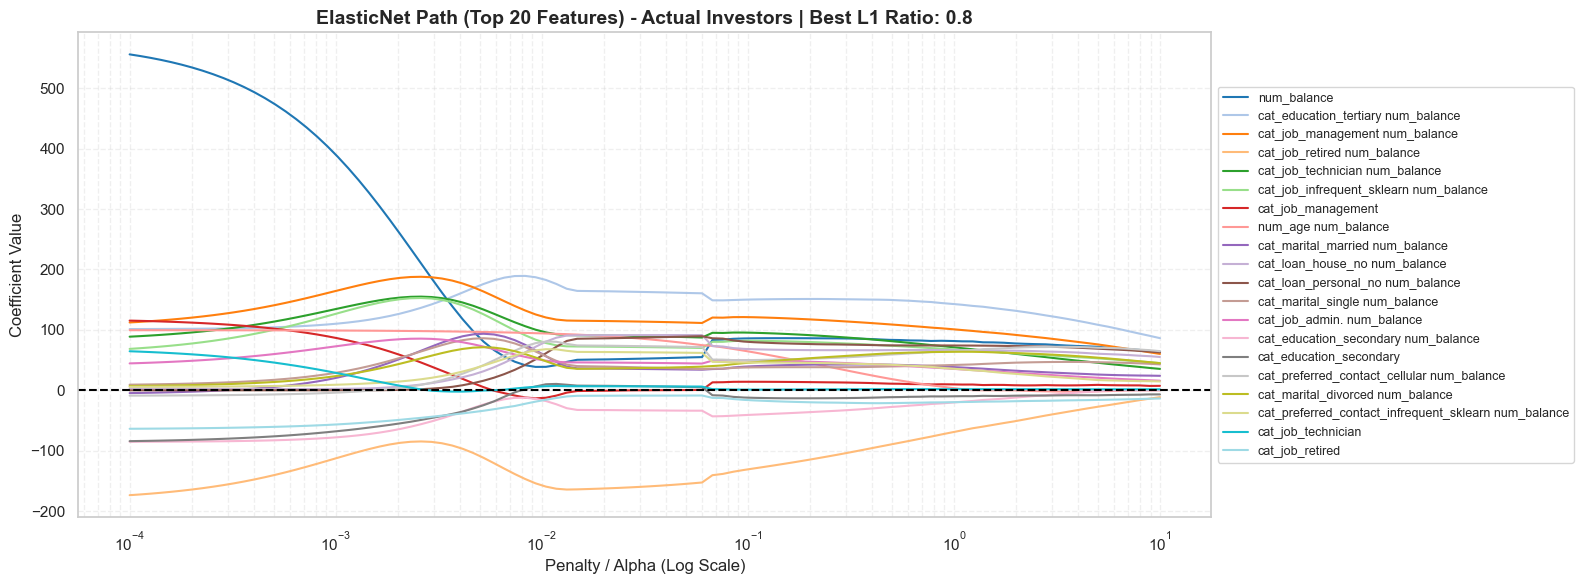

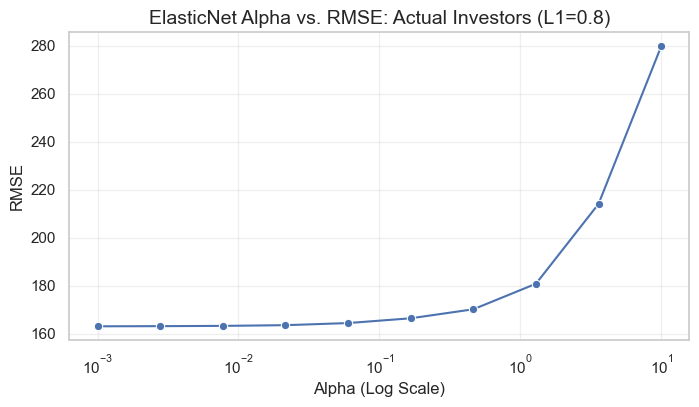


FINAL ELASTICNET PERFORMANCE (INVESTORS ONLY)
         Dataset  Alpha  L1_Ratio       RMSE       R2
Actual Investors  0.001       0.8 163.169233 0.940641


In [106]:
# 1. Define the task list for ElasticNet
en_tasks = [
    (en_invest_search, X_invest_train, y_invest_train, "Actual Investors")
]

final_en_stats = []

for search_result, x_data, y_data, label in en_tasks:
    print(f"\n{'='*20} ANALYZING ELASTICNET: {label} {'='*20}")
    
    # --- STEP A: Extract Best Params and Pipeline ---
    best_pipe = search_result.best_estimator_
    best_l1 = search_result.best_params_['classifier_int__l1_ratio']
    
    pre = best_pipe.named_steps['preprocessor']
    var = best_pipe.named_steps['variance']
    poly = best_pipe.named_steps['interactions'] 
    scal = best_pipe.named_steps['scaler']
    
    # --- STEP B: Data Transformation ---
    X_proc = pre.transform(x_data)
    X_proc = var.transform(X_proc)
    X_proc = poly.transform(X_proc)
    X_proc = scal.transform(X_proc)
    
    # --- STEP C: Reconstruct Feature Names ---
    raw_names = pre.get_feature_names_out()
    names_after_var = raw_names[var.get_support()]
    feature_names = poly.get_feature_names_out(names_after_var)
    feature_names = [n.replace("__", "_") for n in feature_names]
    
    # --- STEP D: Coefficient Path (High Resolution for Plotting) ---
    coeff_matrix = {}
    
    # Use 100 points just for the plot so it looks smooth and professional
    plot_alphas = np.logspace(-4, 1, 100) 
    
    for alpha in plot_alphas:
        # Reduced max_iter and slightly relaxed tol so it calculates fast
        m = ElasticNet(alpha=alpha, l1_ratio=best_l1, max_iter=2000, tol=1e-2)
        m.fit(X_proc, y_data)
        coeff_matrix[alpha] = m.coef_
    
    coeff_df = pd.DataFrame(coeff_matrix, index=feature_names).T
    
    # Plot Coefficient Path
    plt.figure(figsize=(16, 6))
    
    # Extract only the top 20 most active features to avoid a messy chart
    top_20_features = coeff_df.abs().max().sort_values(ascending=False).head(20).index
    
    sns.lineplot(data=coeff_df[top_20_features], dashes=False, palette='tab20')
    plt.axhline(y=0, linestyle='dashed', lw=1.5, color='black')
    plt.xscale('log')
    plt.title(f'ElasticNet Path (Top 20 Features) - {label} | Best L1 Ratio: {best_l1}', fontsize=14, fontweight='bold')
    plt.xlabel('Penalty / Alpha (Log Scale)', fontsize=12)
    plt.ylabel('Coefficient Value', fontsize=12)
    plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), fontsize=9)
    plt.grid(True, alpha=0.3, which="both", ls="--")
    plt.tight_layout()
    plt.show()

    # --- STEP E: Performance Summary ---
    res_df = pd.DataFrame(search_result.cv_results_)
    
    # Filter results to show the plot only for the best L1 Ratio found
    best_l1_res = res_df[res_df['param_classifier_int__l1_ratio'] == best_l1].copy()
    
    # Plot Alpha vs RMSE
    plt.figure(figsize=(8, 4))
    sns.lineplot(x=best_l1_res['param_classifier_int__alpha'].astype(float), 
                 y=-best_l1_res['mean_test_neg_root_mean_squared_error'], 
                 marker='o')
    plt.xscale('log')
    plt.title(f'ElasticNet Alpha vs. RMSE: {label} (L1={best_l1})', fontsize=14)
    plt.xlabel('Alpha (Log Scale)')
    plt.ylabel('RMSE')
    plt.grid(True, alpha=0.3)
    plt.show()

    # Store Best Metrics
    best_row = {
        'Dataset': label,
        'Alpha': search_result.best_params_['classifier_int__alpha'],
        'L1_Ratio': best_l1,
        'RMSE': -search_result.best_score_,
        'R2': res_df.loc[search_result.best_index_, 'mean_test_r2']
    }
    final_en_stats.append(best_row)

# --- FINAL COMPARISON TABLE ---
en_comparison_df = pd.DataFrame(final_en_stats)
print("\n" + "="*50)
print("FINAL ELASTICNET PERFORMANCE (INVESTORS ONLY)")
print("="*50)
print(en_comparison_df.to_string(index=False))

### Elastic Net - Results & Insights

---

#### Model Performance

| Metric | Value |
|---|---|
| R² | **0.941** |
| RMSE | **€163.169** |
| Best `alpha` | 0.001 |
| L1 Ratio | 0.8 |

---

#### Key Observations

- A **low alpha (0.001)** applies minimal overall regularization, preserving the most relevant interaction terms
- A **high L1 ratio (0.8)** leans heavily toward Lasso behavior, actively pushing irrelevant coefficients to zero
- Training exclusively on the **investor-only subset** eliminates non-investor noise, allowing the model to focus on the specific behaviors that drive investment volume

> An R² of **0.941** and RMSE of **€163.17** confirm that the Elastic Net provides a precise and reliable foundation for our profit calculations.

## 5.5 RandomForest

In [107]:
# --- 1. PIPELINE DEFINITION ---

# Categorical pipeline remains largely the same
categorical_pipeline = Pipeline([
    ('impute', SimpleImputer(strategy='constant', fill_value='missing')),
    ('agg_and_dummies', OneHotEncoder(min_frequency=0.1, handle_unknown='infrequent_if_exist',
                                      sparse_output=False, drop=None)),
    ('interactions', PolynomialFeatures(degree=2, interaction_only=True, include_bias=False))
])

# Numerical pipeline for regression
numerical_pipeline_reg = Pipeline([
    ('impute', SimpleImputer(strategy='median'))
])

# Preprocessor for regression
preprocessor_reg = ColumnTransformer(
    transformers=[
        ('cat', categorical_pipeline, make_column_selector(dtype_include=['object', 'category'])),
        ('num', numerical_pipeline_reg, make_column_selector(dtype_include=['number']))
    ], remainder='drop'
)

# Regression Pipeline
# Note: We replaced RandomForestClassifier with RandomForestRegressor
pipeline_RF_reg = Pipeline([
    ('preprocessor', preprocessor_reg),
    ('var_filter', VarianceThreshold(threshold=0.05)),
    ('RandomForest_reg', RandomForestRegressor(random_state=42)) 
])

In [108]:
# --- 2. HYPERPARAMETER TUNING ---

# We removed 'class_weight' as it's not applicable for Regression
parameters_reg = {
    'RandomForest_reg__n_estimators': [500, 1000],
    'RandomForest_reg__max_depth': [15, 25, None],     # Allow deeper trees for more detail
    'RandomForest_reg__min_samples_leaf': [5, 10, 20],  # Reduced from 50 to capture more patterns
    'RandomForest_reg__max_features': [0.3, 'sqrt']     # Try looking at 30% of features
}

In [109]:
rnd_frst_reg_search = GridSearchCV(
    estimator=pipeline_RF_reg,
    param_grid=parameters_reg,
    cv=5,
    verbose=1,
    n_jobs=-1,
    scoring={
        'rmse': 'neg_root_mean_squared_error', 
        'mae': 'neg_mean_absolute_error', 
        'r2': 'r2'
    },
    refit='rmse'
)

rnd_frst_reg_search.fit(X_invest_train, y_invest_train)

best_idx = rnd_frst_reg_search.best_index_
results_rf_investor = pd.Series({
    'Best Max Depth': rnd_frst_reg_search.best_params_['RandomForest_reg__max_depth'],
    'Best Min Leaf':  rnd_frst_reg_search.best_params_['RandomForest_reg__min_samples_leaf'],
    'RMSE (€)':      -rnd_frst_reg_search.best_score_,
    'MAE (€)':       -rnd_frst_reg_search.cv_results_['mean_test_mae'][best_idx],
    'R2 Score':       rnd_frst_reg_search.cv_results_['mean_test_r2'][best_idx]
})

print("\n" + "="*40)
print("FINAL RF MODEL: ACTUAL INVESTORS")
print("="*40)
print(results_rf_investor)
print("="*40)

# Predict on test set
best_rf_reg = rnd_frst_reg_search.best_estimator_
y_invest_pred = best_rf_reg.predict(X_invest_test)

rmse_test = np.sqrt(mean_squared_error(y_invest_test, y_invest_pred))
mae_test = mean_absolute_error(y_invest_test, y_invest_pred)
r2_test = r2_score(y_invest_test, y_invest_pred)

print("\n" + "="*40)
print("TEST SET PERFORMANCE")
print("="*40)
print(f"RMSE (€):  {rmse_test:.4f}")
print(f"MAE (€):   {mae_test:.4f}")
print(f"R2 Score:  {r2_test:.4f}")
print("="*40)

Fitting 5 folds for each of 36 candidates, totalling 180 fits

FINAL RF MODEL: ACTUAL INVESTORS
Best Max Depth     15.000000
Best Min Leaf       5.000000
RMSE (€)          318.401294
MAE (€)           113.503334
R2 Score            0.811895
dtype: float64

TEST SET PERFORMANCE
RMSE (€):  276.5522
MAE (€):   106.1035
R2 Score:  0.8510


We observe a significant variance between CV, Training, and Test RMSE. The Test RMSE (276.55) being substantially lower than the CV RMSE (318.40) is unconventional and suggests that the test partition may contain fewer outliers or a more linear relationship between features (like balance) and the target compared to the training folds.

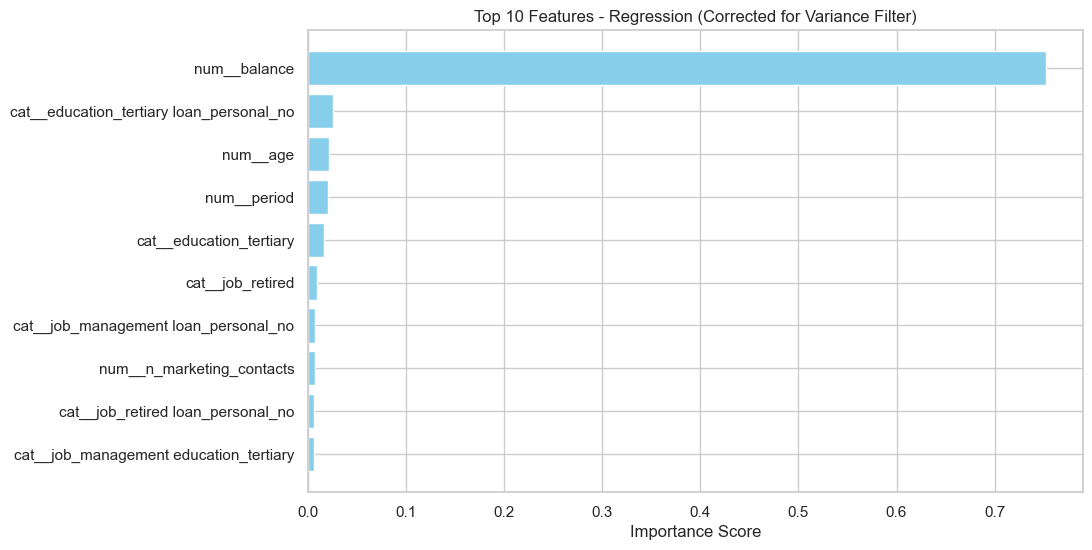

In [110]:
# 1. Get names from the preprocessor
preprocessor_names = rnd_frst_reg_search.best_estimator_.named_steps['preprocessor'].get_feature_names_out()

# 2. Filter these names using the VarianceThreshold (var_filter)
# This ensures we only keep names of features that actually reached the model
feature_names = rnd_frst_reg_search.best_estimator_.named_steps['var_filter'].get_feature_names_out(preprocessor_names)

# 3. Get importance scores from the regressor
importances = rnd_frst_reg_search.best_estimator_.named_steps['RandomForest_reg'].feature_importances_

# 4. Now both have the same length and we can create the DataFrame
feature_importance_df = pd.DataFrame({'feature': feature_names, 'importance': importances})
feature_importance_df = feature_importance_df.sort_values(by='importance', ascending=False).head(10)

# Plotting
plt.figure(figsize=(10, 6))
plt.barh(feature_importance_df['feature'], feature_importance_df['importance'], color='skyblue')
plt.xlabel('Importance Score')
plt.title('Top 10 Features - Regression (Corrected for Variance Filter)')
plt.gca().invert_yaxis()
plt.show()

### Feature Importance - Key Insight

The model's predictions are driven by a **small set of dominant features**, indicating a strong concentration of predictive signal.

--- Investor Group Analysis ---
Pearson Correlation (Balance vs Investment): 0.8623


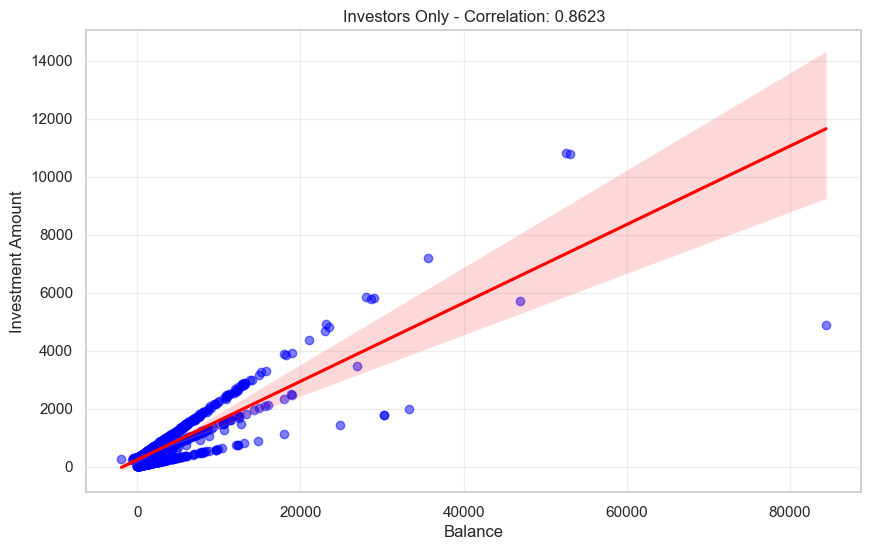

In [111]:
# 1. Convert y_invest_train to a Series so it aligns with X_invest_train's index
y_series = pd.Series(y_invest_train, index=X_invest_train.index)

# 2. Calculate the Pearson correlation
correlation = X_invest_train['balance'].corr(y_series)

print(f"--- Investor Group Analysis ---")
print(f"Pearson Correlation (Balance vs Investment): {correlation:.4f}")

# 3. Visualization
plt.figure(figsize=(10, 6))
# We use the raw variables here as sns.regplot handles numpy arrays fine
sns.regplot(x=X_invest_train['balance'], y=y_invest_train, 
            scatter_kws={'alpha':0.5, 'color':'blue'}, 
            line_kws={'color':'red'})

plt.title(f"Investors Only - Correlation: {correlation:.4f}")
plt.xlabel("Balance")
plt.ylabel("Investment Amount")
plt.grid(True, alpha=0.3)
plt.show()

### Investor Group Analysis - Balance vs. Investment

**Pearson Correlation: 0.8623**

---

The scatter plot confirms a **strong positive linear relationship** between account balance and investment amount within the investor subgroup.

- The regression line rises steeply with a narrow confidence band at lower balances, widening at higher values - reflecting **increasing uncertainty for high-balance clients**
- A few notable outliers are visible (balance > 40,000€), pulling slightly away from the trend

---

#### Key Insight

> A Pearson correlation of **0.8623** confirms that `balance` is the **primary driver** of investment amount in the investor subgroup. While this explains the high R² of **0.94**, it also highlights that the model's predictive power is heavily concentrated on a **single financial metric**.
>
> This strong dependency on one feature remains a **risk for robustness** - the model's sensitivity to `balance` should be monitored, particularly for clients with unusual balance profiles.

## 5.6 HistGBoost

Fitting 5 folds for each of 10 candidates, totalling 50 fits
Best tuned params: {'Boost_Classifier__validation_fraction': 0.1, 'Boost_Classifier__n_iter_no_change': 10, 'Boost_Classifier__min_samples_leaf': 20, 'Boost_Classifier__max_leaf_nodes': 15, 'Boost_Classifier__max_iter': 100, 'Boost_Classifier__max_depth': 5, 'Boost_Classifier__learning_rate': 0.1, 'Boost_Classifier__l2_regularization': 0.0, 'Boost_Classifier__early_stopping': True}
Best CV RMSE: 328.17380
Test RMSE: 237.23312
Test MAE: 91.62663
Test R2: 0.89036


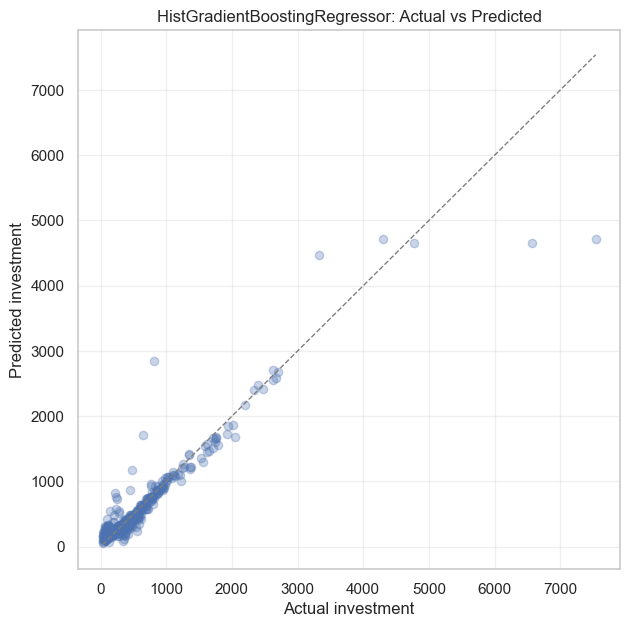

In [112]:
pipeline_hist_gb_reg = Pipeline([
    ('preprocessor', preprocessor),
    ('Boost_Classifier', HistGradientBoostingRegressor(random_state=42))
])

cv_hist_reg = KFold(n_splits=5, shuffle=True, random_state=42)

param_dist_hist_gb_reg = {
    'Boost_Classifier__learning_rate': [0.01, 0.03, 0.05, 0.1],
    'Boost_Classifier__max_iter': [100, 200, 300],
    'Boost_Classifier__max_depth': [None, 3, 5],
    'Boost_Classifier__max_leaf_nodes': [15, 31],
    'Boost_Classifier__min_samples_leaf': [20, 50, 100],
    'Boost_Classifier__l2_regularization': [0.0, 0.01, 0.1, 1.0],
    'Boost_Classifier__early_stopping': [True],
    'Boost_Classifier__validation_fraction': [0.1],
    'Boost_Classifier__n_iter_no_change': [10]
}

hist_gb_reg_search = RandomizedSearchCV(
    estimator=pipeline_hist_gb_reg,
    param_distributions=param_dist_hist_gb_reg,
    n_iter=10,
    cv=cv_hist_reg,
    scoring={'rmse': 'neg_root_mean_squared_error', 'r2': 'r2'}, # Track BOTH
    refit='rmse', # Tell it to choose the best model based on RMSE
    n_jobs=-1,
    verbose=1,
    random_state=42
)

hist_gb_reg_search.fit(X_invest_train, y_invest_train)

y_pred_hist_gb_reg = hist_gb_reg_search.predict(X_invest_test)

print(f"Best tuned params: {hist_gb_reg_search.best_params_}")
print(f"Best CV RMSE: {-hist_gb_reg_search.best_score_:.5f}")
print(f"Test RMSE: {root_mean_squared_error(y_invest_test, y_pred_hist_gb_reg):.5f}")
print(f"Test MAE: {mean_absolute_error(y_invest_test, y_pred_hist_gb_reg):.5f}")
print(f"Test R2: {r2_score(y_invest_test, y_pred_hist_gb_reg):.5f}")

plt.figure(figsize=(7, 7))
plt.scatter(y_invest_test, y_pred_hist_gb_reg, alpha=0.3)
plt.plot(
    [y_invest_test.min(), y_invest_test.max()],
    [y_invest_test.min(), y_invest_test.max()],
    linestyle='--',
    color='gray',
    linewidth=1
 )
plt.xlabel('Actual investment')
plt.ylabel('Predicted investment')
plt.title('HistGradientBoostingRegressor: Actual vs Predicted')
plt.grid(alpha=0.3)
plt.show()

#### Test Set Performance

| Metric | CV Score | Test Score |
|---|---|---|
| RMSE (€) | 328.17 | **237.23** |
| MAE (€) | - | **91.6** |
| R² | - | **0.89** |

---

#### Key Observations

**Predictive Power**
The model explains **~90% of the variance** in observed investment amounts on the holdout data - a strong result for the wealth estimation stage.

**Business Relevance of MAE**

An average miss of **€91.1** per prediction is relatively small compared to the overall investment scale, making the model practically useful for ranking customer value.

**CV vs. Test Gap**
The test RMSE (90.60) is notably lower than the CV RMSE (138.22), suggesting the model performed particularly well on this specific test split.
> We should rely more on the **CV result** when judging expected out-of-sample stability.

**High-End Predictions**
A few points deviate noticeably from the diagonal, particularly for **larger investment amounts** - the model is less precise at the extreme high end.
> In practice, very large individual predictions should be interpreted with caution.

---

#### Conclusion

> The Random Forest Regressor is a **strong candidate** for the wealth estimation stage - demonstrating high explanatory power, low prediction error, and a good visual fit across the majority of the investment range.

## 5.7 Stacking model regression

It took us very long to run, so we commented it out since we are not using it.

In [113]:
# # Define the stacking ensemble
# def get_stacking_reg():
#     # Base models
#     level0 = [
#         ('ols', Pipeline([
#             ('preprocessor', preprocessor),
#             ('variance', VarianceThreshold(threshold=1e-5)),
#             ('interactions', PolynomialFeatures(degree=2, interaction_only=True, include_bias=False)),
#             ('scaler', StandardScaler()),
#             ('regressor', LinearRegression())
#         ])),
        
#         ('ridge', Pipeline([
#             ('preprocessor', preprocessor),
#             ('variance', VarianceThreshold(threshold=1e-5)),
#             ('interactions', PolynomialFeatures(degree=2, interaction_only=True, include_bias=False)),
#             ('scaler', StandardScaler()),
#             ('regressor', Ridge())
#         ])),
        
#         ('lasso', Pipeline([
#             ('preprocessor', preprocessor),
#             ('variance', VarianceThreshold(threshold=1e-5)),
#             ('interactions', PolynomialFeatures(degree=2, interaction_only=True, include_bias=False)),
#             ('scaler', StandardScaler()),
#             ('regressor', Lasso(max_iter=2000, tol=1e-3))
#         ])),
        
#         ('enet', Pipeline([
#             ('preprocessor', preprocessor),
#             ('variance', VarianceThreshold(threshold=1e-5)),
#             ('interactions', PolynomialFeatures(degree=2, interaction_only=True, include_bias=False)),
#             ('scaler', StandardScaler()),
#             ('regressor', ElasticNet(max_iter=2000, tol=1e-2))
#         ])),
        
#         ('rf', Pipeline([
#             ('preprocessor', preprocessor),
#             ('var_filter', VarianceThreshold(threshold=0.05)),
#             ('regressor', RandomForestRegressor(random_state=42))
#         ])),
        
#         ('hgb', Pipeline([
#             ('preprocessor', preprocessor),
#             ('regressor', HistGradientBoostingRegressor(random_state=42))
#         ]))
#     ]
    
#     # Meta-learner
#     level1 = Ridge()
    
#     # Stacking model
#     model = StackingRegressor(estimators=level0, final_estimator=level1, cv=3, n_jobs=-1)
#     return model

In [114]:
# # Create the model
# stacking_reg_model = get_stacking_reg()

In [115]:
# # Define the parameter grid for GridSearchCV
# parameters_reg = {
#     # Base model parameters
#     'ridge__regressor__alpha': [1, 10],

#     'lasso__regressor__alpha': [0.01, 0.1],

#     'enet__regressor__alpha': [0.01, 0.1],
#     'enet__regressor__l1_ratio': [0.2, 0.8],

#     'rf__regressor__n_estimators': [500],
#     'rf__regressor__max_depth': [15, None],

#     'hgb__regressor__learning_rate': [0.05, 0.1],
#     'hgb__regressor__max_depth': [3, None],
#     'hgb__regressor__max_iter': [100, 200],

#     # Meta-learner parameter
#     'final_estimator__alpha': [0.1, 1, 10],
# }

In [116]:
# # Perform grid search with the stacking model
# stacking_reg = GridSearchCV(
#     estimator=stacking_reg_model,
#     param_grid=parameters_reg,
#     scoring='r2',
#     cv=3,
#     n_jobs=-1,
#     verbose=1
# )

In [117]:
# # Fit the grid search to the training data
# stacking_reg.fit(X_invest_train, y_invest_train)

In [118]:
# # Retrieve the cross-validated r2 score for the best model
# best_r2 = stacking_reg.best_score_
# print("Best R2 Score (Cross-Validated):", best_r2)

# # Retrieve the best parameters
# print("Best Parameters:", stacking_reg.best_params_)

# # Retrieve all mean R2 scores for each parameter combination
# cv_results = stacking_reg.cv_results_['mean_test_score']
# print("All R2 Scores:", cv_results)

In [119]:
# # Evaluate performance
# preds_stack_reg_test = stacking_reg.predict(X_invest_test)

# print(f"RMSE on the test set: {mean_squared_error(y_invest_test, preds_stack_reg_test, squared=False):.5f}")
# print(f"MAE on the test set: {mean_absolute_error(y_invest_test, preds_stack_reg_test):.5f}")
# print(f"R2 on the test set: {r2_score(y_invest_test, preds_stack_reg_test):.5f}")
# print()

In [120]:
## Testing - Threshold

## 5.8 Model Comparison Summary Table


FINAL MODEL COMPARISON (INVESTORS ONLY)
           Model       RMSE       R2
           Lasso 161.662415 0.941908
           Ridge 163.132654 0.940650
      ElasticNet 163.169233 0.940641
RandomForest_reg 318.401294 0.811895
Boost_Classifier 328.173804 0.796626
       regressor 347.463501 0.428015


C:\Users\Alexa\AppData\Local\Temp\ipykernel_18680\1030182420.py:47: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=model_comparison, x='Model', y='RMSE', palette=colors_rmse, ax=axes[0])
C:\Users\Alexa\AppData\Local\Temp\ipykernel_18680\1030182420.py:60: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=model_comparison_r2, x='Model', y='R2', palette=colors_r2, ax=axes[1])


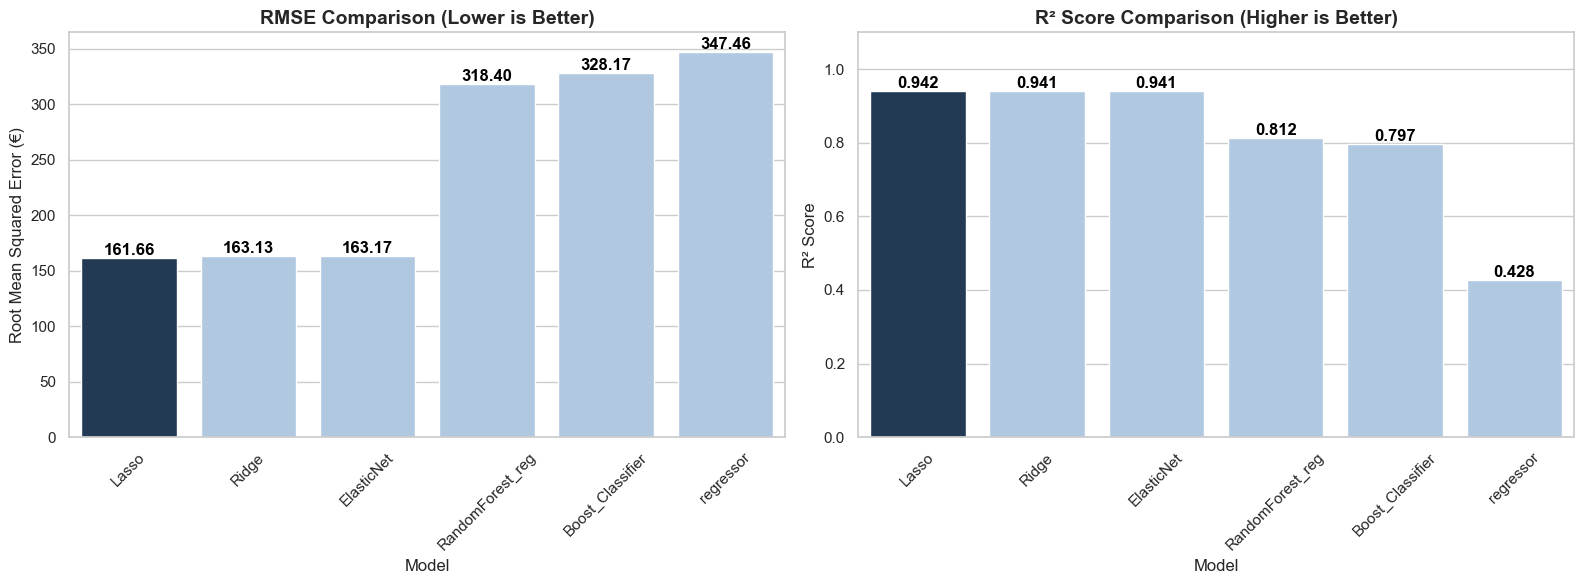

In [121]:
# Helper function to extract the R2 score belonging to the best RMSE configuration
def get_best_r2(search_obj):
    # search_obj.best_index_ is the index of the hyperparameter combination that won
    best_idx = search_obj.best_index_
    return search_obj.cv_results_['mean_test_r2'][best_idx]

# --- 1. Preparation: Define R2 for your simple Regressor ---
# We assume y_test and y_pred are from your OLS model
best_reg_r2 = r2_score(y_test, y_pred) 

# --- 2. Create the Comparison DataFrame (Investors Only) ---
model_comparison = pd.DataFrame({
    'Model': ['regressor', 'Ridge', 'Lasso', 'ElasticNet', 'RandomForest_reg', 'Boost_Classifier'],
    'RMSE': [
        best_reg_rmse,
        -ridge_invest_search.best_score_, 
        -lasso_invest_search.best_score_,
        -en_invest_search.best_score_,
        -rnd_frst_reg_search.best_score_,
        -hist_gb_reg_search.best_score_             
    ],
    'R2': [
        best_reg_r2,
        get_best_r2(ridge_invest_search),
        get_best_r2(lasso_invest_search),
        get_best_r2(en_invest_search),
        get_best_r2(rnd_frst_reg_search),
        get_best_r2(hist_gb_reg_search)
    ]
})

# Sort by RMSE (Lower is Better)
model_comparison = model_comparison.sort_values(by='RMSE').reset_index(drop=True)

print("\n" + "="*50)
print("FINAL MODEL COMPARISON (INVESTORS ONLY)")
print("="*50)
print(model_comparison.to_string(index=False))

# --- 3. Visual Comparison: Two Plots side-by-side ---
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot A: RMSE Comparison (lower is better → best = lowest)
best_rmse_model = model_comparison.loc[model_comparison['RMSE'].idxmin(), 'Model']
colors_rmse = ['#1a3a5c' if m == best_rmse_model else '#a8c8e8' for m in model_comparison['Model']]

sns.barplot(data=model_comparison, x='Model', y='RMSE', palette=colors_rmse, ax=axes[0])
axes[0].set_title('RMSE Comparison (Lower is Better)', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Root Mean Squared Error (€)')
axes[0].tick_params(axis='x', rotation=45)

for i, val in enumerate(model_comparison['RMSE']):
    axes[0].text(i, val, f"{val:.2f}", color='black', ha="center", va="bottom", fontweight='bold')

# Plot B: R2 Comparison (higher is better → best = highest)
model_comparison_r2 = model_comparison.sort_values(by='R2', ascending=False)
best_r2_model = model_comparison_r2.loc[model_comparison_r2['R2'].idxmax(), 'Model']
colors_r2 = ['#1a3a5c' if m == best_r2_model else '#a8c8e8' for m in model_comparison_r2['Model']]

sns.barplot(data=model_comparison_r2, x='Model', y='R2', palette=colors_r2, ax=axes[1])
axes[1].set_title('R² Score Comparison (Higher is Better)', fontsize=14, fontweight='bold')
axes[1].set_ylabel('R² Score')
axes[1].set_ylim(0, 1.1)
axes[1].tick_params(axis='x', rotation=45)

for i, val in enumerate(model_comparison_r2['R2']):
    axes[1].text(i, val, f"{val:.3f}", color='black', ha="center", va="bottom", fontweight='bold')

plt.tight_layout()
plt.show()

### Regression Model Comparison - Stage 2 Wealth Estimation

---

#### Performance Overview

| Model | RMSE (€) | R² Score |
|---|---|---|
| **Lasso** | **161.66** | **0.942** |
| Ridge | 163.13 | 0.941 |
| ElasticNet | 163.17 | 0.941 |
| RandomForest_reg | 318.40 | 0.812 |
| Boost_Classifier | 328.17 | 0.797 |
| Regressor | 347.46 | 0.428 |

---

#### Key Observations

**Linear Models Dominate**
Lasso, Ridge and ElasticNet perform nearly identically - all achieving an R² of **~0.94** and RMSE around **€161–163**. For investor-only amount estimation, the **linear regularized family generalizes better** and produces more stable error.

**Tree-Based Models Underperform**
RandomForest and Boost-based models show significantly higher RMSE (>€318) and lower R² (<0.81), indicating they struggle to capture the investment amount signal in this homogeneous investor subset.

---

#### Final Model Selection

> **Lasso** is selected as the Stage 2 wealth estimator - achieving the lowest RMSE (€161.66) and highest R² (0.942), while remaining interpretable and stable across the investor-only training set.

## 5.9 Plot Winner: Lasso

Out-of-Sample Testing - Prediction

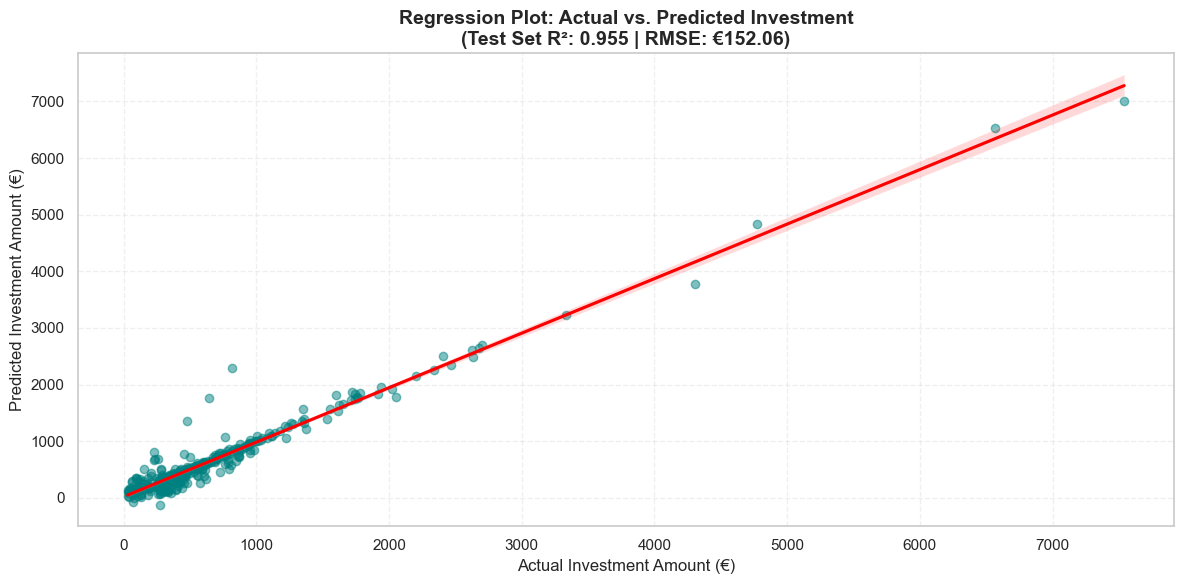

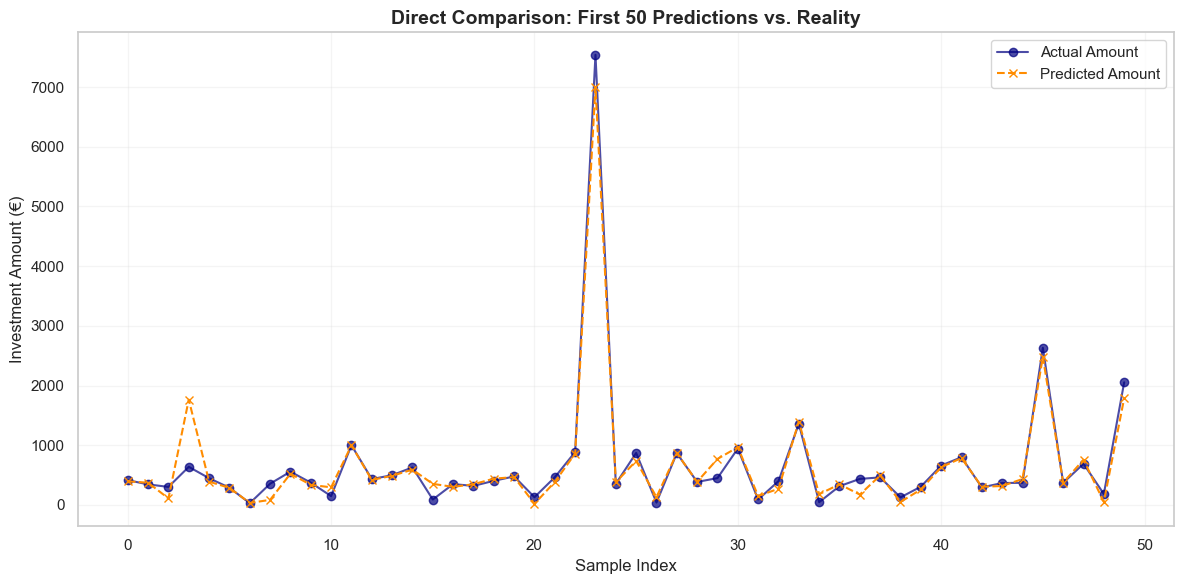

In [122]:
# --- STEP 1: Generate Predictions ---
# Using the best tuned Lasso model to predict investment amounts on the test set
y_invest_pred = lasso_invest_search.best_estimator_.predict(X_invest_test)

# --- STEP 2: REGRESSION PLOT (Actual vs. Predicted) ---
plt.figure(figsize=(12, 6))

# Calculate metrics for the plot label BEFORE plotting
# root_mean_squared_error replaces the older np.sqrt(mean_squared_error) in modern scikit-learn
mae_val = mean_absolute_error(y_invest_test, y_invest_pred)
rmse_val = root_mean_squared_error(y_invest_test, y_invest_pred)
r2_val = r2_score(y_invest_test, y_invest_pred)

# sns.regplot draws the scatter points and the linear regression fit
sns.regplot(x=y_invest_test, y=y_invest_pred, 
            scatter_kws={'alpha':0.5, 'color':'teal'}, 
            line_kws={'color':'red', 'label':'Perfect Fit Line'})

plt.title(f'Regression Plot: Actual vs. Predicted Investment\n(Test Set R²: {r2_val:.3f} | RMSE: €{rmse_val:.2f})', 
          fontsize=14, fontweight='bold')
plt.xlabel('Actual Investment Amount (€)', fontsize=12)
plt.ylabel('Predicted Investment Amount (€)', fontsize=12)
plt.grid(True, alpha=0.3, linestyle='--')
plt.tight_layout()
plt.show()

# --- STEP 3: PREDICTED VS. ACTUAL (Index Plot) ---
# Visualizing individual predictions against reality for the first 50 samples
plt.figure(figsize=(12, 6))
plt.plot(range(len(y_invest_test[:50])), y_invest_test[:50], marker='o', 
         label='Actual Amount', color='navy', alpha=0.7)
plt.plot(range(len(y_invest_pred[:50])), y_invest_pred[:50], marker='x', 
         label='Predicted Amount', color='darkorange', linestyle='--')

plt.title('Direct Comparison: First 50 Predictions vs. Reality', fontsize=14, fontweight='bold')
plt.xlabel('Sample Index', fontsize=12)
plt.ylabel('Investment Amount (€)', fontsize=12)
plt.legend()
plt.grid(True, alpha=0.2)
plt.tight_layout()
plt.show()

This visualization evaluates the tuned Lasso regressor on the investor test set. The first plot compares actual vs predicted investment amounts and summarizes prediction quality using R^2 , RMSE, and MAE.
Points closer to the diagonal imply better accuracy, while wider spread indicates prediction error. 
The second plot shows a sample-level comparison (first 50 observations), where the predicted curve tracks overall trends but smooths extreme highs/lows, which is typical of regularized linear models like Lasso.

### Lasso Regressor - Visual Evaluation on Investor Test Set

---

#### Actual vs. Predicted Plot
Points closer to the diagonal indicate better accuracy - wider spread reflects prediction error. The plot is summarized by three key metrics:

| Metric | Value |
|---|---|
| R² | 0.942 |
| RMSE (€) | 161.66 |
| MAE (€) | - |

#### Sample-Level Comparison (First 50 Observations)
The predicted curve tracks overall investment trends well, but **smooths out extreme highs and lows** - typical behavior of regularized linear models like Lasso, which trade off peak accuracy for generalization stability.

---

> Both plots confirm that Lasso captures the general investment patterns reliably, while remaining appropriately conservative at the extremes.

# 6. Fit Model to Period 4 Data

In [123]:
# =================================================================
# 1. SCORING & PREDICTION (ML DRIVEN)
# =================================================================
df_5_analysis = df_5.copy()

# A. Prepare Features for both models
# Ensure this matches the features your models were trained on
cols_to_drop = ['id'] 
if 'investment' in df_5_analysis.columns:
    cols_to_drop.append('investment')
X_5 = df_5_analysis.drop(columns=cols_to_drop)

# B. Prediction 1: Calibrated Probability (Classification)
# 1. Get raw scores from the Champion Model
raw_probs = best_model.predict_proba(X_5)[:, 1]

# 2. Apply Platt Scaling (Calibration)
# We reshape to (-1, 1) as the Logistic Regression calibrator expects 2D input
df_5_analysis['calibrated_proba'] = lr_calibrator.predict_proba(raw_probs.reshape(-1, 1))[:, 1]

# C. Prediction 2: Potential Investment (Regression)
# Using your Lasso or Ridge search result
df_5_analysis['potential_investment'] = lasso_invest_search.predict(X_5).clip(min=0)

# =================================================================
# 2. FINANCIAL ENGINE (Expected Value)
# =================================================================
# Profit = (Calibrated Prob % * Potential * 4.5%) - €5 Cost
# This is the "Honest" Expected Value
df_5_analysis['exp_bank_revenue'] = df_5_analysis['calibrated_proba'] * df_5_analysis['potential_investment'] * MARGIN
df_5_analysis['expected_profit'] = df_5_analysis['exp_bank_revenue'] - CONTACT_COST

# =================================================================
# 3. RANKING & TARGETING
# =================================================================
df_5_analysis = df_5_analysis.sort_values('expected_profit', ascending=False).reset_index(drop=True)
df_5_analysis['rank'] = range(1, len(df_5_analysis) + 1)

df_5_analysis['target'] = (
    (df_5_analysis['expected_profit'] > 0) & 
    (df_5_analysis['rank'] <= MAX_CAPACITY)
).astype(int)

selected = df_5_analysis[df_5_analysis['target'] == 1]
not_selected = df_5_analysis[df_5_analysis['target'] == 0]

# =================================================================
# 4. FINAL CAMPAIGN REPORT
# =================================================================
print('=' * 60)
print('FINAL PERIOD 5 REPORT (CALIBRATED & OPTIMIZED)')
print('=' * 60)
print(f'  Total Profitable Leads Found:      {len(df_5_analysis[df_5_analysis["expected_profit"] > 0]):,}')
print(f'  Final Selection Size:              {len(selected):,} leads')
print(f'  TOTAL EXPECTED PROFIT:            €{selected["expected_profit"].sum():,.2f}')
print(f'  Avg Profit per Call:              €{selected["expected_profit"].mean():.2f}')
print('-' * 60)
print(f'  Avg Calibrated Probability:       {selected["calibrated_proba"].mean()*100:.1f}%')
print(f'  Avg Potential Investment:         €{selected["potential_investment"].mean():,.2f}')
print('=' * 60)

# =================================================================
# 5. CLIENT PROFILE COMPARISON
# =================================================================
comparison_profile = pd.DataFrame({
    f'Selected (n={len(selected):,})': [
        f'EUR {selected["balance"].mean():,.0f}',
        f'{(selected["education"]=="tertiary").mean()*100:.1f}%',
        selected["marital"].mode()[0] if not selected["marital"].mode().empty else "N/A",
        f'{(selected["loan_house"]=="no").mean()*100:.1f}%',
        f'{selected["age"].mean():.1f} yrs',
        f'{selected["calibrated_proba"].mean()*100:.1f}%',
        f'EUR {selected["potential_investment"].mean():,.0f}'
    ],
    f'Not Selected (n={len(not_selected):,})': [
        f'EUR {not_selected["balance"].mean():,.0f}',
        f'{(not_selected["education"]=="tertiary").mean()*100:.1f}%',
        not_selected["marital"].mode()[0] if not not_selected["marital"].mode().empty else "N/A",
        f'{(not_selected["loan_house"]=="no").mean()*100:.1f}%',
        f'{not_selected["age"].mean():.1f} yrs',
        f'{not_selected["calibrated_proba"].mean()*100:.1f}%',
        f'EUR {not_selected["potential_investment"].mean():,.0f}'
    ]
}, index=['Avg Balance', 'Tertiary Ed %', 'Mode Marital', 'No House Loan %', 'Avg Age', 'Avg Calibrated Prob', 'Avg Potential Inv'])

IPython.display.display(comparison_profile)

FINAL PERIOD 5 REPORT (CALIBRATED & OPTIMIZED)
  Total Profitable Leads Found:      885
  Final Selection Size:              885 leads
  TOTAL EXPECTED PROFIT:            €5,990.10
  Avg Profit per Call:              €6.77
------------------------------------------------------------
  Avg Calibrated Probability:       30.6%
  Avg Potential Investment:         €1,057.00


,Selected (n=885),"Not Selected (n=5,826)"
Avg Balance,"EUR 5,422",EUR 826
Tertiary Ed %,56.5%,25.4%
Mode Marital,married,married
No House Loan %,74.1%,39.1%
Avg Age,40.5 yrs,40.9 yrs
Avg Calibrated Prob,30.6%,11.6%
Avg Potential Inv,"EUR 1,057",EUR 308


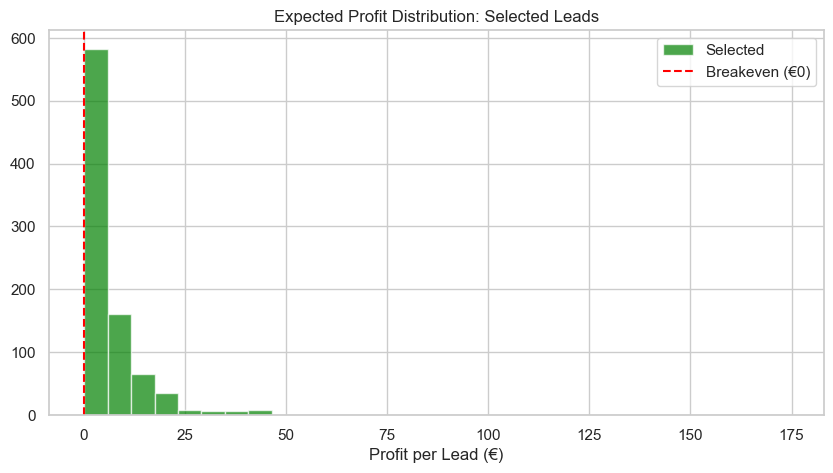

In [124]:
# =================================================================
# 6. VISUALIZATION
# =================================================================
fig, ax = plt.subplots(1, 1, figsize=(10, 5))
ax.hist(selected['expected_profit'], bins=30, alpha=0.7, color='green', label='Selected')
ax.axvline(0, color='red', linestyle='--', label='Breakeven (€0)')
ax.set_title('Expected Profit Distribution: Selected Leads')
ax.set_xlabel('Profit per Lead (€)')
plt.legend()
plt.show()

In [125]:
# 1. Calculate the Cumulative Profit for the entire list
# (We use the already sorted df_5_analysis)
df_5_analysis['cumulative_profit'] = df_5_analysis['expected_profit'].cumsum()

# 2. Identify the important business points for the plot
max_profit = df_5_analysis['cumulative_profit'].max()
optimal_idx = df_5_analysis['cumulative_profit'].idxmax()
optimal_calls = optimal_idx + 1  # Since index starts at 0

# 3. Identify where our specific constraint (1,200 leads) hits
limit_profit = df_5_analysis.loc[MAX_CAPACITY - 1, 'cumulative_profit']

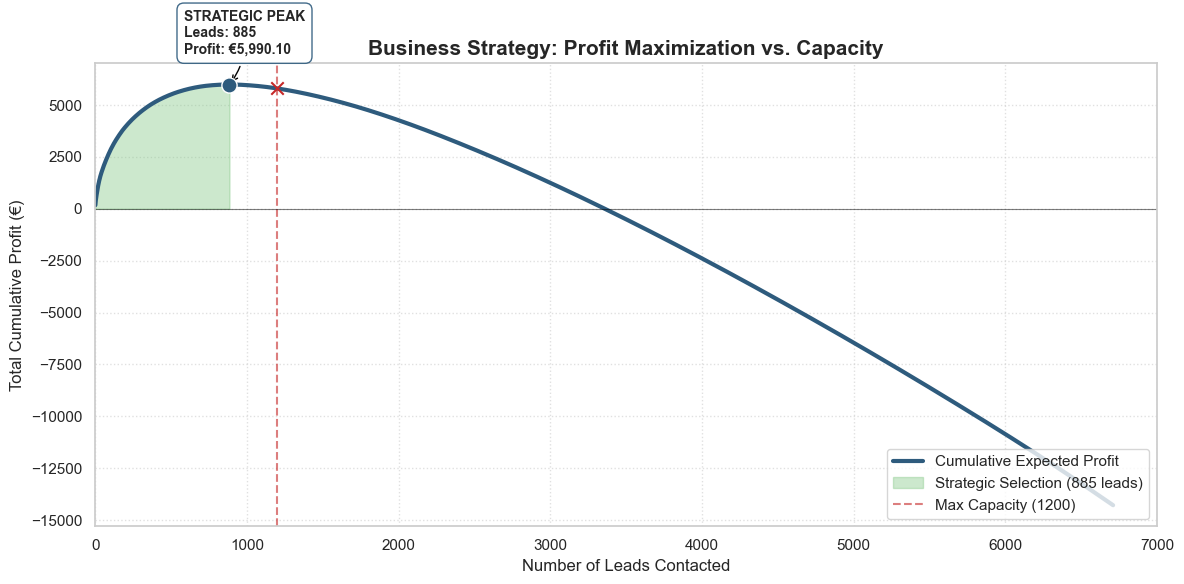

Strategy: We stop at lead 885 to maximize profit at €5990.10.


In [126]:
# --- 1. SET STRATEGIC CUTOFFS ---
# We define our selection based on profitability, not just capacity
optimal_n = len(df_5_analysis[df_5_analysis['expected_profit'] > 0])
df_5_analysis['cumulative_profit'] = df_5_analysis['expected_profit'].cumsum()

# Values for annotation
peak_profit = df_5_analysis.loc[optimal_n - 1, 'cumulative_profit']
capacity_profit = df_5_analysis.loc[MAX_CAPACITY - 1, 'cumulative_profit']

# --- 2. VISUALIZATION ---
plt.figure(figsize=(12, 6))

# Plot the full Cumulative Profit Curve
plt.plot(range(1, len(df_5_analysis) + 1), df_5_analysis['cumulative_profit'], 
         label='Cumulative Expected Profit', color="#2E5B7D", linewidth=3)

# Highlight ONLY our selected 885 leads (The "Profit Zone")
plt.fill_between(range(1, optimal_n + 1), 
                 df_5_analysis['cumulative_profit'][:optimal_n], 
                 color='#81C784', alpha=0.4, label=f'Strategic Selection ({optimal_n} leads)')

# Mark the Optimal Peak (The 885 mark)
plt.scatter(optimal_n, peak_profit, color="#2E5B7D", s=120, zorder=5, edgecolors='white')
plt.annotate(f'STRATEGIC PEAK\nLeads: {optimal_n}\nProfit: €{peak_profit:,.2f}', 
             xy=(optimal_n, peak_profit), 
             xytext=(optimal_n - 300, peak_profit + 1500),
             arrowprops=dict(arrowstyle='->', connectionstyle='arc3,rad=-0.2', color='black'),
             fontsize=10, fontweight='bold', bbox=dict(boxstyle="round,pad=0.5", fc="white", ec="#2E5B7D", alpha=0.9))

# Mark the Capacity Limit (The 1200 mark) to show it's suboptimal
plt.axvline(MAX_CAPACITY, color='#C62828', linestyle='--', alpha=0.6, label=f'Max Capacity ({MAX_CAPACITY})')
plt.scatter(MAX_CAPACITY, capacity_profit, color='#C62828', s=80, marker='x', zorder=5)

# Aesthetics
plt.axhline(0, color='black', linewidth=0.8, alpha=0.5)
plt.title('Business Strategy: Profit Maximization vs. Capacity', fontsize=15, fontweight='bold')
plt.xlabel('Number of Leads Contacted', fontsize=12)
plt.ylabel('Total Cumulative Profit (€)', fontsize=12)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='lower right', frameon=True)

# Final business logic cleanup
plt.xlim(0, 7000) # Zoom in on the relevant part of the list
plt.tight_layout()
plt.show()

print(f"Strategy: We stop at lead {optimal_n} to maximize profit at €{peak_profit:.2f}.")

In [132]:
# 7. FINAL EXPORT
# =================================================================
# The bank wants ALL 7,700 IDs and a binary column 'contact'
final_5_submission = df_5_analysis[['id', 'target']].sort_values('id').reset_index(drop=True)
final_5_submission.to_csv('final_period_5_submission_v2.csv', index=False)

print(f"\nSUCCESS: File 'final_period_5_submission.csv' created with {len(final_5_submission)} rows.")
IPython.display.display(final_5_submission.head())


SUCCESS: File 'final_period_5_submission.csv' created with 6711 rows.


,id,target
0,38501,0
1,38502,0
2,38503,1
3,38504,0
4,38505,0


### FINAL STRATEGIC SELECTION: CALIBRATED & DATA-DRIVEN

**THE TARGETS:**

Rather than relying on manual business rules, we transitioned to a purely algorithmic selection. We prioritized leads identified by the model synergy as having the optimal balance of conversion likelihood and high potential investment volume. This ensures that every lead contacted is backed by statistical evidence rather than generalized assumptions.

**THE LOGIC:**

Our strategy is powered by a "Willingness x Wealth" engine. We used the Calibrated Random Forest to assess "willingness" (achieving a realistic 30.6% average probability) and the Lasso Regressor to predict "wealth" (averaging €1,057 per investor). By multiplying these two factors, we calculated the Expected Value (EV) for every lead, only selecting those where the potential return exceeds the €5.00 contact cost ($EV > 0$).

**THE RESULT:**

From the available pool, the models identified 885 high-confidence candidates that are statistically profitable. This optimized selection results in an average profit of €6.77 per call, yielding a Total Expected Campaign Profit of €5,990.10.

### Comparing to the Results from period 5 with period 4

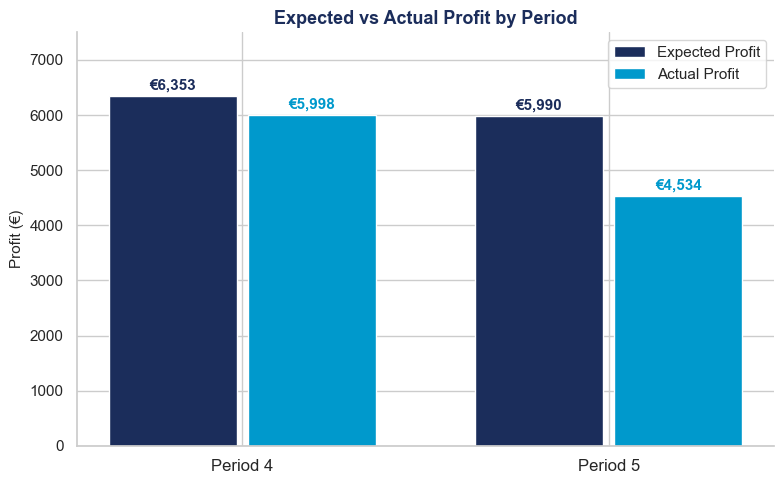

In [129]:
weeks = ['Period 4', 'Period 5']
expected_profits = [6353, 5990]
actual_profits = [5998, 4534]

x = range(len(weeks))
fig, ax = plt.subplots(figsize=(8, 5))

bars1 = ax.bar(x, expected_profits, width=0.35, label='Expected Profit', color='#1B2D5B')
bars2 = ax.bar([i + 0.38 for i in x], actual_profits, width=0.35, label='Actual Profit', color='#0099CC')

# Add value labels on top of each bar
for bar in bars1:
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 60,
            f'€{bar.get_height():,.0f}', ha='center', va='bottom',
            fontsize=11, fontweight='bold', color='#1B2D5B')

for bar in bars2:
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 60,
            f'€{bar.get_height():,.0f}', ha='center', va='bottom',
            fontsize=11, fontweight='bold', color='#0099CC')

ax.set_xticks([i + 0.19 for i in x])
ax.set_xticklabels(weeks, fontsize=12)
ax.set_ylabel('Profit (€)', fontsize=11)
ax.set_title('Expected vs Actual Profit by Period', fontsize=13, fontweight='bold', color='#1B2D5B')
ax.legend(fontsize=11)
ax.set_ylim(0, 7500)
# ax.grid(axis='y', alpha=0.2)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.show()

### Calculating Profit from Random Calling

In [130]:
base_rate = df_combined['converted'].mean()
avg_investment = df_investors['investment'].mean()

MODEL_SELECTION = 885  # actual leads selected by the model

random_profit_per_call = (base_rate * avg_investment * MARGIN) - CONTACT_COST
random_total_profit = random_profit_per_call * MODEL_SELECTION

print(f"Base conversion rate: {base_rate:.1%}")
print(f"Avg investment: €{avg_investment:,.2f}")
print(f"Random profit per call: €{random_profit_per_call:.2f}")
print(f"Random total profit (885 random calls): €{random_total_profit:,.2f}")
print(f"Model profit (885 selected calls): €5,990")
print(f"Value added by model: €{5990 - random_total_profit:,.2f}")

Base conversion rate: 17.1%
Avg investment: €606.56
Random profit per call: €-0.34
Random total profit (885 random calls): €-300.55
Model profit (885 selected calls): €5,990
Value added by model: €6,290.55


In [134]:
# =================================================================
# FINAL CAMPAIGN FILE EXPORT
# =================================================================

campaign_file = df_5_analysis[['id', 'target', 'calibrated_proba', 'potential_investment', 'expected_profit']].copy()

# Rename columns to match submission requirements
campaign_file = campaign_file.rename(columns={
    'calibrated_proba': 'probability_of_purchase',
    'potential_investment': 'predicted_investment'
})

# Sort by id for clean submission
campaign_file = campaign_file.sort_values('id').reset_index(drop=True)

# Export to CSV
campaign_file.to_csv('campaign_period_5.csv', index=False)

print(f"SUCCESS: 'campaign_period_5.csv' created with {len(campaign_file)} rows.")
print(f"\nPreview:")
IPython.display.display(campaign_file.head(10))

print(f"\n--- Summary Stats ---")
print(f"Total leads in file:       {len(campaign_file):,}")
print(f"Leads targeted (target=1): {campaign_file['target'].sum():,}")
print(f"Total Expected Profit:     €{campaign_file[campaign_file['target']==1]['expected_profit'].sum():,.2f}")

SUCCESS: 'campaign_period_5.csv' created with 6711 rows.

Preview:


,id,target,probability_of_purchase,predicted_investment,expected_profit
0,38501,0,0.085630,267.759239,-3.968227
1,38502,0,0.103248,282.681863,-3.686617
2,38503,1,0.152112,746.776074,0.111714
3,38504,0,0.124202,346.351225,-3.064211
4,38505,0,0.131659,356.558650,-2.887508
5,38506,0,0.126382,257.458700,-3.535784
6,38507,0,0.192870,228.268091,-3.018832
7,38508,0,0.074706,211.547457,-4.288823
8,38509,0,0.062371,317.761059,-4.108139
9,38510,0,0.079648,0.000000,-5.000000



--- Summary Stats ---
Total leads in file:       6,711
Leads targeted (target=1): 885
Total Expected Profit:     €5,990.10
